# TQP × Temporal Event Graph v0.3 — 검출기 보정 + TQP(P) 대 직접 Python(B2) 비교

| 계층 | 역할 | 이 노트북의 확인 내용 | 절 |
|---|---|---|---|
| Temporal Relation Grounding | 시간 접속사 의미와 사건 순서 해석 | P와 B2의 관계·방향 정확도, 접속사×어순 분해 | 7–8 |
| Temporal Query Plan | 자연어 → 실행 가능한 관계 구조 | 스키마 유효율, 슬롯 규칙 준수율 | 7–8 |
| Temporal Event Graph | 주행 데이터 → 사건·관계 그래프 | v0.2 대 v0.3 검출기 비교, 시각 검증 | 4 |
| Graph Query Execution | 관계 패턴 → 장면 검색 | Interval과의 일치, 시간·메모리, 임계값 민감도 | 5–6 |
| End-to-end | 자연어 → TQP → 검색 결과 | 프롬프트 변형별 검색 결과 일치율 | 9 |

**v0.2 결과에서 반영한 사항**
1. **검출기**: 3초 미만 트랙 제외, 트랙 양 끝 0.5초에서 가속도·회전 사건 제외, 간격 1초 이하의 같은 유형 사건 병합, 완만한 감속·가속(2초 이상, 속도 변화 2 m/s 이상) 추가. v0.2 검출기를 같은 데이터로 다시 돌려 나란히 비교합니다.
2. **LLM 비교의 혼동 요인 제거**: 프롬프트 3종(v0.2 원본 / 예시 없음 / 접속사 균형 예시)마다 **P(TQP JSON)와 B2(직접 Python 함수)** 를 같은 문장 72개로 생성합니다. 예시 문장은 P와 B2에 동일하게 쓰고, 평가 문장과 겹치지 않습니다.
3. **B2 채점**: 생성된 함수를 AST 검사와 제한된 실행 환경에서 동일한 탐침 트랙 7종(X→Y, Y→X, 동시, 멀리 떨어짐, X만, Y만, 무관 유형)에 실행하고, 수락 패턴에서 관계와 방향을 추론합니다. P도 같은 탐침으로 채점합니다.
4. **통계**: 정확도에 95% Wilson 신뢰구간, P 대 B2에는 정확 McNemar 검정을 붙입니다.
5. **임계값 민감도**: THEN 최대 간격(3/5/7초) × WHILE 겹침 비율(0.6/0.8/1.0)별 핵심 질의 결과 수를 표로 만듭니다.

**실행**: 런타임 → 런타임 유형 변경 → **T4 GPU** → 모두 실행. v0.2에서 받은 150개 로그는 Drive 캐시에서 재사용됩니다. 오류가 나면 해당 셀의 출력 전체를 복사해 보내 주십시오.

In [ ]:
%pip -q install pyarrow boto3 "transformers>=4.43"

## 1. 설정

In [ ]:
from pathlib import Path

DATA_SPLIT = "val"
MAX_LOGS = 150
DOWNLOAD_WORKERS = 16
POSE_TOLERANCE_MS = 15.0

COMPARE_V02_DETECTOR = True      # v0.2 검출기를 같은 데이터로 다시 돌려 비교
N_COMPARE_TRACKS = 6             # 이전 실행의 수동 확인 트랙 중 다시 그릴 수
N_TRACKS_TO_PLOT = 12            # v0.3 수동 확인용 무작위 트랙 수

LATENCY_REPEAT = 30
RUN_SENSITIVITY = True

LLM_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
PROMPT_VARIANTS = ["v1_original", "zero_shot", "balanced"]
RUN_B2 = True
LLM_BATCH_SIZE = 16
B2_MAX_NEW_TOKENS = 384

MOUNT_GOOGLE_DRIVE = True
DRIVE_ROOT = "/content/drive/MyDrive"
CACHE_DIR_NAME = "AV2_TEG_Pilot_Data"
RESULTS_DIR_NAME = "AV2_TQP_TEG_Results"
SEED = 0

## 2. 엔진 설치 및 단위 테스트

In [ ]:
%%writefile tqp_teg.py
# -*- coding: utf-8 -*-
"""TQP x Temporal Event Graph core engine (v0.3; detector changes documented in DetectorConfig).

Layers implemented here
  - Temporal Query Plan (TQP): strict JSON schema -> Query (no code execution)
  - Temporal Event Graph (TEG): event nodes, HAS_EVENT edges, typed THEN/WHILE edges
  - Query execution: IntervalExecutor (baseline, evaluates intervals at query time)
                     GraphQueryExecutor (looks up precomputed relation edges)
  - AV2 Sensor grounding: annotations.feather + city_SE3_egovehicle.feather per log

Changes from v0.1
  - Boundary clipping is split into clipped_start / clipped_end. A pair is UNCERTAIN
    only when extending the unobserved boundary could change the verdict for the
    queried relation (dense-grid check), instead of whenever any event is clipped.
  - Timing: graph build is timed without tracemalloc; memory is measured separately.
  - Retrieval latency compares "return matching (track, event pair)" for both
    executors, so the graph's precomputation is actually exercised.
  - Event times are relative to the log start (not the track's first observation).
"""
from __future__ import annotations

import re
import time
import tracemalloc
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, FrozenSet, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation

VERSION = "0.3.0"
EVENT_TYPES = ("TURN", "DECELERATE", "ACCELERATE", "STOP")
RELATIONS = ("THEN", "WHILE")
LABELS = ("NONE", "THEN", "WHILE", "PARTIAL")
STATUS_ORDER = ("POSITIVE", "UNCERTAIN", "PARTIAL", "NEGATIVE")
VEHICLE_CATEGORIES = {
    "REGULAR_VEHICLE", "LARGE_VEHICLE", "BUS", "BOX_TRUCK",
    "TRUCK", "TRUCK_CAB", "SCHOOL_BUS", "ARTICULATED_BUS",
}
_trapz = getattr(np, "trapezoid", None) or np.trapz


# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class RelationConfig:
    then_max_gap_s: float = 5.0          # THEN: start(B) - end(A) <= this
    then_overlap_tolerance_s: float = 0.5  # THEN: allows up to 0.5 s overlap
    while_min_overlap_s: float = 0.5     # WHILE/PARTIAL: overlap must exceed this
    while_min_ratio: float = 0.8         # WHILE: overlap / shorter duration >= this
    # Unobserved boundaries are checked on a grid at the 10 Hz sampling resolution.
    # With >=3 unobserved boundaries in one pair the grid is coarsened (rare case).
    clip_grid_step_s: float = 0.1
    clip_grid_max_points: int = 300_000


@dataclass(frozen=True)
class DetectorConfig:
    """v0.3 defaults. Changes from v0.2:
    - segments shorter than min_segment_s are skipped (short tracks gave edge artefacts)
    - derivative-based events (DECELERATE/ACCELERATE/TURN) ignore edge_trim_s at both
      segment edges; an event reaching the trimmed edge is marked clipped
    - same-type runs separated by <= merge_gap_s are merged (fragmentation fix)
    - acceleration events: candidate run |a| >= accel_mask_threshold; accepted if
      strong (peak |a| >= accel_peak_threshold, |dv| >= min_speed_change, duration >= 0.5 s)
      or gentle (duration >= gentle_min_duration_s and |dv| >= gentle_min_speed_change)
    """
    window: int = 11                 # Savitzky-Golay window at 10 Hz (1.1 s)
    polyorder: int = 2
    max_gap_s: float = 0.25          # split track at missing frames
    min_segment_s: float = 3.0
    min_displacement_m: float = 3.0
    edge_trim_s: float = 0.5
    merge_gap_s: float = 1.0
    accel_mask_threshold: float = 0.5    # m/s^2
    accel_peak_threshold: float = 1.0
    min_accel_duration_s: float = 0.5
    min_speed_change: float = 1.5        # m/s
    gentle_min_duration_s: float = 2.0
    gentle_min_speed_change: float = 2.0
    stop_speed: float = 0.5              # m/s
    min_stop_duration_s: float = 1.0
    turn_rate_deg_s: float = 5.0
    min_turn_deg: float = 45.0
    min_turn_travel_m: float = 5.0
    min_turn_speed: float = 1.0


# Reproduces the v0.2 detector exactly (used for before/after comparison).
DETECTOR_V02 = DetectorConfig(min_segment_s=1.0, edge_trim_s=0.0, merge_gap_s=0.0,
                              accel_mask_threshold=1.0, accel_peak_threshold=1.0,
                              gentle_min_duration_s=float("inf"))

DEFAULT_REL = RelationConfig()
DEFAULT_DET = DetectorConfig()


# ---------------------------------------------------------------------------
# Data model
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class Event:
    event_id: str
    log_id: str
    track_id: str
    type: str
    start: float
    end: float
    clipped_start: bool = False   # true start may be earlier (observation began mid-event)
    clipped_end: bool = False     # true end may be later (observation ended mid-event)

    def __post_init__(self) -> None:
        if self.type not in EVENT_TYPES:
            raise ValueError(f"Unknown event type: {self.type}")
        if not (np.isfinite(self.start) and np.isfinite(self.end) and self.end > self.start):
            raise ValueError("Event must have a finite positive duration")

    @property
    def track_key(self) -> Tuple[str, str]:
        return (self.log_id, self.track_id)

    @property
    def clipped(self) -> bool:
        return self.clipped_start or self.clipped_end


@dataclass(frozen=True)
class Query:
    first: str      # temporally first argument (for WHILE: order irrelevant)
    relation: str
    second: str

    def __post_init__(self) -> None:
        if self.first not in EVENT_TYPES or self.second not in EVENT_TYPES:
            raise ValueError("Unsupported event type")
        if self.relation not in RELATIONS:
            raise ValueError("Unsupported relation")

    def __str__(self) -> str:
        return f"{self.first} {self.relation} {self.second}"

    def semantic_key(self) -> tuple:
        if self.relation == "WHILE":
            return ("WHILE",) + tuple(sorted((self.first, self.second)))
        return ("THEN", self.first, self.second)

    def to_tqp(self) -> dict:
        return {"events": {"e1": self.first, "e2": self.second},
                "relation": {"op": self.relation, "args": ["e1", "e2"]}}


@dataclass(frozen=True, order=True)
class Match:
    log_id: str
    track_id: str
    first_event_id: str
    first_type: str
    first_start: float
    first_end: float
    second_event_id: str
    second_type: str
    second_start: float
    second_end: float

    @staticmethod
    def of(a: Event, b: Event) -> "Match":
        return Match(a.log_id, a.track_id, a.event_id, a.type, a.start, a.end,
                     b.event_id, b.type, b.start, b.end)


def parse_tqp(plan: dict) -> Query:
    """Validate a TQP dict and return the temporally ordered Query.

    Schema: {"events": {"e1": TYPE, "e2": TYPE},
             "relation": {"op": "THEN"|"WHILE", "args": [slot, slot]}}
    args lists the slots in temporal order (args[0] happens first for THEN).
    """
    if not isinstance(plan, dict) or set(plan) != {"events", "relation"}:
        raise ValueError("TQP must have exactly the keys 'events' and 'relation'")
    events, relation = plan["events"], plan["relation"]
    if not isinstance(events, dict) or set(events) != {"e1", "e2"}:
        raise ValueError("Expected event slots e1 and e2")
    for slot, typ in events.items():
        if typ not in EVENT_TYPES:
            raise ValueError(f"Unsupported event type in {slot}: {typ!r}")
    if not isinstance(relation, dict) or set(relation) != {"op", "args"}:
        raise ValueError("Expected relation keys op and args")
    if relation["op"] not in RELATIONS:
        raise ValueError(f"Unsupported relation op: {relation['op']!r}")
    args = relation["args"]
    if not isinstance(args, list) or sorted(args) != ["e1", "e2"]:
        raise ValueError("Relation args must contain e1 and e2 exactly once")
    return Query(events[args[0]], relation["op"], events[args[1]])


# ---------------------------------------------------------------------------
# Interval relation semantics (shared by both executors)
# ---------------------------------------------------------------------------
def _label_codes(sa, ea, sb, eb, cfg: RelationConfig):
    """Vectorised relation label for ordered pair (A, B). 0 NONE 1 THEN 2 WHILE 3 PARTIAL."""
    ov = np.maximum(0.0, np.minimum(ea, eb) - np.maximum(sa, sb))
    shorter = np.minimum(ea - sa, eb - sb)
    overlapping = ov > cfg.while_min_overlap_s
    ratio = ov / np.where(shorter > 0, shorter, 1.0)
    is_while = overlapping & (ratio >= cfg.while_min_ratio - 1e-12)
    is_partial = overlapping & ~is_while
    gap = sb - ea
    is_then = ((~overlapping) & (sa < sb)
               & (gap >= -cfg.then_overlap_tolerance_s - 1e-12)
               & (gap <= cfg.then_max_gap_s + 1e-12))
    code = np.where(is_then, 1, 0)
    code = np.where(is_while, 2, code)
    code = np.where(is_partial, 3, code)
    return code


def possible_relations(a: Event, b: Event, cfg: RelationConfig = DEFAULT_REL) -> FrozenSet[str]:
    """Set of labels the ordered pair (a, b) can take over all completions of
    clipped (unobserved) boundaries. Unclipped pairs return a singleton."""
    if a.event_id == b.event_id or a.track_key != b.track_key:
        return frozenset({"NONE"})
    free = (a.clipped_start, a.clipped_end, b.clipped_start, b.clipped_end)
    k = sum(free)
    if k == 0:
        code = int(_label_codes(a.start, a.end, b.start, b.end, cfg))
        return frozenset({LABELS[code]})
    # Beyond this extension every comparison in _label_codes is saturated.
    horizon = (max(a.end, b.end) - min(a.start, b.start)
               + cfg.then_max_gap_s + cfg.then_overlap_tolerance_s + 1.0)
    n = int(np.ceil(horizon / cfg.clip_grid_step_s)) + 1
    n = max(2, min(n, int(cfg.clip_grid_max_points ** (1.0 / k))))
    ext = np.linspace(0.0, horizon, n)
    axis_i = 0

    def axis(base: float, sign: float, is_free: bool):
        nonlocal axis_i
        if not is_free:
            return np.float64(base)
        shape = [1] * k
        shape[axis_i] = n
        axis_i += 1
        return base + sign * ext.reshape(shape)

    sa = axis(a.start, -1.0, a.clipped_start)
    ea = axis(a.end, +1.0, a.clipped_end)
    sb = axis(b.start, -1.0, b.clipped_start)
    eb = axis(b.end, +1.0, b.clipped_end)
    codes = np.unique(_label_codes(sa, ea, sb, eb, cfg))
    return frozenset(LABELS[int(c)] for c in codes)


def pair_status(possible: FrozenSet[str], relation: str) -> str:
    """POSITIVE: relation holds for every completion. UNCERTAIN: holds for some.
    PARTIAL: insufficient overlap (ambiguous for both operators). Else NEGATIVE."""
    if possible == frozenset({relation}):
        return "POSITIVE"
    if relation in possible:
        return "UNCERTAIN"
    if "PARTIAL" in possible:
        return "PARTIAL"
    return "NEGATIVE"


def stronger(s1: str, s2: str) -> str:
    return s1 if STATUS_ORDER.index(s1) <= STATUS_ORDER.index(s2) else s2


# ---------------------------------------------------------------------------
# Executor 1: interval baseline
# ---------------------------------------------------------------------------
class IntervalExecutor:
    """Evaluates interval pairs at query time; only events are grouped by track/type."""

    def __init__(self, events: Sequence[Event], track_universe: Iterable[Tuple[str, str]] = (),
                 cfg: RelationConfig = DEFAULT_REL):
        self.cfg = cfg
        grouped: Dict[Tuple[str, str], Dict[str, List[Event]]] = defaultdict(lambda: defaultdict(list))
        for e in events:
            grouped[e.track_key][e.type].append(e)
        self.by_track = {k: dict(v) for k, v in grouped.items()}
        self.keys = set(map(tuple, track_universe)) | set(self.by_track)

    def _pairs(self, q: Query):
        for key, types in self.by_track.items():
            for a in types.get(q.first, ()):
                for b in types.get(q.second, ()):
                    if a.event_id != b.event_id:
                        yield key, a, b

    def retrieve(self, q: Query) -> List[Match]:
        return sorted(Match.of(a, b) for _, a, b in self._pairs(q)
                      if pair_status(possible_relations(a, b, self.cfg), q.relation) == "POSITIVE")

    def statuses(self, q: Query) -> Dict[Tuple[str, str], str]:
        out = {k: "NEGATIVE" for k in self.keys}
        for key, a, b in self._pairs(q):
            out[key] = stronger(out[key], pair_status(possible_relations(a, b, self.cfg), q.relation))
        return out


# ---------------------------------------------------------------------------
# Temporal Event Graph + executor 2
# ---------------------------------------------------------------------------
class TemporalEventGraph:
    """Nodes: tracks and events. Edges: HAS_EVENT (track->event) and typed relation
    edges THEN/WHILE (event->event) that hold for every boundary completion.
    Ambiguous pairs are indexed separately so they are never returned as matches
    and never counted as negatives."""

    def __init__(self, events: Sequence[Event], track_universe: Iterable[Tuple[str, str]] = (),
                 cfg: RelationConfig = DEFAULT_REL):
        self.cfg = cfg
        self.event_nodes: Dict[str, Event] = {}
        self.has_event: Dict[Tuple[str, str], List[str]] = defaultdict(list)
        for e in events:
            if e.event_id in self.event_nodes:
                raise ValueError(f"Duplicate event_id {e.event_id}")
            self.event_nodes[e.event_id] = e
            self.has_event[e.track_key].append(e.event_id)
        self.track_nodes = set(map(tuple, track_universe)) | set(self.has_event)
        self.relation_edges: List[Tuple[str, str, str]] = []
        self.edge_index: Dict[tuple, List[Tuple[str, str]]] = defaultdict(list)
        self.ambiguous_index: Dict[tuple, Dict[Tuple[str, str], str]] = defaultdict(dict)
        self.pairs_evaluated = 0
        self.clip_aware_pairs = 0
        for key, ids in self.has_event.items():
            evs = [self.event_nodes[i] for i in ids]
            for a in evs:
                for b in evs:
                    if a.event_id == b.event_id:
                        continue
                    self.pairs_evaluated += 1
                    self.clip_aware_pairs += int(a.clipped or b.clipped)
                    poss = possible_relations(a, b, cfg)
                    for rel in RELATIONS:
                        st = pair_status(poss, rel)
                        index_key = (rel, a.type, b.type)
                        if st == "POSITIVE":
                            self.relation_edges.append((a.event_id, rel, b.event_id))
                            self.edge_index[index_key].append((a.event_id, b.event_id))
                        elif st in ("UNCERTAIN", "PARTIAL"):
                            bucket = self.ambiguous_index[index_key]
                            bucket[key] = stronger(bucket.get(key, "NEGATIVE"), st)
        self.edge_index = dict(self.edge_index)
        self.ambiguous_index = dict(self.ambiguous_index)

    def summary(self) -> dict:
        return {
            "track_nodes": len(self.track_nodes),
            "event_nodes": len(self.event_nodes),
            "has_event_edges": sum(len(v) for v in self.has_event.values()),
            "relation_edges": len(self.relation_edges),
            "relation_edges_by_type": dict(Counter(r for _, r, _ in self.relation_edges)),
            "relation_edges_by_pattern": {f"{k[1]} {k[0]} {k[2]}": len(v)
                                          for k, v in sorted(self.edge_index.items())},
            "ordered_event_pairs_evaluated": self.pairs_evaluated,
            "pairs_with_clipped_boundary": self.clip_aware_pairs,
            "note": "WHILE is symmetric, so each WHILE relation is stored as two directed edges.",
        }

    def edges_frame(self) -> pd.DataFrame:
        rows = []
        for s, r, d in self.relation_edges:
            a, b = self.event_nodes[s], self.event_nodes[d]
            rows.append({"source_event_id": s, "relation": r, "target_event_id": d,
                         "log_id": a.log_id, "track_id": a.track_id,
                         "source_type": a.type, "target_type": b.type,
                         "source_start": a.start, "source_end": a.end,
                         "target_start": b.start, "target_end": b.end})
        return pd.DataFrame(rows, columns=["source_event_id", "relation", "target_event_id", "log_id",
                                           "track_id", "source_type", "target_type", "source_start",
                                           "source_end", "target_start", "target_end"])


class GraphQueryExecutor:
    """Translates a TQP Query into a typed edge-pattern lookup on the graph."""

    def __init__(self, graph: TemporalEventGraph):
        self.g = graph

    @staticmethod
    def pattern(q: Query) -> str:
        return f"(:Event {{type:'{q.first}'}})-[:{q.relation}]->(:Event {{type:'{q.second}'}})"

    def retrieve(self, q: Query) -> List[Match]:
        pairs = self.g.edge_index.get((q.relation, q.first, q.second), ())
        nodes = self.g.event_nodes
        return sorted(Match.of(nodes[s], nodes[d]) for s, d in pairs)

    def statuses(self, q: Query) -> Dict[Tuple[str, str], str]:
        idx = (q.relation, q.first, q.second)
        out = {k: "NEGATIVE" for k in self.g.track_nodes}
        out.update(self.g.ambiguous_index.get(idx, {}))
        for s, _ in self.g.edge_index.get(idx, ()):
            out[self.g.event_nodes[s].track_key] = "POSITIVE"
        return out


def all_queries() -> List[Query]:
    return [Query(x, r, y) for x in EVENT_TYPES for r in RELATIONS for y in EVENT_TYPES]


def verify_and_benchmark(events: Sequence[Event], universe: Iterable[Tuple[str, str]],
                         queries: Sequence[Query], cfg: RelationConfig = DEFAULT_REL, *,
                         repeat: int = 30, build_repeats: int = 3,
                         time_budget_s: float = 0.5) -> Tuple[dict, TemporalEventGraph]:
    universe = set(map(tuple, universe))
    build_ms, prep_ms = [], []
    graph = None
    for _ in range(build_repeats):
        t0 = time.perf_counter()
        graph = TemporalEventGraph(events, universe, cfg)
        build_ms.append((time.perf_counter() - t0) * 1000)
        t0 = time.perf_counter()
        interval = IntervalExecutor(events, universe, cfg)
        prep_ms.append((time.perf_counter() - t0) * 1000)
    tracemalloc.start()
    probe = TemporalEventGraph(events, universe, cfg)
    retained, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    del probe
    gexec = GraphQueryExecutor(graph)

    per_query = []
    for q in queries:
        si, sg = interval.statuses(q), gexec.statuses(q)
        ri, rg = interval.retrieve(q), gexec.retrieve(q)
        mism = [[*k, si[k], sg.get(k)] for k in si if si[k] != sg.get(k)]
        per_query.append({
            "query": str(q), "graph_pattern": gexec.pattern(q),
            "status_equal": si == sg, "retrieval_equal": ri == rg,
            "matches": len(rg), "positive_tracks": sum(v == "POSITIVE" for v in sg.values()),
            "uncertain_tracks": sum(v == "UNCERTAIN" for v in sg.values()),
            "partial_tracks": sum(v == "PARTIAL" for v in sg.values()),
            "negative_tracks": sum(v == "NEGATIVE" for v in sg.values()),
            "mismatches": mism[:10],
        })

    def latency(fn) -> List[float]:
        """Mean ms per call; at most `repeat` calls or ~time_budget_s per query (>=1 call)."""
        out = []
        for q in queries:
            n, t0 = 0, time.perf_counter()
            while n < repeat:
                fn(q)
                n += 1
                if time.perf_counter() - t0 > time_budget_s:
                    break
            out.append((time.perf_counter() - t0) * 1000 / n)
        return out

    lat_i, lat_g = latency(interval.retrieve), latency(gexec.retrieve)
    for row, li, lg in zip(per_query, lat_i, lat_g):
        row["interval_ms"], row["graph_ms"] = round(li, 5), round(lg, 5)
    build = float(np.median(build_ms))
    saved = float(np.mean(lat_i) - np.mean(lat_g))
    report = {
        "version": VERSION,
        "relation_config": asdict(cfg),
        "graph": graph.summary(),
        "graph_build_ms_median": round(build, 3),
        "interval_prep_ms_median": round(float(np.median(prep_ms)), 3),
        "graph_retained_memory_kib": round(retained / 1024, 1),
        "graph_build_peak_memory_kib": round(peak / 1024, 1),
        "retrieval_latency_interval_ms_mean": round(float(np.mean(lat_i)), 5),
        "retrieval_latency_graph_ms_mean": round(float(np.mean(lat_g)), 5),
        "break_even_query_count": (int(np.ceil(build / saved)) if saved > 0 else None),
        "latency_repeat_max": repeat,
        "latency_time_budget_s_per_query": time_budget_s,
        "query_count": len(queries),
        "all_status_equal": all(r["status_equal"] for r in per_query),
        "all_retrieval_equal": all(r["retrieval_equal"] for r in per_query),
        "per_query": per_query,
    }
    return report, graph


# ---------------------------------------------------------------------------
# Event detection from trajectories
# ---------------------------------------------------------------------------
def contiguous_runs(mask: np.ndarray) -> List[Tuple[int, int]]:
    padded = np.r_[False, np.asarray(mask, dtype=bool), False].astype(int)
    d = np.diff(padded)
    return list(zip(np.flatnonzero(d == 1).tolist(), np.flatnonzero(d == -1).tolist()))


def extract_events(t, x, y, log_id: str, track_id: str,
                   dcfg: DetectorConfig = DEFAULT_DET) -> Tuple[List[Event], List[dict]]:
    """Rule-based pilot detector for ~10 Hz trajectories (times in seconds, log-relative).
    Returns events and per-segment signals for visual verification."""
    t, x, y = (np.asarray(v, float) for v in (t, x, y))
    events: List[Event] = []
    segments: List[dict] = []
    if len(t) < dcfg.window:
        return events, segments
    order = np.argsort(t)
    t, x, y = t[order], x[order], y[order]
    cuts = np.r_[0, np.flatnonzero(np.diff(t) > dcfg.max_gap_s) + 1, len(t)]
    for lo, hi in zip(cuts[:-1], cuts[1:]):
        tt, xx, yy = t[lo:hi], x[lo:hi], y[lo:hi]
        if len(tt) < dcfg.window or np.any(np.diff(tt) <= 0):
            continue
        if tt[-1] - tt[0] < dcfg.min_segment_s - 1e-9:
            continue
        dt = float(np.median(np.diff(tt)))
        if not 0.075 <= dt <= 0.125:
            continue
        if np.max(np.hypot(xx - xx[0], yy - yy[0])) < dcfg.min_displacement_m:
            continue
        w, p = dcfg.window, dcfg.polyorder
        vx = savgol_filter(xx, w, p, deriv=1, delta=dt)
        vy = savgol_filter(yy, w, p, deriv=1, delta=dt)
        speed = np.hypot(vx, vy)
        accel = savgol_filter(speed, w, p, deriv=1, delta=dt)
        heading = np.unwrap(np.arctan2(vy, vx))
        yaw_rate = savgol_filter(heading, w, p, deriv=1, delta=dt)
        travel = np.r_[0.0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        segments.append({"t": tt, "x": xx, "y": yy, "speed": speed,
                         "accel": accel, "yaw_rate_deg_s": np.rad2deg(yaw_rate)})
        n = len(tt)
        n_trim = int(round(dcfg.edge_trim_s / dt))
        n_merge = int(round(dcfg.merge_gap_s / dt))
        rate = np.deg2rad(dcfg.turn_rate_deg_s)
        # (kind, raw mask, derivative-based?)
        candidates = [("DECELERATE", accel <= -dcfg.accel_mask_threshold, True),
                      ("ACCELERATE", accel >= dcfg.accel_mask_threshold, True),
                      ("STOP", speed < dcfg.stop_speed, False),
                      ("TURN", yaw_rate >= rate, True),
                      ("TURN", yaw_rate <= -rate, True)]
        for kind, raw_mask, derivative in candidates:
            mask = close_gaps(raw_mask, n_merge)
            lo_edge, hi_edge = 0, n
            if derivative and n_trim > 0:
                mask[:n_trim] = False
                mask[max(n - n_trim, 0):] = False
                lo_edge, hi_edge = n_trim, n - n_trim
            for a, b in contiguous_runs(mask):
                duration = (b - a) * dt
                if kind == "STOP":
                    valid = duration >= dcfg.min_stop_duration_s - 1e-9
                elif kind in ("DECELERATE", "ACCELERATE"):
                    sign = -1.0 if kind == "DECELERATE" else 1.0
                    dv = sign * (speed[b - 1] - speed[a])
                    peak = float(np.max(sign * accel[a:b]))
                    strong = (duration >= dcfg.min_accel_duration_s - 1e-9
                              and peak >= dcfg.accel_peak_threshold - 1e-12
                              and dv >= dcfg.min_speed_change)
                    gentle = (duration >= dcfg.gentle_min_duration_s - 1e-9
                              and dv >= dcfg.gentle_min_speed_change)
                    valid = strong or gentle
                else:
                    angle = abs(_trapz(yaw_rate[a:b], dx=dt))
                    valid = (angle >= np.deg2rad(dcfg.min_turn_deg)
                             and travel[b - 1] - travel[a] >= dcfg.min_turn_travel_m
                             and float(np.median(speed[a:b])) >= dcfg.min_turn_speed)
                if valid:
                    events.append(Event(f"{log_id}:{track_id}:{len(events)}", log_id, track_id, kind,
                                        float(tt[a]), float(tt[b - 1] + dt),
                                        clipped_start=(a <= lo_edge), clipped_end=(b >= hi_edge)))
    return events, segments


def close_gaps(mask: np.ndarray, max_gap_n: int) -> np.ndarray:
    """Fill interior False runs of length <= max_gap_n (merges fragmented events)."""
    out = np.asarray(mask, dtype=bool).copy()
    if max_gap_n <= 0:
        return out
    for a, b in contiguous_runs(~out):
        if a > 0 and b < len(out) and (b - a) <= max_gap_n:
            out[a:b] = True
    return out


def detector_quality(events: Sequence[Event], universe: Iterable[Tuple[str, str]]) -> dict:
    """Automatic sanity indicators for a detector run (not a substitute for manual checks)."""
    by_track: Dict[Tuple[str, str], List[Event]] = defaultdict(list)
    for e in events:
        by_track[e.track_key].append(e)
    same_type_gaps = []
    for evs in by_track.values():
        for typ in EVENT_TYPES:
            seq = sorted((e for e in evs if e.type == typ), key=lambda e: e.start)
            same_type_gaps += [b.start - a.end for a, b in zip(seq, seq[1:])]
    gaps = np.asarray(same_type_gaps, float)
    universe = set(map(tuple, universe))
    counts = Counter(e.type for e in events)
    return {
        "moving_tracks": len(universe),
        "tracks_with_events": len(by_track),
        "events": len(events),
        "events_by_type": {t: int(counts.get(t, 0)) for t in EVENT_TYPES},
        "clipped_event_rate": round(float(np.mean([e.clipped for e in events])), 3) if events else None,
        "consecutive_same_type_pairs": int(len(gaps)),
        "same_type_gap_le_1s": int(np.sum(gaps <= 1.0)) if len(gaps) else 0,
        "median_duration_s_by_type": {t: round(float(np.median([e.end - e.start for e in events if e.type == t])), 2)
                                      for t in EVENT_TYPES if counts.get(t)},
    }


# ---------------------------------------------------------------------------
# AV2 Sensor log loading
# ---------------------------------------------------------------------------
ANNOTATION = "annotations.feather"
POSE = "city_SE3_egovehicle.feather"
SENSOR_COLUMNS = {
    ANNOTATION: ["timestamp_ns", "track_uuid", "category", "tx_m", "ty_m", "tz_m"],
    POSE: ["timestamp_ns", "qw", "qx", "qy", "qz", "tx_m", "ty_m", "tz_m"],
}
UUID_RE = re.compile(r"^[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}$", re.I)


def load_av2_log(folder: Path, *, pose_tolerance_ms: float = 15.0,
                 dcfg: DetectorConfig = DEFAULT_DET):
    """Annotation cuboid centres (ego frame) -> city frame via nearest ego pose,
    then rule-based event detection. Time origin = first annotation of the log."""
    folder = Path(folder)
    ann = pd.read_feather(folder / ANNOTATION, columns=SENSOR_COLUMNS[ANNOTATION])
    pose = pd.read_feather(folder / POSE, columns=SENSOR_COLUMNS[POSE])
    t0_ns = int(ann.timestamp_ns.min())
    log_duration_s = (int(ann.timestamp_ns.max()) - t0_ns) / 1e9
    ann = ann[ann.category.isin(VEHICLE_CATEGORIES)].copy()
    ann = ann.sort_values(["timestamp_ns", "track_uuid"]).drop_duplicates(["track_uuid", "timestamp_ns"])
    pose = pose.sort_values("timestamp_ns").drop_duplicates("timestamp_ns")
    pose = pose.rename(columns={c: f"pose_{c}" for c in pose.columns})
    joined = pd.merge_asof(ann.sort_values("timestamp_ns"), pose,
                           left_on="timestamp_ns", right_on="pose_timestamp_ns",
                           direction="nearest", tolerance=int(pose_tolerance_ms * 1e6))
    unmatched = int(joined.pose_timestamp_ns.isna().sum())
    joined = joined.dropna(subset=["pose_timestamp_ns"]).copy()
    if len(ann) and unmatched / len(ann) > 0.05:
        raise ValueError(f"{folder.name}: >5% annotations lack an ego pose within tolerance")
    log_id = folder.name
    events: List[Event] = []
    universe = set()
    signals: Dict[Tuple[str, str], List[dict]] = {}
    max_dt_ms = 0.0
    if len(joined):
        ego = joined[["tx_m", "ty_m", "tz_m"]].to_numpy(float)
        quat = joined[["pose_qx", "pose_qy", "pose_qz", "pose_qw"]].to_numpy(float)
        trans = joined[["pose_tx_m", "pose_ty_m", "pose_tz_m"]].to_numpy(float)
        city = Rotation.from_quat(quat).apply(ego) + trans
        joined["cx"], joined["cy"] = city[:, 0], city[:, 1]
        max_dt_ms = float(np.max(np.abs(joined.timestamp_ns - joined.pose_timestamp_ns)) / 1e6)
        for track_id, df in joined.groupby("track_uuid", sort=True):
            tt = (df.timestamp_ns.to_numpy(np.int64) - t0_ns) / 1e9
            xx, yy = df.cx.to_numpy(), df.cy.to_numpy()
            if len(tt) < dcfg.window or np.ptp(tt) < dcfg.min_segment_s:
                continue
            if np.max(np.hypot(xx - xx[0], yy - yy[0])) < dcfg.min_displacement_m:
                continue
            key = (log_id, str(track_id))
            evs, segs = extract_events(tt, xx, yy, log_id, str(track_id), dcfg)
            if not segs:
                continue
            universe.add(key)
            signals[key] = segs
            events.extend(evs)
    info = {"log_id": log_id, "log_duration_s": round(log_duration_s, 2),
            "vehicle_annotation_rows": int(len(ann)),
            "pose_match_rate": round(1 - unmatched / max(len(ann), 1), 6),
            "max_pose_time_difference_ms": round(max_dt_ms, 3),
            "vehicle_tracks": int(ann.track_uuid.nunique()),
            "moving_tracks_evaluated": len(universe),
            "events": len(events),
            "events_by_type": dict(Counter(e.type for e in events))}
    return events, info, universe, signals


def valid_pair(folder: Path) -> bool:
    import pyarrow.feather as feather
    try:
        for name, cols in SENSOR_COLUMNS.items():
            p = Path(folder) / name
            if not p.is_file() or p.stat().st_size < 128:
                return False
            tab = feather.read_table(str(p), columns=cols)
            if tab.num_rows == 0:
                return False
        return True
    except Exception:
        return False


def _s3_client():
    import boto3
    from botocore import UNSIGNED
    from botocore.config import Config
    return boto3.client("s3", config=Config(signature_version=UNSIGNED, region_name="us-east-1",
                                            connect_timeout=15, read_timeout=90,
                                            retries={"max_attempts": 3},
                                            max_pool_connections=32))


def list_s3_logs(split: str) -> List[str]:
    client = _s3_client()
    prefix = f"datasets/av2/sensor/{split}/"
    ids, token = [], None
    while True:
        kw = dict(Bucket="argoverse", Prefix=prefix, Delimiter="/", MaxKeys=1000)
        if token:
            kw["ContinuationToken"] = token
        resp = client.list_objects_v2(**kw)
        for cp in resp.get("CommonPrefixes", []):
            name = cp["Prefix"].rstrip("/").split("/")[-1]
            if UUID_RE.match(name):
                ids.append(name)
        token = resp.get("NextContinuationToken")
        if not token:
            break
    return sorted(set(ids))


def ensure_av2_logs(cache_root: Path, split: str = "val", max_logs: int = 150,
                    workers: int = 16, log_ids: Optional[Sequence[str]] = None):
    """Reuse cached log folders; download only the two Feather files per missing log
    from the official public AV2 bucket. Never falls back to synthetic data."""
    cache_dir = Path(cache_root) / "s3" / split
    cache_dir.mkdir(parents=True, exist_ok=True)
    note = None
    if log_ids:
        ids = list(log_ids)
    else:
        try:
            ids = list_s3_logs(split)
        except Exception as exc:  # offline: use whatever valid cache exists
            note = f"S3 listing failed ({type(exc).__name__}: {exc}); using cache only"
            ids = sorted(p.name for p in cache_dir.iterdir() if p.is_dir() and valid_pair(p))
    ids = ids[:max_logs]
    client = _s3_client()

    def fetch(log_id: str):
        folder = cache_dir / log_id
        if valid_pair(folder):
            return log_id, folder, "cache", None
        folder.mkdir(parents=True, exist_ok=True)
        try:
            for name in (ANNOTATION, POSE):
                client.download_file("argoverse", f"datasets/av2/sensor/{split}/{log_id}/{name}",
                                     str(folder / name))
            return (log_id, folder, "s3", None) if valid_pair(folder) else (log_id, None, "invalid", "bad files")
        except Exception as exc:
            return log_id, None, "error", f"{type(exc).__name__}: {exc}"

    results = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for r in pool.map(fetch, ids):
            results.append(r)
    folders = [f for _, f, _, _ in results if f is not None]
    if not folders:
        raise RuntimeError("No valid AV2 Sensor log pairs available (network and cache both failed).")
    info = {"split": split, "requested": len(ids), "ready": len(folders),
            "from_cache": sum(r[2] == "cache" for r in results),
            "downloaded": sum(r[2] == "s3" for r in results),
            "failed": [(r[0], r[3]) for r in results if r[1] is None],
            "note": note}
    return sorted(folders), info


# ---------------------------------------------------------------------------
# Visual verification helpers
# ---------------------------------------------------------------------------
TYPE_COLORS = {"TURN": "#1f77b4", "DECELERATE": "#d62728", "ACCELERATE": "#2ca02c", "STOP": "#7f7f7f"}


def plot_track(key, events: Sequence[Event], segments: Sequence[dict], ax_row, title_extra: str = ""):
    ax_xy, ax_v, ax_w = ax_row
    for seg in segments:
        ax_xy.plot(seg["x"], seg["y"], color="#bbbbbb", lw=1.5)
        ax_v.plot(seg["t"], seg["speed"], color="black", lw=1)
        ax_w.plot(seg["t"], seg["yaw_rate_deg_s"], color="black", lw=1)
        ax_xy.plot(seg["x"][0], seg["y"][0], "o", color="black", ms=4)
    for e in events:
        c = TYPE_COLORS[e.type]
        target = ax_w if e.type == "TURN" else ax_v
        target.axvspan(e.start, e.end, color=c, alpha=0.25)
        for seg in segments:
            m = (seg["t"] >= e.start) & (seg["t"] < e.end)
            if m.any():
                ax_xy.plot(seg["x"][m], seg["y"][m], color=c, lw=3)
    ax_xy.set_aspect("equal", adjustable="datalim")
    ax_xy.set_title(f"{key[0][:8]} / {key[1][:8]} {title_extra}", fontsize=9)
    ax_v.set_ylabel("speed (m/s)")
    ax_w.set_ylabel("yaw rate (deg/s)")
    ax_v.set_xlabel("time since log start (s)")
    ax_w.set_xlabel("time since log start (s)")
    labels = ", ".join(f"{e.type}[{e.start:.1f}-{e.end:.1f}{'*' if e.clipped else ''}]" for e in events)
    ax_v.set_title(labels, fontsize=7)

Overwriting tqp_teg.py


In [ ]:
%%writefile tqp_nl.py
# -*- coding: utf-8 -*-
"""Temporal Relation Grounding: TQP (P) vs direct Python generation (B2) with a small LLM.

- build_diagnostic_set(): 72 templated sentences with gold TQPs
  (before / after / and-then / while / as; surface-order congruent, incongruent, simultaneous).
- Prompt variants (same few-shot sentences for P and B2 so the comparison is paired):
    v1_original : the v0.2 prompt (rule: e1 = first-mentioned event), 3 examples
    zero_shot   : revised rules, no examples
    balanced    : revised rules, 4 examples covering before / after / fronted Before / while
                  written with synonym verbs that never appear in the evaluation set
- P  : model writes a TQP JSON; validated by the strict schema, never executed as code.
- B2 : model writes `def matches(events) -> bool`; checked by AST rules and run in a
       restricted namespace with a per-call time limit on behavioural probe tracks.
- Both are scored on the same temporal interpretation (relation, direction, exact) and
  on the same probe tracks (probe_exact).
"""
from __future__ import annotations

import ast
import copy
import json
import math
import re
import signal
import time
from typing import Dict, List, Optional, Sequence, Tuple

import pandas as pd

from tqp_teg import EVENT_TYPES, Event, Query, pair_status, parse_tqp, possible_relations

# ---------------------------------------------------------------------------
# Diagnostic sentences
# ---------------------------------------------------------------------------
PHRASES = {
    "DECELERATE": {"fin": "slows down", "ger": "slowing down"},
    "TURN": {"fin": "turns", "ger": "turning"},
    "ACCELERATE": {"fin": "speeds up", "ger": "speeding up"},
    "STOP": {"fin": "stops", "ger": "stopping"},
}
# A = first-mentioned event, B = second-mentioned event.
THEN_TEMPLATES = [
    ("before", "A vehicle {A_fin} before {B_ger}.", ("A", "B"), "congruent"),
    ("after", "A vehicle {A_fin} after {B_ger}.", ("B", "A"), "incongruent"),
    ("before_fronted", "Before {A_ger}, a vehicle {B_fin}.", ("B", "A"), "incongruent"),
    ("after_fronted", "After {A_ger}, a vehicle {B_fin}.", ("A", "B"), "congruent"),
    ("and_then", "A vehicle {A_fin} and then {B_fin}.", ("A", "B"), "congruent"),
]
WHILE_TEMPLATES = [
    ("while", "A vehicle {A_fin} while {B_ger}."),
    ("while_fronted", "While {A_ger}, a vehicle {B_fin}."),
    ("as", "A vehicle {A_fin} as it {B_fin}."),
]
WHILE_PAIRS = [("DECELERATE", "TURN"), ("TURN", "DECELERATE"),
               ("ACCELERATE", "TURN"), ("TURN", "ACCELERATE")]
CONNECTIVE = {"before": "before", "before_fronted": "before", "after": "after",
              "after_fronted": "after", "and_then": "and then", "while": "while",
              "while_fronted": "while", "as": "as"}


def _fill(pattern: str, a: str, b: str) -> str:
    return pattern.format(A_fin=PHRASES[a]["fin"], A_ger=PHRASES[a]["ger"],
                          B_fin=PHRASES[b]["fin"], B_ger=PHRASES[b]["ger"])


def gold_tqp(a: str, b: str, relation: str, order: Tuple[str, str]) -> dict:
    slot = {"A": "e1", "B": "e2"}
    return {"events": {"e1": a, "e2": b},
            "relation": {"op": relation, "args": [slot[order[0]], slot[order[1]]]}}


def build_diagnostic_set() -> pd.DataFrame:
    rows = []
    for tid, pattern, order, cond in THEN_TEMPLATES:
        for a in EVENT_TYPES:
            for b in EVENT_TYPES:
                if a != b:
                    rows.append((tid, cond, _fill(pattern, a, b), gold_tqp(a, b, "THEN", order)))
    for tid, pattern in WHILE_TEMPLATES:
        for a, b in WHILE_PAIRS:
            rows.append((tid, "simultaneous", _fill(pattern, a, b), gold_tqp(a, b, "WHILE", ("A", "B"))))
    out = []
    for tid, cond, sentence, plan in rows:
        q = parse_tqp(plan)
        out.append({"template": tid, "connective": CONNECTIVE[tid], "condition": cond,
                    "sentence": sentence, "gold_tqp": json.dumps(plan), "first_mentioned": plan["events"]["e1"],
                    "gold_first": q.first, "gold_relation": q.relation, "gold_second": q.second})
    df = pd.DataFrame(out)
    leaked = {s for v in VARIANTS.values() for s, _ in v["examples"]} & set(df.sentence)
    assert not leaked, f"few-shot sentences leaked into evaluation set: {leaked}"
    return df.reset_index(drop=True)


# ---------------------------------------------------------------------------
# Prompts
# ---------------------------------------------------------------------------
TQP_SYSTEM_V1 = """You convert a sentence describing a vehicle's behaviour into a Temporal Query Plan (TQP) in JSON.

Event types (use these exact strings):
- TURN: the vehicle turns / changes heading
- DECELERATE: the vehicle slows down / brakes
- ACCELERATE: the vehicle speeds up
- STOP: the vehicle stops / comes to a stop

Rules:
1. "e1" is the event mentioned FIRST in the sentence, "e2" the event mentioned SECOND.
2. relation "op" is "THEN" if one event happens after the other, "WHILE" if they happen at the same time.
3. relation "args" lists the slots in the order the events ACTUALLY HAPPEN in time (earlier event first). For WHILE use ["e1", "e2"].
4. Output only the JSON object and nothing else."""

TQP_SYSTEM_V2 = """You convert a sentence describing a vehicle's behaviour into a Temporal Query Plan (TQP) in JSON.

Event types (use these exact strings):
- TURN: the vehicle turns / changes heading
- DECELERATE: the vehicle slows down / brakes
- ACCELERATE: the vehicle speeds up
- STOP: the vehicle stops / comes to a stop

Format: {"events": {"e1": TYPE, "e2": TYPE}, "relation": {"op": "THEN" or "WHILE", "args": [slot, slot]}}

Rules:
1. Put the two events of the sentence in the slots "e1" and "e2".
2. "op" is "THEN" if one event happens after the other, "WHILE" if they happen at the same time.
3. "args" lists the slots in the order the events ACTUALLY HAPPEN in time (earlier event first). For WHILE the order does not matter.
4. Output only the JSON object and nothing else."""

B2_SYSTEM = """You write a Python function that decides whether one vehicle's detected events match a sentence.

def matches(events) -> bool
- events: a list of dicts {"type": str, "start": float, "end": float} for ONE vehicle; times are in seconds.
- "type" is one of TURN, DECELERATE (slows down / brakes), ACCELERATE (speeds up), STOP.

Temporal definitions (implement exactly):
- overlap(A, B) = max(0, min(A.end, B.end) - max(A.start, B.start))
- "A then B" (A happens before B): A.start < B.start and overlap(A, B) <= 0.5 and -0.5 <= B.start - A.end <= 5.0
- "A while B" (same time): overlap(A, B) > 0.5 and overlap(A, B) >= 0.8 * min(duration(A), duration(B))

Return True if some pair of events satisfies the sentence, otherwise False.
Do not import anything. Output only the code inside a ```python block."""

FEW_SHOT_V1 = [
    ("A vehicle turns, and afterwards it speeds up.",
     {"events": {"e1": "TURN", "e2": "ACCELERATE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}),
    ("A vehicle comes to a stop once it has finished slowing down.",
     {"events": {"e1": "STOP", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("A vehicle slows down during its turn.",
     {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "WHILE", "args": ["e1", "e2"]}}),
]
FEW_SHOT_BALANCED = [
    ("A vehicle brakes before making a turn.",
     {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}),
    ("A vehicle comes to a halt after picking up speed.",
     {"events": {"e1": "STOP", "e2": "ACCELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("Before coming to a halt, a vehicle makes a turn.",
     {"events": {"e1": "STOP", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("A vehicle picks up speed while making a turn.",
     {"events": {"e1": "ACCELERATE", "e2": "TURN"}, "relation": {"op": "WHILE", "args": ["e1", "e2"]}}),
]
VARIANTS = {
    "v1_original": {"tqp_system": TQP_SYSTEM_V1, "examples": FEW_SHOT_V1},
    "zero_shot": {"tqp_system": TQP_SYSTEM_V2, "examples": []},
    "balanced": {"tqp_system": TQP_SYSTEM_V2, "examples": FEW_SHOT_BALANCED},
}


def b2_reference_code(q: Query) -> str:
    """Correct B2 answer for a few-shot example (same semantics as the executor)."""
    if q.relation == "THEN":
        cond = "a['start'] < b['start'] and overlap <= 0.5 and -0.5 <= b['start'] - a['end'] <= 5.0"
    else:
        cond = "overlap > 0.5 and overlap >= 0.8 * min(a['end'] - a['start'], b['end'] - b['start'])"
    return ("```python\n"
            "def matches(events):\n"
            "    for a in events:\n"
            "        for b in events:\n"
            f"            if a is b or a['type'] != '{q.first}' or b['type'] != '{q.second}':\n"
            "                continue\n"
            "            overlap = max(0.0, min(a['end'], b['end']) - max(a['start'], b['start']))\n"
            f"            if {cond}:\n"
            "                return True\n"
            "    return False\n"
            "```")


def tqp_messages(sentence: str, variant: str) -> List[dict]:
    v = VARIANTS[variant]
    msgs = [{"role": "system", "content": v["tqp_system"]}]
    for s, plan in v["examples"]:
        msgs += [{"role": "user", "content": s}, {"role": "assistant", "content": json.dumps(plan)}]
    return msgs + [{"role": "user", "content": sentence}]


def b2_messages(sentence: str, variant: str) -> List[dict]:
    v = VARIANTS[variant]
    msgs = [{"role": "system", "content": B2_SYSTEM}]
    for s, plan in v["examples"]:
        msgs += [{"role": "user", "content": s},
                 {"role": "assistant", "content": b2_reference_code(parse_tqp(plan))}]
    return msgs + [{"role": "user", "content": sentence}]


# ---------------------------------------------------------------------------
# P: TQP parsing and scoring
# ---------------------------------------------------------------------------
def extract_json(text: str) -> dict:
    start = text.find("{")
    if start < 0:
        raise ValueError("no JSON object in output")
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        ch = text[i]
        if in_str:
            if esc:
                esc = False
            elif ch == "\\":
                esc = True
            elif ch == '"':
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return json.loads(text[start:i + 1])
    raise ValueError("unbalanced JSON object in output")


def parse_prediction(text: str) -> Tuple[Optional[Query], Optional[dict], Optional[str]]:
    try:
        plan = extract_json(text)
    except Exception as exc:
        return None, None, f"json: {exc}"
    try:
        return parse_tqp(plan), plan, None
    except Exception as exc:
        return None, plan, f"schema: {exc}"


def interpretation_score(gold: Query, rel: Optional[str], first: Optional[str],
                         second: Optional[str], events_ok: Optional[bool]) -> dict:
    """Shared scoring of a temporal interpretation (relation op + ordered event types)."""
    if rel is None:
        return {"relation_correct": False, "events_correct": bool(events_ok) if events_ok is not None else False,
                "direction_correct": None if gold.relation == "WHILE" else False, "exact": False}
    rel_ok = rel == gold.relation
    direction = None
    if gold.relation == "THEN":
        direction = bool(rel_ok and first == gold.first and second == gold.second)
    if gold.relation == "WHILE":
        exact = rel_ok and sorted((first, second)) == sorted((gold.first, gold.second))
    else:
        exact = bool(direction)
    return {"relation_correct": rel_ok, "events_correct": bool(events_ok),
            "direction_correct": direction, "exact": bool(exact)}


def score_tqp(gold: Query, pred: Optional[Query]) -> dict:
    if pred is None:
        return {"valid": False, **interpretation_score(gold, None, None, None, False)}
    events_ok = sorted((pred.first, pred.second)) == sorted((gold.first, gold.second))
    return {"valid": True, **interpretation_score(gold, pred.relation, pred.first, pred.second, events_ok)}


# ---------------------------------------------------------------------------
# Behavioural probes (shared by P and B2)
# ---------------------------------------------------------------------------
PROBE_NAMES = ("then_xy", "then_yx", "while", "far", "only_x", "only_y", "other")


def build_probes(gold: Query) -> List[Tuple[str, List[Event], List[dict], bool]]:
    """Canonical probe tracks for the gold event types X=gold.first, Y=gold.second."""
    x, y = gold.first, gold.second
    other = next(t for t in EVENT_TYPES if t not in (x, y))
    specs = {
        "then_xy": [(x, 1, 3), (y, 5, 7)],
        "then_yx": [(y, 1, 3), (x, 5, 7)],
        "while": [(x, 2, 6), (y, 2.5, 5.5)],
        "far": [(x, 1, 2), (y, 10, 12)],
        "only_x": [(x, 1, 3)],
        "only_y": [(y, 5, 7)],
        "other": [(other, 1, 3), (other, 5, 7)],
    }
    probes = []
    for name in PROBE_NAMES:
        evs = [Event(f"{name}:{i}", "probe", name, t, float(s), float(e)) for i, (t, s, e) in enumerate(specs[name])]
        dicts = [{"type": e.type, "start": e.start, "end": e.end} for e in evs]
        probes.append((name, evs, dicts, query_accepts(gold, evs)))
    return probes


def query_accepts(q: Query, evs: Sequence[Event]) -> bool:
    return any(pair_status(possible_relations(a, b), q.relation) == "POSITIVE"
               for a in evs for b in evs
               if a.event_id != b.event_id and a.type == q.first and b.type == q.second)


def infer_from_accepts(acc: Dict[str, bool]) -> str:
    key = (acc["then_xy"], acc["then_yx"], acc["while"])
    return {(True, False, False): "THEN_XY", (False, True, False): "THEN_YX",
            (False, False, True): "WHILE"}.get(key, "OTHER")


def probe_score(gold: Query, accepts: Optional[Dict[str, bool]], probes) -> dict:
    if accepts is None:
        return {"probe_exact": False, "probe_pattern": None}
    pattern = "".join("1" if accepts[n] else "0" for n in PROBE_NAMES)
    return {"probe_exact": all(accepts[n] == g for n, _, _, g in probes), "probe_pattern": pattern}


def tqp_probe_accepts(pred: Optional[Query], probes) -> Optional[Dict[str, bool]]:
    if pred is None:
        return None
    return {name: query_accepts(pred, evs) for name, evs, _, _ in probes}


# ---------------------------------------------------------------------------
# B2: code extraction, sandbox, scoring
# ---------------------------------------------------------------------------
import builtins as _builtins

SAFE_BUILTINS = {n: getattr(_builtins, n)
                 for n in ("abs", "min", "max", "len", "range", "enumerate", "zip", "sorted", "sum",
                           "any", "all", "float", "int", "bool", "list", "dict", "set", "tuple",
                           "isinstance", "round", "reversed", "map", "filter", "str",
                           "Exception", "ValueError", "KeyError", "TypeError")}
FORBIDDEN_NAMES = {"eval", "exec", "open", "compile", "__import__", "globals", "locals", "vars",
                   "getattr", "setattr", "delattr", "input", "exit", "quit", "help", "breakpoint",
                   "memoryview", "type", "object", "super", "classmethod", "staticmethod", "property"}


def extract_code(text: str) -> str:
    m = re.search(r"```(?:python|py)?[^\n]*\n(.*?)```", text, re.S)
    if m:
        code = m.group(1)
    else:
        m2 = re.search(r"```(?:python|py)?[^\n]*\n(.*)", text, re.S)   # unterminated fence
        code = m2.group(1) if m2 else text
        i = code.find("def ")
        code = code[i:] if i >= 0 else code
    if "def matches" not in code:
        raise ValueError("no `def matches` in output")
    return code


def check_ast(code: str) -> ast.Module:
    tree = ast.parse(code)
    banned_nodes = (ast.Import, ast.ImportFrom, ast.Global, ast.Nonlocal, ast.With, ast.AsyncWith,
                    ast.AsyncFunctionDef, ast.Await, ast.ClassDef, ast.Delete)
    for node in ast.walk(tree):
        if isinstance(node, banned_nodes):
            raise ValueError(f"disallowed syntax: {type(node).__name__}")
        if isinstance(node, ast.Name) and (node.id in FORBIDDEN_NAMES or node.id.startswith("__")):
            raise ValueError(f"disallowed name: {node.id}")
        if isinstance(node, ast.Attribute) and node.attr.startswith("_"):
            raise ValueError(f"disallowed attribute: {node.attr}")
    if not any(isinstance(n, ast.FunctionDef) and n.name == "matches" for n in tree.body):
        raise ValueError("no top-level function `matches`")
    return tree


class _Timeout(Exception):
    pass


def _call_with_timeout(fn, arg, timeout_s: float):
    if not hasattr(signal, "setitimer"):
        return fn(arg)

    def handler(signum, frame):
        raise _Timeout("time limit exceeded")

    old = signal.signal(signal.SIGALRM, handler)
    signal.setitimer(signal.ITIMER_REAL, timeout_s)
    try:
        return fn(arg)
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)


def run_b2(text: str, probes, timeout_s: float = 1.0) -> Tuple[Optional[Dict[str, bool]], Optional[str]]:
    try:
        code = extract_code(text)
        tree = check_ast(code)
        ns = {"__builtins__": dict(SAFE_BUILTINS), "math": math}
        exec(compile(tree, "<b2>", "exec"), ns)
        fn = ns["matches"]
    except Exception as exc:
        return None, f"compile: {type(exc).__name__}: {exc}"
    accepts = {}
    for name, _, dicts, _ in probes:
        try:
            accepts[name] = bool(_call_with_timeout(fn, copy.deepcopy(dicts), timeout_s))
        except Exception as exc:
            return None, f"runtime({name}): {type(exc).__name__}: {exc}"
    return accepts, None


def score_b2(gold: Query, accepts: Optional[Dict[str, bool]]) -> dict:
    if accepts is None:
        return {"valid": False, **interpretation_score(gold, None, None, None, False)}
    inferred = infer_from_accepts(accepts)
    events_ok = not (accepts["only_x"] or accepts["only_y"] or accepts["other"])
    if inferred == "THEN_XY":
        rel, first, second = "THEN", gold.first, gold.second
    elif inferred == "THEN_YX":
        rel, first, second = "THEN", gold.second, gold.first
    elif inferred == "WHILE":
        rel, first, second = "WHILE", gold.first, gold.second
    else:
        rel, first, second = None, None, None
    out = interpretation_score(gold, rel, first, second, events_ok)
    if rel is None:
        out["relation_correct"] = False
    return {"valid": True, **out}


# ---------------------------------------------------------------------------
# Statistics
# ---------------------------------------------------------------------------
def wilson(k: int, n: int, z: float = 1.96) -> Tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (round(c - h, 3), round(c + h, 3))


def mcnemar_exact(a_correct: Sequence[bool], b_correct: Sequence[bool]) -> dict:
    from scipy.stats import binomtest
    b = sum(1 for x, y in zip(a_correct, b_correct) if x and not y)
    c = sum(1 for x, y in zip(a_correct, b_correct) if y and not x)
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
    return {"P_only_correct": b, "B2_only_correct": c, "p_value": round(float(p), 4)}


def summarize(df: pd.DataFrame, by) -> pd.DataFrame:
    def agg(g: pd.DataFrame) -> pd.Series:
        d = g.direction_correct.dropna().astype(float)
        k = int(g.exact.sum())
        lo, hi = wilson(k, len(g))
        return pd.Series({"n": len(g), "valid": round(g.valid.mean(), 3),
                          "relation_acc": round(g.relation_correct.mean(), 3),
                          "direction_acc(THEN)": round(d.mean(), 3) if len(d) else float("nan"),
                          "exact_acc": round(k / len(g), 3), "exact_95CI": f"[{lo:.2f}, {hi:.2f}]",
                          "probe_exact": round(g.probe_exact.mean(), 3)})
    return df.groupby(by).apply(agg)


# ---------------------------------------------------------------------------
# Model
# ---------------------------------------------------------------------------
def load_model(model_id: str = "Qwen/Qwen2.5-1.5B-Instruct"):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    cuda = torch.cuda.is_available()
    dtype = torch.float16 if cuda else torch.float32
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype)
    device = "cuda" if cuda else "cpu"
    return model.to(device).eval(), tok, device


def generate(model, tok, device: str, message_lists: Sequence[List[dict]], *,
             batch_size: int = 16, max_new_tokens: int = 96) -> Tuple[List[str], float]:
    """Greedy decoding. Returns outputs and total seconds."""
    import torch
    prompts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in message_lists]
    outputs: List[str] = []
    t0 = time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tok.pad_token_id)
        outputs.extend(tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True))
    return outputs, time.perf_counter() - t0

Overwriting tqp_nl.py


In [ ]:
%%writefile test_tqp_pipeline.py
"""Run: python -m pytest -q test_tqp_pipeline.py"""
import itertools
import json

import numpy as np
import pandas as pd
import pytest
from scipy.spatial.transform import Rotation

import tqp_teg as T
import tqp_nl as N


def ev(name, kind, s, e, cs=False, ce=False, track="trk"):
    return T.Event(name, "log", track, kind, float(s), float(e), cs, ce)


def rel(a, b):
    return T.possible_relations(a, b)


# ---------------------------------------------------------------- relation semantics
def test_unclipped_semantics_match_v01():
    a, b = ev("a", "DECELERATE", 1, 3), ev("b", "TURN", 5, 7)
    assert rel(a, b) == {"THEN"} and rel(b, a) == {"NONE"}
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 2.5, 5)) == {"THEN"}       # 0.5 s overlap tolerated
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 8, 10)) == {"THEN"}        # gap exactly 5 s
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 8.01, 10)) == {"NONE"}
    w1, w2 = ev("w1", "DECELERATE", 1, 4), ev("w2", "TURN", 1.5, 3.5)
    assert rel(w1, w2) == {"WHILE"} and rel(w2, w1) == {"WHILE"}
    assert rel(w1, ev("p", "TURN", 3, 6)) == {"PARTIAL"}


def test_real_case_clipped_turn_then_decelerate_is_positive():
    """Track 8a04afdc in the first AV2 run: TURN clipped at start, DECELERATE later."""
    turn = ev("turn", "TURN", 0.0, 3.4, cs=True)
    dec = ev("dec", "DECELERATE", 6.9, 8.0)
    acc = ev("acc", "ACCELERATE", 1.1, 2.6)
    assert T.pair_status(rel(turn, dec), "THEN") == "POSITIVE"
    assert T.pair_status(rel(dec, turn), "THEN") == "NEGATIVE"
    assert T.pair_status(rel(acc, turn), "WHILE") == "POSITIVE"
    assert T.pair_status(rel(turn, acc), "THEN") == "NEGATIVE"


def test_clipped_end_that_matters_is_uncertain():
    dec = ev("dec", "DECELERATE", 3.0, 4.5, ce=True)   # may continue past observation
    turn = ev("turn", "TURN", 6.0, 8.0)
    poss = rel(dec, turn)
    assert "THEN" in poss and len(poss) > 1
    assert T.pair_status(poss, "THEN") == "UNCERTAIN"


def test_grid_is_sound_against_random_completions():
    rng = np.random.default_rng(7)
    misses = 0
    for _ in range(300):
        flags = rng.random(4) < 0.4
        s1, s2 = rng.uniform(0, 12, 2)
        a = ev("a", "TURN", s1, s1 + rng.uniform(0.3, 4), flags[0], flags[1])
        b = ev("b", "DECELERATE", s2, s2 + rng.uniform(0.3, 4), flags[2], flags[3])
        poss = rel(a, b)
        for _ in range(60):
            ext = rng.exponential(3.0, 4) * flags
            code = int(T._label_codes(a.start - ext[0], a.end + ext[1],
                                      b.start - ext[2], b.end + ext[3], T.DEFAULT_REL))
            misses += T.LABELS[code] not in poss
    assert misses == 0


# ---------------------------------------------------------------- executors and graph
def random_events(seed, n_tracks=15, per_track=10):
    rng = np.random.default_rng(seed)
    out = []
    for t in range(n_tracks):
        for i in range(per_track):
            s = float(rng.uniform(0, 15))
            d = float(rng.uniform(0.3, 4))
            out.append(T.Event(f"e{t}_{i}", "L", str(t), str(rng.choice(T.EVENT_TYPES)), s, s + d,
                               bool(rng.random() < 0.15), bool(rng.random() < 0.15)))
    return out


@pytest.mark.parametrize("seed", [1, 2, 3])
def test_graph_equals_interval_statuses_and_matches(seed):
    events = random_events(seed)
    universe = {("L", str(t)) for t in range(20)}           # includes tracks without events
    for cfg in (T.RelationConfig(), T.RelationConfig(then_max_gap_s=2.0, while_min_ratio=0.5)):
        g = T.TemporalEventGraph(events, universe, cfg)
        ge, ie = T.GraphQueryExecutor(g), T.IntervalExecutor(events, universe, cfg)
        for q in T.all_queries():
            assert ie.statuses(q) == ge.statuses(q), q
            assert ie.retrieve(q) == ge.retrieve(q), q


def test_verify_and_benchmark_report():
    events = random_events(5)
    rep, g = T.verify_and_benchmark(events, set(), T.all_queries(), repeat=2, build_repeats=1)
    assert rep["all_status_equal"] and rep["all_retrieval_equal"]
    assert rep["query_count"] == 32 and rep["graph"]["event_nodes"] == len(events)
    assert set(g.edges_frame().columns) >= {"source_event_id", "relation", "target_event_id"}


def test_parse_tqp_reversal_and_errors():
    plan = {"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}
    assert T.parse_tqp(plan) == T.Query("DECELERATE", "THEN", "TURN")
    for bad in ({"events": {"e1": "TURN", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e1", "e1"]}},
                {"events": {"e1": "TURN", "e2": "LANE_CHANGE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}},
                {"events": {"e1": "TURN", "e2": "STOP"}, "relation": {"op": "BEFORE", "args": ["e1", "e2"]}},
                {"events": {"e1": "TURN", "e2": "STOP"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}, "x": 1}):
        with pytest.raises(ValueError):
            T.parse_tqp(bad)


# ---------------------------------------------------------------- detector and AV2 loader
def synthetic_track(label, duration=12.0, dt=0.1, t_offset=0.0):
    t = np.round(np.arange(0, duration + 1e-9, dt), 5)
    speed, yaw = np.full(t.shape, 10.0), np.zeros_like(t)
    decel, turn = {"before": ((1, 3), (5, 8)), "after": ((5, 7), (1, 4)),
                   "while": ((3.5, 5.7), (3, 6)), "constant": (None, None)}[label]
    for i in range(1, len(t)):
        speed[i] = max(3.0, speed[i - 1] - 3.0 * dt) if decel and decel[0] <= t[i] < decel[1] else speed[i - 1]
        yaw[i] = yaw[i - 1] + (np.deg2rad(20) * dt if turn and turn[0] <= t[i] < turn[1] else 0.0)
    x = np.r_[0., np.cumsum((speed * np.cos(yaw))[:-1] * dt)]
    y = np.r_[0., np.cumsum((speed * np.sin(yaw))[:-1] * dt)]
    return t + t_offset, x, y


def test_detector_relations_on_synthetic_motion():
    events, universe = [], set()
    for label in ("before", "after", "while", "constant"):
        evs, segs = T.extract_events(*synthetic_track(label), "m", label)
        events += evs
        universe.add(("m", label))
        assert segs
    ge = T.GraphQueryExecutor(T.TemporalEventGraph(events, universe))
    st = ge.statuses(T.Query("DECELERATE", "THEN", "TURN"))
    assert st[("m", "before")] == "POSITIVE"
    assert st[("m", "after")] == "NEGATIVE"
    assert st[("m", "constant")] == "NEGATIVE"
    assert ge.statuses(T.Query("TURN", "THEN", "DECELERATE"))[("m", "after")] == "POSITIVE"
    assert ge.statuses(T.Query("DECELERATE", "WHILE", "TURN"))[("m", "while")] == "POSITIVE"


def test_av2_loader_transform_and_log_relative_time(tmp_path, monkeypatch):
    log = tmp_path / "test_log"
    log.mkdir()
    t, x, y = synthetic_track("before", t_offset=0.0)
    log_t0 = 315968867659956000
    track_offset_ns = int(2e9)                     # track appears 2 s after log start
    ns = (t * 1e9).astype(np.int64) + log_t0 + track_offset_ns
    rot = Rotation.from_euler("z", 90, degrees=True)
    shift = np.array([500., 700., 1.])
    ego = rot.inv().apply(np.column_stack((x, y, np.zeros_like(x))) - shift)
    first_row = pd.DataFrame({"timestamp_ns": [log_t0], "track_uuid": ["ped"], "category": ["PEDESTRIAN"],
                              "tx_m": [0.0], "ty_m": [0.0], "tz_m": [0.0]})
    ann = pd.concat([first_row, pd.DataFrame({"timestamp_ns": ns, "track_uuid": "car", "category": "REGULAR_VEHICLE",
                                              "tx_m": ego[:, 0], "ty_m": ego[:, 1], "tz_m": ego[:, 2]})])
    q = rot.as_quat()
    pose_ns = np.r_[log_t0, ns]
    pose = pd.DataFrame({"timestamp_ns": pose_ns, "qw": q[3], "qx": q[0], "qy": q[1], "qz": q[2],
                         "tx_m": shift[0], "ty_m": shift[1], "tz_m": shift[2]})
    monkeypatch.setattr(pd, "read_feather",
                        lambda p, columns: (ann if str(p).endswith(T.ANNOTATION) else pose)[columns].copy())
    events, info, universe, signals = T.load_av2_log(log)
    assert info["pose_match_rate"] == 1.0 and ("test_log", "car") in universe
    assert {e.type for e in events} == {"TURN", "DECELERATE"}
    assert min(e.start for e in events) >= 2.0     # log-relative time base
    ge = T.GraphQueryExecutor(T.TemporalEventGraph(events, universe))
    assert ge.statuses(T.Query("DECELERATE", "THEN", "TURN"))[("test_log", "car")] == "POSITIVE"


def test_ensure_logs_uses_cache_when_offline(tmp_path, monkeypatch):
    lid = "01bb304d-7bd8-35f8-bbef-7086b688e35e"
    (tmp_path / "s3" / "val" / lid).mkdir(parents=True)

    def offline(split):
        raise ConnectionError("offline")

    monkeypatch.setattr(T, "list_s3_logs", offline)
    monkeypatch.setattr(T, "valid_pair", lambda folder: True)
    monkeypatch.setattr(T, "_s3_client", lambda: None)
    folders, info = T.ensure_av2_logs(tmp_path, "val", max_logs=5)
    assert [f.name for f in folders] == [lid] and info["from_cache"] == 1 and info["note"]


# ---------------------------------------------------------------- detector v0.3 changes
def test_close_gaps_merges_only_interior_short_gaps():
    m = np.array([1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0], bool)
    out = T.close_gaps(m, 2)
    assert out.tolist() == [1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0]
    assert T.close_gaps(m, 0).tolist() == m.tolist()


def test_fragmented_acceleration_is_merged():
    dt = 0.1
    t = np.round(np.arange(0, 12 + 1e-9, dt), 5)
    speed = np.full(t.shape, 3.0)
    for i in range(1, len(t)):
        a = 2.0 if (3 <= t[i] < 5) or (5.9 <= t[i] < 7.5) else 0.0     # 0.9 s pause in between
        speed[i] = speed[i - 1] + a * dt
    x = np.r_[0., np.cumsum(speed[:-1] * dt)]
    y = np.zeros_like(x)
    ev_v2, _ = T.extract_events(t, x, y, "L", "trk", T.DETECTOR_V02)
    ev_v3, _ = T.extract_events(t, x, y, "L", "trk")
    assert sum(e.type == "ACCELERATE" for e in ev_v2) == 2
    assert sum(e.type == "ACCELERATE" for e in ev_v3) == 1


def test_short_segment_and_edge_trim():
    t, x, y = synthetic_track("before", duration=2.0)
    assert T.extract_events(t, x, y, "L", "short")[0] == []          # < 3 s segment skipped
    t, x, y = synthetic_track("before")
    evs, _ = T.extract_events(t, x, y, "L", "trk")
    assert all(e.start >= 0.5 - 1e-9 for e in evs if e.type != "STOP")


def test_gentle_deceleration_detected_only_in_v03():
    dt = 0.1
    t = np.round(np.arange(0, 12 + 1e-9, dt), 5)
    speed = np.where(t < 3, 8.0, np.where(t < 8, 8.0 - 0.8 * (t - 3), 4.0))   # 0.8 m/s^2 for 5 s
    x = np.r_[0., np.cumsum(speed[:-1] * dt)]
    y = np.zeros_like(x)
    assert not any(e.type == "DECELERATE" for e in T.extract_events(t, x, y, "L", "g", T.DETECTOR_V02)[0])
    assert any(e.type == "DECELERATE" for e in T.extract_events(t, x, y, "L", "g")[0])


def test_detector_quality_counts():
    evs = [ev("a", "STOP", 1, 2), ev("b", "STOP", 2.5, 4), ev("c", "TURN", 1, 5)]
    q = T.detector_quality(evs, {("log", "trk")})
    assert q["consecutive_same_type_pairs"] == 1 and q["same_type_gap_le_1s"] == 1


# ---------------------------------------------------------------- NL layer: P (TQP) and B2
def test_diagnostic_set_gold_and_no_leakage():
    df = N.build_diagnostic_set()
    assert len(df) == 72
    row = df[df.sentence == "A vehicle turns after slowing down."].iloc[0]
    assert (row.gold_first, row.gold_relation, row.gold_second) == ("DECELERATE", "THEN", "TURN")
    assert row.first_mentioned == "TURN" and row.connective == "after"
    for _, r in df.iterrows():
        q = T.parse_tqp(json.loads(r.gold_tqp))
        assert N.score_tqp(q, q)["exact"]


def test_tqp_parsing_and_scoring():
    gold = T.Query("DECELERATE", "THEN", "TURN")
    good = '```json\n{"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}\n```'
    q, _, err = N.parse_prediction(good)
    assert err is None and N.score_tqp(gold, q)["exact"]
    q, _, _ = N.parse_prediction('{"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}')
    s = N.score_tqp(gold, q)
    assert s["relation_correct"] and s["events_correct"] and not s["direction_correct"] and not s["exact"]
    q, _, err = N.parse_prediction("THEN")
    assert q is None and err.startswith("json")
    assert N.score_tqp(T.Query("DECELERATE", "WHILE", "TURN"), T.Query("TURN", "WHILE", "DECELERATE"))["exact"]


def test_probes_gold_labels():
    gold = T.Query("DECELERATE", "THEN", "TURN")
    labels = {n: g for n, _, _, g in N.build_probes(gold)}
    assert labels == {"then_xy": True, "then_yx": False, "while": False, "far": False,
                      "only_x": False, "only_y": False, "other": False}
    wl = {n: g for n, _, _, g in N.build_probes(T.Query("TURN", "WHILE", "ACCELERATE"))}
    assert wl["while"] and not wl["then_xy"] and not wl["then_yx"]


@pytest.mark.parametrize("q", [T.Query("DECELERATE", "THEN", "TURN"), T.Query("TURN", "WHILE", "ACCELERATE")])
def test_b2_reference_code_is_correct_on_probes(q):
    probes = N.build_probes(q)
    accepts, err = N.run_b2(N.b2_reference_code(q), probes)
    assert err is None
    assert N.probe_score(q, accepts, probes)["probe_exact"]
    assert N.score_b2(q, accepts)["exact"]
    tqp_acc = N.tqp_probe_accepts(q, probes)
    assert N.probe_score(q, tqp_acc, probes)["probe_exact"]


def test_b2_reversed_code_scored_as_direction_error():
    gold = T.Query("DECELERATE", "THEN", "TURN")
    wrong = N.b2_reference_code(T.Query("TURN", "THEN", "DECELERATE"))
    accepts, err = N.run_b2(wrong, N.build_probes(gold))
    s = N.score_b2(gold, accepts)
    assert err is None and s["relation_correct"] and not s["direction_correct"] and not s["exact"]


def test_b2_sandbox_rejects_unsafe_and_broken_code():
    probes = N.build_probes(T.Query("DECELERATE", "THEN", "TURN"))
    for bad in ("```python\nimport os\ndef matches(events):\n    return True\n```",
                "```python\ndef matches(events):\n    return open('x')\n```",
                "```python\ndef matches(events):\n    return events.__class__\n```",
                "```python\ndef matches(events):\n    while True:\n        pass\n```",
                "```python\ndef matches(events):\n    return events[0]['type'] ==\n```",
                "no code here"):
        accepts, err = N.run_b2(bad, probes, timeout_s=0.2)
        assert accepts is None and err, bad


def test_messages_and_stats():
    for v in N.VARIANTS:
        m1, m2 = N.tqp_messages("A vehicle stops after turning.", v), N.b2_messages("A vehicle stops after turning.", v)
        assert len(m1) == len(m2) == 2 + 2 * len(N.VARIANTS[v]["examples"])
    lo, hi = N.wilson(5, 12)
    assert 0.18 < lo < 0.2 and 0.67 < hi < 0.69
    r = N.mcnemar_exact([True] * 10 + [False] * 2, [False] * 10 + [True] * 2)
    assert r["P_only_correct"] == 10 and r["B2_only_correct"] == 2 and r["p_value"] < 0.05

Overwriting test_tqp_pipeline.py


In [ ]:
import sys, subprocess, importlib
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-x", "test_tqp_pipeline.py"], capture_output=True, text=True)
print(r.stdout[-4000:])
if r.returncode != 0:
    print(r.stderr[-3000:])
assert r.returncode == 0, "단위 테스트 실패: 위 출력을 보내 주십시오."
import tqp_teg as T
import tqp_nl as N
importlib.reload(T); importlib.reload(N)
print("엔진 버전:", T.VERSION)

.........................                                                [100%]
25 passed in 44.25s

엔진 버전: 0.3.0


## 3. Drive 연결 및 AV2 로그 확보

In [ ]:
import json, time, shutil
from datetime import datetime
DRIVE_MOUNTED = False
if MOUNT_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_MOUNTED = Path(DRIVE_ROOT).is_dir()
    except Exception as exc:
        print(f"Drive 마운트 불가 ({type(exc).__name__}: {exc}). 로컬 경로를 사용합니다.")
LOCAL_BASE = Path("/content") if Path("/content").is_dir() else Path.cwd()
BASE = Path(DRIVE_ROOT) if DRIVE_MOUNTED else LOCAL_BASE
CACHE_ROOT = BASE / CACHE_DIR_NAME
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT = LOCAL_BASE / "tqp_teg_out" / f"v03_{DATA_SPLIT}_{STAMP}"
OUT.mkdir(parents=True, exist_ok=True)
folders, acquisition = T.ensure_av2_logs(CACHE_ROOT, DATA_SPLIT, MAX_LOGS, workers=DOWNLOAD_WORKERS)
print("Drive:", DRIVE_MOUNTED, "| 결과 폴더:", OUT)
print(json.dumps(acquisition, ensure_ascii=False, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive: True | 결과 폴더: /content/tqp_teg_out/v03_val_20261016_045848
{
  "split": "val",
  "requested": 150,
  "ready": 150,
  "from_cache": 150,
  "downloaded": 0,
  "failed": [],
  "note": null
}


## 4. [계층 3] 사건 검출과 Temporal Event Graph

v0.3 검출기로 그래프를 만들고, 같은 로그에 v0.2 검출기를 다시 적용해 나란히 비교합니다. `same_type_gap_le_1s`는 같은 유형 사건이 1초 이내로 연달아 나온 수로, 사건 분절의 지표입니다.

In [ ]:
import numpy as np
import pandas as pd
from dataclasses import asdict
from collections import defaultdict
import matplotlib.pyplot as plt

def run_detection(dcfg, label):
    events, universe, signals, diags = [], set(), {}, []
    t0 = time.perf_counter()
    for folder in folders:
        try:
            evs, info, uni, sig = T.load_av2_log(folder, pose_tolerance_ms=POSE_TOLERANCE_MS, dcfg=dcfg)
        except Exception as exc:
            diags.append({"log_id": folder.name, "error": f"{type(exc).__name__}: {exc}"})
            continue
        events += evs; universe |= uni; signals.update(sig); diags.append(info)
    print(f"[{label}] 로그 {len(folders)} | 트랙 {len(universe)} | 사건 {len(events)} | {time.perf_counter() - t0:.1f}s")
    return events, universe, signals, pd.DataFrame(diags)

def flat_quality(q):
    row = {k: v for k, v in q.items() if not isinstance(v, dict)}
    row.update({f"events_{k}": v for k, v in q["events_by_type"].items()})
    row.update({f"median_dur_{k}": v for k, v in q["median_duration_s_by_type"].items()})
    return row

events, universe, signals, diag_df = run_detection(T.DEFAULT_DET, "v0.3")
assert len(events) > 0, "검출된 사건이 없습니다."
graph = T.TemporalEventGraph(events, universe)
gsum = graph.summary()
gexec = T.GraphQueryExecutor(graph)
quality = {"v0.3": flat_quality(T.detector_quality(events, universe))}
patterns = {"v0.3": gsum["relation_edges_by_pattern"]}

if COMPARE_V02_DETECTOR:
    events02, universe02, signals02, _ = run_detection(T.DETECTOR_V02, "v0.2")
    graph02 = T.TemporalEventGraph(events02, universe02)
    quality["v0.2"] = flat_quality(T.detector_quality(events02, universe02))
    patterns["v0.2"] = graph02.summary()["relation_edges_by_pattern"]

print("\n검출기 품질 지표")
display(pd.DataFrame(quality))
print("\n관계 엣지 수 (패턴별)")
display(pd.DataFrame(patterns).fillna(0).astype(int))

event_df = pd.DataFrame([asdict(e) for e in events])
event_df["duration_s"] = event_df.end - event_df.start
event_df.to_csv(OUT / "event_nodes.csv", index=False)
graph.edges_frame().to_csv(OUT / "relation_edges.csv", index=False)
pd.DataFrame(sorted(universe), columns=["log_id", "track_id"]).to_csv(OUT / "track_nodes.csv", index=False)
diag_df.to_csv(OUT / "log_diagnostics.csv", index=False)
pd.DataFrame(quality).to_csv(OUT / "detector_quality_v02_vs_v03.csv")
print("\n그래프 요약:", json.dumps(gsum, ensure_ascii=False))

[v0.3] 로그 150 | 트랙 3172 | 사건 3892 | 34.0s
[v0.2] 로그 150 | 트랙 3531 | 사건 3269 | 32.8s

검출기 품질 지표


,v0.3,v0.2
moving_tracks,3172.000,3531.000
tracks_with_events,2262.000,1958.000
events,3892.000,3269.000
clipped_event_rate,0.377,0.251
consecutive_same_type_pairs,320.000,368.000
same_type_gap_le_1s,0.000,87.000
events_TURN,337.000,335.000
events_DECELERATE,1307.000,1005.000
events_ACCELERATE,1333.000,986.000
events_STOP,915.000,943.000



관계 엣지 수 (패턴별)


,v0.3,v0.2
ACCELERATE THEN ACCELERATE,77,101
ACCELERATE THEN DECELERATE,283,174
ACCELERATE THEN STOP,16,9
ACCELERATE THEN TURN,36,24
DECELERATE THEN ACCELERATE,200,149
DECELERATE THEN DECELERATE,104,113
DECELERATE THEN STOP,291,228
DECELERATE THEN TURN,23,32
STOP THEN ACCELERATE,286,260
STOP THEN DECELERATE,16,6



그래프 요약: {"track_nodes": 3172, "event_nodes": 3892, "has_event_edges": 3892, "relation_edges": 1791, "relation_edges_by_type": {"THEN": 1495, "WHILE": 296}, "relation_edges_by_pattern": {"ACCELERATE THEN ACCELERATE": 77, "ACCELERATE THEN DECELERATE": 283, "ACCELERATE THEN STOP": 16, "ACCELERATE THEN TURN": 36, "DECELERATE THEN ACCELERATE": 200, "DECELERATE THEN DECELERATE": 104, "DECELERATE THEN STOP": 291, "DECELERATE THEN TURN": 23, "STOP THEN ACCELERATE": 286, "STOP THEN DECELERATE": 16, "STOP THEN STOP": 74, "STOP THEN TURN": 38, "TURN THEN ACCELERATE": 5, "TURN THEN DECELERATE": 37, "TURN THEN STOP": 8, "TURN THEN TURN": 1, "ACCELERATE WHILE DECELERATE": 15, "ACCELERATE WHILE TURN": 101, "DECELERATE WHILE ACCELERATE": 15, "DECELERATE WHILE TURN": 28, "STOP WHILE TURN": 4, "TURN WHILE ACCELERATE": 101, "TURN WHILE DECELERATE": 28, "TURN WHILE STOP": 4}, "ordered_event_pairs_evaluated": 4320, "pairs_with_clipped_boundary": 2434, "note": "WHILE is symmetric, so each WHILE relation is

In [ ]:
# v0.1/v0.2에서 다룬 사례 재확인
case = ("02678d04-cc9f-3148-9f95-1ba66347dff9", "8a04afdc-2489-40b9-9f03-aace87e4362d")
if case in universe:
    display(event_df[(event_df.log_id == case[0]) & (event_df.track_id == case[1])]
            [["type", "start", "end", "clipped_start", "clipped_end"]])
    for q in (T.Query("TURN", "THEN", "DECELERATE"), T.Query("DECELERATE", "THEN", "TURN")):
        print(f"{str(q):28s} -> {gexec.statuses(q)[case]}")
else:
    print("해당 트랙이 v0.3 평가 대상에 없습니다 (3초 미만 트랙 등).")

,type,start,end,clipped_start,clipped_end
5,DECELERATE,13.399834,15.099864,False,False
6,ACCELERATE,7.500164,13.099908,False,False


TURN THEN DECELERATE         -> NEGATIVE
DECELERATE THEN TURN         -> NEGATIVE


### 4-1. 시각 검증

(1) 이전 실행에서 수동 확인용으로 뽑힌 트랙을 v0.2(위)와 v0.3(아래)로 나란히 그립니다. (2) v0.3 기준으로 새 표본을 뽑아 `manual_event_check.csv`를 만듭니다. `verdict` 열에 O/X를 기입하면 정밀도를 계산할 수 있습니다.

이전 수동 확인 파일: /content/drive/MyDrive/AV2_TQP_TEG_Results/val_20261014_113025/manual_event_check.csv


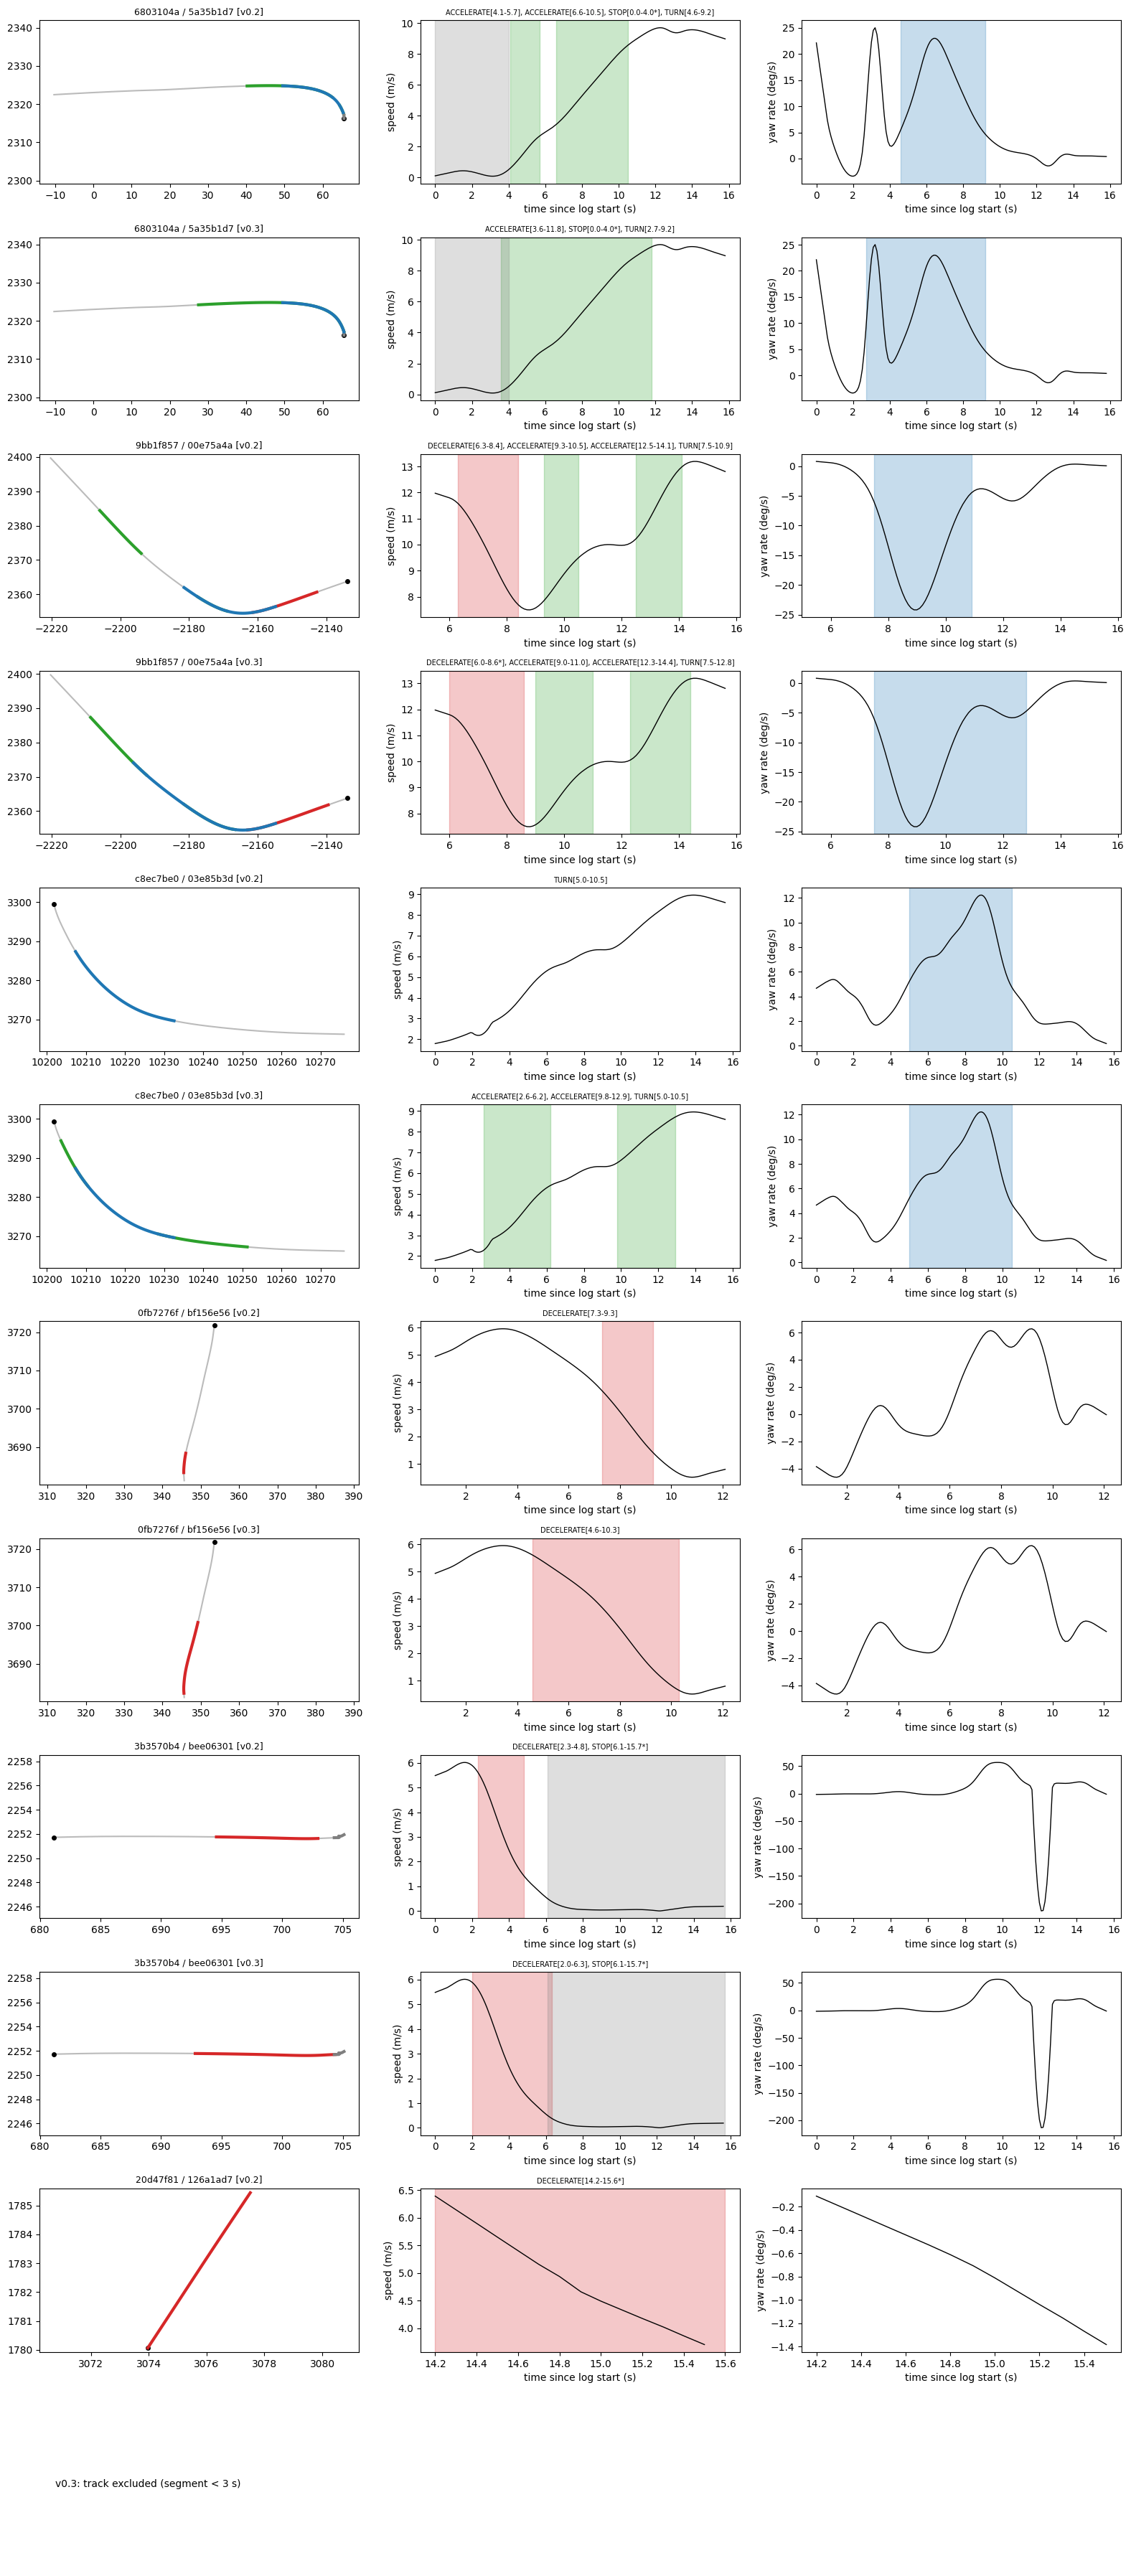

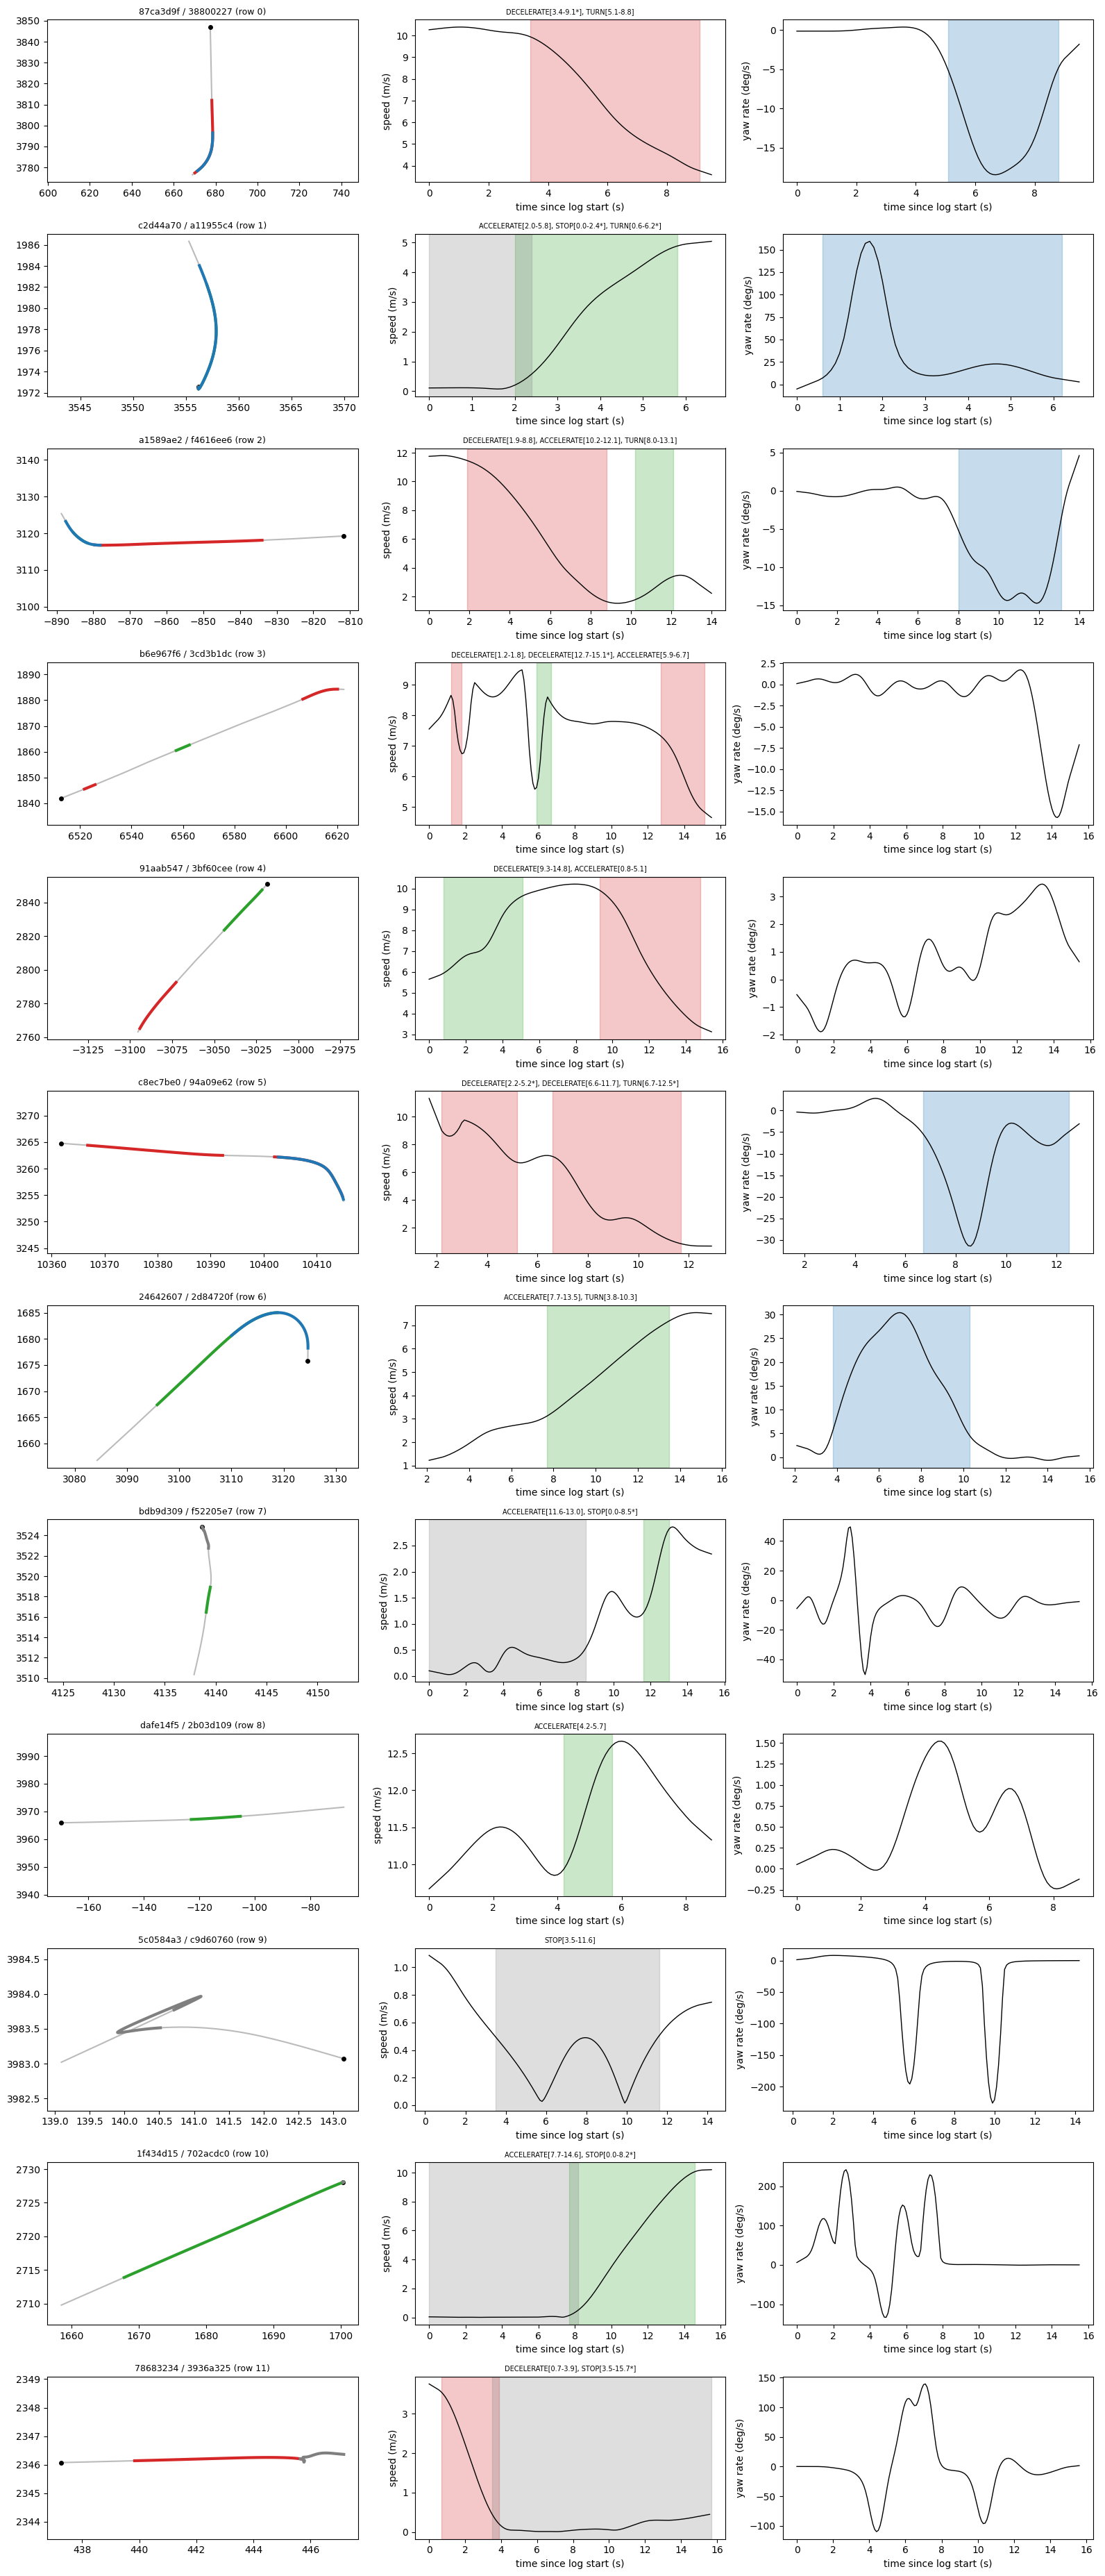

수동 확인용 사건: 26


In [ ]:
track_events = defaultdict(list)
for e in events:
    track_events[e.track_key].append(e)
track_events02 = defaultdict(list)
if COMPARE_V02_DETECTOR:
    for e in events02:
        track_events02[e.track_key].append(e)

prev_keys = []
if DRIVE_MOUNTED:
    prev = sorted((p for p in (Path(DRIVE_ROOT) / RESULTS_DIR_NAME).glob("*/manual_event_check.csv")
                   if not p.parent.name.startswith("v03_")), key=lambda p: p.stat().st_mtime)
    if prev:
        pm = pd.read_csv(prev[-1]).sort_values("figure_row")
        prev_keys = list(dict.fromkeys(zip(pm.log_id, pm.track_id)))[:N_COMPARE_TRACKS]
        print("이전 수동 확인 파일:", prev[-1])
if prev_keys and COMPARE_V02_DETECTOR:
    fig, axes = plt.subplots(2 * len(prev_keys), 3, figsize=(16, 3.0 * 2 * len(prev_keys)), squeeze=False)
    for i, key in enumerate(prev_keys):
        top, bottom = axes[2 * i], axes[2 * i + 1]
        if key in signals02:
            T.plot_track(key, track_events02.get(key, []), signals02[key], top, "[v0.2]")
        else:
            for ax in top: ax.axis("off")
        if key in signals:
            T.plot_track(key, track_events.get(key, []), signals[key], bottom, "[v0.3]")
        else:
            for ax in bottom: ax.axis("off")
            bottom[0].text(0.05, 0.5, "v0.3: track excluded (segment < 3 s)", transform=bottom[0].transAxes)
    fig.tight_layout(); fig.savefig(OUT / "detector_v02_vs_v03.png", dpi=100); plt.show()
else:
    print("비교할 이전 수동 확인 파일이 없어 생략합니다.")

rng = np.random.default_rng(SEED)
chosen, per_type = [], max(1, N_TRACKS_TO_PLOT // len(T.EVENT_TYPES))
for typ in T.EVENT_TYPES:
    pool = sorted({e.track_key for e in events if e.type == typ} - set(chosen))
    chosen += [pool[i] for i in rng.permutation(len(pool))[:per_type]]
fig, axes = plt.subplots(len(chosen), 3, figsize=(16, 3.1 * len(chosen)), squeeze=False)
for row, key in enumerate(chosen):
    T.plot_track(key, track_events[key], signals[key], axes[row], f"(row {row})")
fig.tight_layout(); fig.savefig(OUT / "detector_check.png", dpi=110); plt.show()
row_of = {k: i for i, k in enumerate(chosen)}
manual = event_df[[(l, t) in row_of for l, t in zip(event_df.log_id, event_df.track_id)]].copy()
manual.insert(0, "figure_row", [row_of[(l, t)] for l, t in zip(manual.log_id, manual.track_id)])
manual["verdict"], manual["note"] = "", ""
manual.sort_values(["figure_row", "start"]).to_csv(OUT / "manual_event_check.csv", index=False)
print("수동 확인용 사건:", len(manual))

## 5. [계층 4] Graph Query Execution 검증 (32개 TQP)

In [ ]:
queries = T.all_queries()
t0 = time.perf_counter()
exec_report, _ = T.verify_and_benchmark(events, universe, queries, repeat=LATENCY_REPEAT)
print(f"검증 소요: {time.perf_counter() - t0:.1f}s")
q_df = pd.DataFrame(exec_report["per_query"])[["query", "status_equal", "retrieval_equal", "matches",
                                                "positive_tracks", "uncertain_tracks", "partial_tracks",
                                                "interval_ms", "graph_ms"]]
display(q_df)
for k in ("all_status_equal", "all_retrieval_equal", "graph_build_ms_median", "graph_retained_memory_kib",
          "retrieval_latency_interval_ms_mean", "retrieval_latency_graph_ms_mean", "break_even_query_count"):
    print(f"{k}: {exec_report[k]}")
assert exec_report["all_status_equal"] and exec_report["all_retrieval_equal"], "두 실행기 불일치"

검증 소요: 22.1s


,query,status_equal,retrieval_equal,matches,positive_tracks,uncertain_tracks,partial_tracks,interval_ms,graph_ms
0,TURN THEN TURN,True,True,1,1,0,0,6.94454,0.00359
1,TURN THEN DECELERATE,True,True,37,36,0,56,16.10237,0.09138
2,TURN THEN ACCELERATE,True,True,5,5,0,95,24.20524,0.01079
3,TURN THEN STOP,True,True,8,7,0,20,29.69215,0.01716
4,TURN WHILE TURN,True,True,0,0,0,0,6.26585,0.00084
5,TURN WHILE DECELERATE,True,True,28,28,3,56,17.07256,0.06422
6,TURN WHILE ACCELERATE,True,True,101,101,18,74,20.67555,0.22783
7,TURN WHILE STOP,True,True,4,4,6,13,27.96354,0.00993
8,DECELERATE THEN TURN,True,True,23,23,0,59,16.72151,0.05447
9,DECELERATE THEN DECELERATE,True,True,104,101,0,0,21.00796,0.23228


all_status_equal: True
all_retrieval_equal: True
graph_build_ms_median: 593.569
graph_retained_memory_kib: 816.3
retrieval_latency_interval_ms_mean: 37.01381
retrieval_latency_graph_ms_mean: 0.12693
break_even_query_count: 17


## 6. 관계 임계값 민감도

THEN 최대 간격과 WHILE 겹침 비율을 바꿨을 때 핵심 질의의 양성·PARTIAL 트랙 수입니다. 결과가 임계값에 크게 흔들리면 논문에서 임계값 선택 근거를 따로 제시해야 합니다.

In [ ]:
sens_rows = []
if RUN_SENSITIVITY:
    core = [T.Query("DECELERATE", "THEN", "TURN"), T.Query("TURN", "THEN", "DECELERATE"),
            T.Query("DECELERATE", "WHILE", "TURN"), T.Query("DECELERATE", "THEN", "STOP"),
            T.Query("STOP", "THEN", "ACCELERATE"), T.Query("ACCELERATE", "WHILE", "TURN")]
    for gap in (3.0, 5.0, 7.0):
        for ratio in (0.6, 0.8, 1.0):
            cfg = T.RelationConfig(then_max_gap_s=gap, while_min_ratio=ratio)
            gx = T.GraphQueryExecutor(T.TemporalEventGraph(events, universe, cfg))
            for q in core:
                st = pd.Series(gx.statuses(q)).value_counts()
                sens_rows.append({"THEN_max_gap_s": gap, "WHILE_ratio": ratio, "query": str(q),
                                  "positive": int(st.get("POSITIVE", 0)), "partial": int(st.get("PARTIAL", 0)),
                                  "uncertain": int(st.get("UNCERTAIN", 0))})
    sens = pd.DataFrame(sens_rows)
    sens.to_csv(OUT / "threshold_sensitivity.csv", index=False)
    display(sens.pivot_table(index="query", columns=["THEN_max_gap_s", "WHILE_ratio"], values="positive"))

THEN_max_gap_s           3.0                  5.0                  7.0         \
WHILE_ratio              0.6    0.8    1.0    0.6    0.8    1.0    0.6    0.8   
query                                                                           
ACCELERATE WHILE TURN  139.0  101.0   64.0  139.0  101.0   64.0  139.0  101.0   
DECELERATE THEN STOP   256.0  256.0  256.0  269.0  269.0  269.0  272.0  272.0   
DECELERATE THEN TURN    23.0   23.0   23.0   23.0   23.0   23.0   23.0   23.0   
DECELERATE WHILE TURN   44.0   28.0   14.0   44.0   28.0   14.0   44.0   28.0   
STOP THEN ACCELERATE   256.0  256.0  256.0  270.0  270.0  270.0  278.0  278.0   
TURN THEN DECELERATE    26.0   26.0   26.0   36.0   36.0   36.0   41.0   41.0   

THEN_max_gap_s                
WHILE_ratio              1.0  
query                         
ACCELERATE WHILE TURN   64.0  
DECELERATE THEN STOP   272.0  
DECELERATE THEN TURN    23.0  
DECELERATE WHILE TURN   14.0  
STOP THEN ACCELERATE   278.0  
TURN THEN DECELERATE    41.0

## 7. [계층 1·2] P(TQP) 대 B2(직접 Python) 생성

프롬프트 변형별로 같은 72개 문장에 대해 P와 B2를 생성합니다. T4 기준 B2 생성은 변형당 약 1–2분입니다.

In [ ]:
diag = N.build_diagnostic_set()
golds = [T.Query(r.gold_first, r.gold_relation, r.gold_second) for r in diag.itertuples()]
probes_all = [N.build_probes(g) for g in golds]
model, tok, device = N.load_model(LLM_MODEL_ID)
print("모델:", LLM_MODEL_ID, "| 장치:", device)

def b2_pred_str(g, inferred):
    return {"THEN_XY": f"{g.first} THEN {g.second}", "THEN_YX": f"{g.second} THEN {g.first}",
            "WHILE": f"{g.first} WHILE {g.second}"}.get(inferred, inferred)

rows, gen_info, p_preds = [], [], {}
for variant in PROMPT_VARIANTS:
    outs, sec = N.generate(model, tok, device, [N.tqp_messages(s, variant) for s in diag.sentence],
                           batch_size=LLM_BATCH_SIZE, max_new_tokens=96)
    gen_info.append({"variant": variant, "method": "P (TQP)", "seconds": round(sec, 1)})
    p_preds[variant] = []
    for (_, r), g, pr, text in zip(diag.iterrows(), golds, probes_all, outs):
        pred, plan, err = N.parse_prediction(text)
        p_preds[variant].append(pred)
        slot = None
        if isinstance(plan, dict) and isinstance(plan.get("events"), dict):
            slot = plan["events"].get("e1") == r.first_mentioned
        rows.append({**r.to_dict(), "variant": variant, "method": "P (TQP)", "raw_output": text,
                     "pred": str(pred) if pred else None, "error": err, "e1_is_first_mentioned": slot,
                     **N.score_tqp(g, pred), **N.probe_score(g, N.tqp_probe_accepts(pred, pr), pr)})
    if RUN_B2:
        outs, sec = N.generate(model, tok, device, [N.b2_messages(s, variant) for s in diag.sentence],
                               batch_size=LLM_BATCH_SIZE, max_new_tokens=B2_MAX_NEW_TOKENS)
        gen_info.append({"variant": variant, "method": "B2 (Python)", "seconds": round(sec, 1)})
        for (_, r), g, pr, text in zip(diag.iterrows(), golds, probes_all, outs):
            accepts, err = N.run_b2(text, pr)
            inferred = N.infer_from_accepts(accepts) if accepts else None
            rows.append({**r.to_dict(), "variant": variant, "method": "B2 (Python)", "raw_output": text,
                         "pred": b2_pred_str(g, inferred) if inferred else None, "error": err,
                         "e1_is_first_mentioned": None,
                         **N.score_b2(g, accepts), **N.probe_score(g, accepts, pr)})
    print(f"{variant}: 완료")
res = pd.DataFrame(rows)
res.to_csv(OUT / "llm_predictions_all.csv", index=False)
display(pd.DataFrame(gen_info))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

모델: Qwen/Qwen2.5-1.5B-Instruct | 장치: cuda
v1_original: 완료
zero_shot: 완료
balanced: 완료


,variant,method,seconds
0,v1_original,P (TQP),13.7
1,v1_original,B2 (Python),38.3
2,zero_shot,P (TQP),14.6
3,zero_shot,B2 (Python),86.7
4,balanced,P (TQP),15.1
5,balanced,B2 (Python),44.9


## 8. 해석 정확도 분석

In [ ]:
pd.set_option("display.max_colwidth", 160)
print("[전체] 변형 × 방법")
overall = N.summarize(res, ["variant", "method"])
display(overall)

print("\n[접속사 × 어순] exact 정확도 (n)")
ct = (res.groupby(["variant", "method", "connective", "condition"]).exact
      .agg(lambda s: f"{s.mean():.2f} ({len(s)})").unstack(["connective", "condition"]))
display(ct)

print("\n[템플릿별] exact 정확도")
display(res.groupby(["template", "variant", "method"]).exact.mean().unstack(["variant", "method"]).round(2))

def error_type(r):
    if r.exact: return "correct"
    if not r.valid: return "invalid output"
    if r.method.startswith("B2") and r.pred == "OTHER": return f"B2 probe pattern {r.probe_pattern}"
    if not r.relation_correct: return f"relation error (gold {r.gold_relation})"
    if r.gold_relation == "THEN" and r.direction_correct == False: return "direction reversed"
    return "other"
res["error_type"] = [error_type(r) for r in res.itertuples()]
print("\n[오류 유형]")
display(res[res.error_type != "correct"].groupby(["variant", "method", "error_type"]).size().unstack(fill_value=0))

print("\n[P vs B2 McNemar (exact)]")
mc = []
if RUN_B2:
    for variant in PROMPT_VARIANTS:
        p = res[(res.variant == variant) & (res.method == "P (TQP)")].set_index("sentence").exact
        b = res[(res.variant == variant) & (res.method == "B2 (Python)")].set_index("sentence").exact.reindex(p.index)
        mc.append({"variant": variant, "P_exact": round(p.mean(), 3), "B2_exact": round(b.mean(), 3),
                   **N.mcnemar_exact(p.tolist(), b.tolist())})
    display(pd.DataFrame(mc))

print("\n[P 슬롯 규칙 준수: e1 = 먼저 언급된 사건] (v1_original에서만 규칙으로 요구됨)")
_p = res[res.method == "P (TQP)"].assign(slot=lambda d: d.e1_is_first_mentioned.astype(float))
display(_p.groupby(["variant", "condition"]).slot.mean().unstack().round(2))

print("\n[오답 예시] 변형별 최대 8개")
for (variant, method), g in res[res.error_type != "correct"].groupby(["variant", "method"]):
    print(f"\n--- {variant} / {method}")
    display(g[["sentence", "gold_first", "gold_relation", "gold_second", "pred", "error_type", "error"]].head(8))

[전체] 변형 × 방법


n  valid  relation_acc  direction_acc(THEN)  \
variant     method                                                      
balanced    B2 (Python)  72  1.000         0.806                0.833   
            P (TQP)      72  1.000         0.986                0.883   
v1_original B2 (Python)  72  1.000         0.667                0.633   
            P (TQP)      72  1.000         0.792                0.650   
zero_shot   B2 (Python)  72  0.708         0.194                0.150   
            P (TQP)      72  0.375         0.333                0.300   

                         exact_acc    exact_95CI  probe_exact  
variant     method                                             
balanced    B2 (Python)      0.792  [0.68, 0.87]        0.792  
            P (TQP)          0.889  [0.80, 0.94]        0.889  
v1_original B2 (Python)      0.667  [0.55, 0.77]        0.667  
            P (TQP)          0.708  [0.59, 0.80]        0.708  
zero_shot   B2 (Python)      0.139  [0.08, 0.24]        0.028  
            P (TQP)          0.306  [0.21, 0.42]        0.306


[접속사 × 어순] exact 정확도 (n)


connective                   after               and then           as  \
condition                congruent incongruent  congruent simultaneous   
variant     method                                                       
balanced    B2 (Python)  0.83 (12)   0.75 (12)  0.83 (12)     0.50 (4)   
            P (TQP)      0.92 (12)   0.58 (12)  0.92 (12)     0.75 (4)   
v1_original B2 (Python)  0.67 (12)   0.50 (12)  0.75 (12)     0.75 (4)   
            P (TQP)      0.75 (12)   0.75 (12)  1.00 (12)     1.00 (4)   
zero_shot   B2 (Python)  0.42 (12)   0.00 (12)  0.33 (12)     0.00 (4)   
            P (TQP)      0.17 (12)   0.08 (12)  0.67 (12)     0.00 (4)   

connective                  before                    while  
condition                congruent incongruent simultaneous  
variant     method                                           
balanced    B2 (Python)  0.92 (12)   0.83 (12)     0.62 (8)  
            P (TQP)      1.00 (12)   1.00 (12)     1.00 (8)  
v1_original B2 (Python)  0.58 (12)   0.67 (12)     0.88 (8)  
            P (TQP)      0.42 (12)   0.33 (12)     1.00 (8)  
zero_shot   B2 (Python)  0.00 (12)   0.00 (12)     0.12 (8)  
            P (TQP)      0.42 (12)   0.17 (12)     0.50 (8)


[템플릿별] exact 정확도


variant           balanced         v1_original           zero_shot        
method         B2 (Python) P (TQP) B2 (Python) P (TQP) B2 (Python) P (TQP)
template                                                                  
after                 0.75    0.58        0.50    0.75        0.00    0.08
after_fronted         0.83    0.92        0.67    0.75        0.42    0.17
and_then              0.83    0.92        0.75    1.00        0.33    0.67
as                    0.50    0.75        0.75    1.00        0.00    0.00
before                0.92    1.00        0.58    0.42        0.00    0.42
before_fronted        0.83    1.00        0.67    0.33        0.00    0.17
while                 0.75    1.00        1.00    1.00        0.25    0.75
while_fronted         0.50    1.00        0.75    1.00        0.00    0.25

... (14 outputs left out)


--- zero_shot / B2 (Python)


,sentence,gold_first,gold_relation,gold_second,pred,error_type,error
216,A vehicle turns before slowing down.,TURN,THEN,DECELERATE,TURN WHILE DECELERATE,relation error (gold THEN),None
217,A vehicle turns before speeding up.,TURN,THEN,ACCELERATE,None,invalid output,runtime(then_xy): _Timeout: time limit exceeded
218,A vehicle turns before stopping.,TURN,THEN,STOP,OTHER,B2 probe pattern 1010000,None
219,A vehicle slows down before turning.,DECELERATE,THEN,TURN,OTHER,B2 probe pattern 1101001,None
220,A vehicle slows down before speeding up.,DECELERATE,THEN,ACCELERATE,None,invalid output,runtime(then_xy): _Timeout: time limit exceeded
221,A vehicle slows down before stopping.,DECELERATE,THEN,STOP,None,invalid output,compile: NameError: name 'print' is not defined
222,A vehicle speeds up before turning.,ACCELERATE,THEN,TURN,OTHER,B2 probe pattern 1111001,None
223,A vehicle speeds up before slowing down.,ACCELERATE,THEN,DECELERATE,None,invalid output,runtime(then_xy): _Timeout: time limit exceeded



--- zero_shot / P (TQP)


,sentence,gold_first,gold_relation,gold_second,pred,error_type,error
146,A vehicle turns before stopping.,TURN,THEN,STOP,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
147,A vehicle slows down before turning.,DECELERATE,THEN,TURN,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
148,A vehicle slows down before speeding up.,DECELERATE,THEN,ACCELERATE,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
149,A vehicle slows down before stopping.,DECELERATE,THEN,STOP,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
153,A vehicle stops before turning.,STOP,THEN,TURN,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
154,A vehicle stops before slowing down.,STOP,THEN,DECELERATE,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
155,A vehicle stops before speeding up.,STOP,THEN,ACCELERATE,None,invalid output,schema: Relation args must contain e1 and e2 exactly once
156,A vehicle turns after slowing down.,DECELERATE,THEN,TURN,None,invalid output,schema: Relation args must contain e1 and e2 exactly once


## 9. End-to-end: 자연어 → TQP → 그래프 검색

,same_track_set,jaccard,sentences_with_nonempty_gold
variant,,,
balanced,0.889,0.890,72
v1_original,0.708,0.716,72
zero_shot,0.306,0.308,72



예시 추적 (변형: balanced)
① 문장        : A vehicle turns after slowing down.
② P (TQP)     : {"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}
② B2 (Python) : ```python
def matches(events):
    for a in events:
        for b in events:
            if a is b or a['type'] != 'DECELERATE' or b['type'] != 'TURN':
                continue
            overlap = max(0.0, min(a['end'], b['end']) - max(a['start'], b['start']))
            if a['start'] < b['start'] and overlap <= 0.5 and -0.5 <= b['start'] - a['end'] <= 5.0:
                return True
    retur
③ P 해석      : DECELERATE THEN TURN | 정답: DECELERATE THEN TURN
④ 그래프 패턴 : (:Event {type:'DECELERATE'})-[:THEN]->(:Event {type:'TURN'})
⑤ 검색 결과   : 사건 쌍 23개


,log_id,track_id,first_type,first_start,first_end,second_type,second_start,second_end
0,0c3bad78-9f1e-395d-a376-2eb7499229fd,b3a3d3fa-8966-4684-9726-6ab58ec6dc49,DECELERATE,2.2,5.1,TURN,5.2,10.5
1,20d47f81-46e8-3adf-a0ca-564fbb5c599d,54be6630-0405-4a93-9015-c0de6fa7cb48,DECELERATE,6.6,12.1,TURN,11.9,15.0
2,20dd185d-b4eb-3024-a17a-b4e5d8b15b65,cbe06f30-a223-4eea-a04b-940d3dc22a97,DECELERATE,1.3,3.2,TURN,3.8,8.4
3,25e5c600-36fe-3245-9cc0-40ef91620c22,58b1ffd9-2e5f-4531-b61b-d0aa42ac1869,DECELERATE,2.6,5.5,TURN,7.4,13.1
4,2c652f9e-8db8-3572-aa49-fae1344a875b,61fc38cf-43c5-45e6-aaea-95f33cec7d67,DECELERATE,1.1,6.1,TURN,7.0,12.0
5,335aabef-269e-3211-a99d-2c3a3a8f8475,5f0e23c2-13a9-4930-9567-0bdab1e8c95b,DECELERATE,1.0,4.6,TURN,4.3,9.6
6,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,148e0484-c728-406f-a58b-29024daef4be,DECELERATE,3.7,8.2,TURN,8.9,13.2
7,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,8521bfe8-2550-4557-ba1c-70c2add7238d,DECELERATE,6.3,10.3,TURN,10.2,15.1


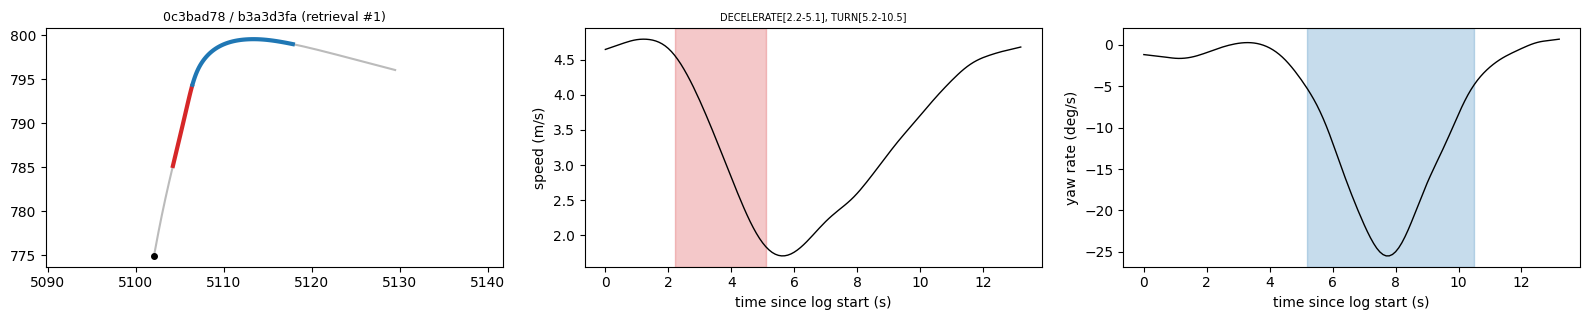

In [ ]:
e2e_rows = []
for variant in PROMPT_VARIANTS:
    for (_, r), g, pred in zip(diag.iterrows(), golds, p_preds[variant]):
        gold_t = {(m.log_id, m.track_id) for m in gexec.retrieve(g)}
        pred_t = {(m.log_id, m.track_id) for m in gexec.retrieve(pred)} if pred else set()
        u = gold_t | pred_t
        e2e_rows.append({"variant": variant, "sentence": r.sentence, "condition": r.condition,
                         "gold_tracks": len(gold_t), "pred_tracks": len(pred_t),
                         "same_track_set": gold_t == pred_t, "jaccard": len(gold_t & pred_t) / len(u) if u else 1.0})
e2e = pd.DataFrame(e2e_rows)
e2e.to_csv(OUT / "end_to_end.csv", index=False)
ne = e2e[e2e.gold_tracks > 0]
display(ne.groupby("variant")[["same_track_set", "jaccard"]].mean().round(3)
        .assign(sentences_with_nonempty_gold=ne.groupby("variant").size()))

best = overall.xs("P (TQP)", level="method").exact_acc.idxmax()
EXAMPLE = "A vehicle turns after slowing down."
i = int(diag.index[diag.sentence == EXAMPLE][0])
sel = res[(res.sentence == EXAMPLE) & (res.variant == best)]
print(f"\n예시 추적 (변형: {best})")
print("① 문장        :", EXAMPLE)
for _, r in sel.iterrows():
    print(f"② {r.method:12s}: {str(r.raw_output).strip()[:400]}")
q = p_preds[best][i]
print("③ P 해석      :", q, "| 정답:", golds[i])
if q is not None:
    print("④ 그래프 패턴 :", gexec.pattern(q))
    m = gexec.retrieve(q)
    print(f"⑤ 검색 결과   : 사건 쌍 {len(m)}개")
    if m:
        display(pd.DataFrame([asdict(x) for x in m])[["log_id", "track_id", "first_type", "first_start", "first_end",
                                                      "second_type", "second_start", "second_end"]].round(2).head(8))
        key = (m[0].log_id, m[0].track_id)
        fig, axes = plt.subplots(1, 3, figsize=(16, 3.3), squeeze=False)
        T.plot_track(key, track_events[key], signals[key], axes[0], "(retrieval #1)")
        fig.tight_layout(); fig.savefig(OUT / "example_retrieval.png", dpi=110); plt.show()

## 10. 요약 및 저장

In [ ]:
def fmt(v):
    return "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else v

ov = overall.reset_index()
lines = []
for variant in PROMPT_VARIANTS:
    p = ov[(ov.variant == variant) & (ov.method == "P (TQP)")].iloc[0]
    b = ov[(ov.variant == variant) & (ov.method == "B2 (Python)")]
    btxt = f"B2 {b.iloc[0].exact_acc} {b.iloc[0].exact_95CI}" if len(b) else "B2 미실행"
    lines.append(f"{variant}: P {p.exact_acc} {p.exact_95CI} / {btxt}")
summary = pd.DataFrame([
    {"계층": "Temporal Relation Grounding", "결과": " | ".join(lines)},
    {"계층": "Temporal Query Plan", "결과": ", ".join(f"{v}: 유효 {ov[(ov.variant == v) & (ov.method == 'P (TQP)')].valid.iloc[0]}"
                                                  for v in PROMPT_VARIANTS)},
    {"계층": "Temporal Event Graph", "결과": (f"트랙 {gsum['track_nodes']}, 사건 {gsum['event_nodes']}, 엣지 {gsum['relation_edges']}; "
                                            f"같은 유형 1초 이내 연속: v0.3 {quality['v0.3']['same_type_gap_le_1s']}"
                                            + (f" / v0.2 {quality['v0.2']['same_type_gap_le_1s']}" if 'v0.2' in quality else ""))},
    {"계층": "Graph Query Execution", "결과": (f"일치 {exec_report['all_status_equal'] and exec_report['all_retrieval_equal']}, "
                                             f"Interval {exec_report['retrieval_latency_interval_ms_mean']} ms / Graph "
                                             f"{exec_report['retrieval_latency_graph_ms_mean']} ms, 구축 {exec_report['graph_build_ms_median']} ms, "
                                             f"손익분기 {fmt(exec_report['break_even_query_count'])}회")},
    {"계층": "End-to-end", "결과": ", ".join(f"{v}: {ne[ne.variant == v].same_track_set.mean():.3f}" for v in PROMPT_VARIANTS)},
])
display(summary)

final = {"created": STAMP, "engine_version": T.VERSION, "acquisition": acquisition,
         "detector_config_v03": asdict(T.DEFAULT_DET), "detector_quality": quality,
         "graph": gsum, "graph_query_execution": exec_report,
         "llm": {"model": LLM_MODEL_ID, "device": device, "generation": gen_info,
                 "overall": ov.to_dict("records"), "mcnemar": mc},
         "end_to_end": ne.groupby("variant").same_track_set.mean().round(3).to_dict(),
         "summary": summary.to_dict("records")}
(OUT / "report.json").write_text(json.dumps(final, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
summary.to_csv(OUT / "layer_summary.csv", index=False)
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT)
if DRIVE_MOUNTED:
    dest = Path(DRIVE_ROOT) / RESULTS_DIR_NAME / OUT.name
    shutil.copytree(OUT, dest)
    print("Drive 저장:", dest)
print("결과 ZIP:", archive)

,계층,결과
0,Temporal Relation Grounding,"v1_original: P 0.708 [0.59, 0.80] / B2 0.667 [0.55, 0.77] | zero_shot: P 0.306 [0.21, 0.42] / B2 0.139 [0.08, 0.24] | balanced: P 0.889 [0.80, 0.94] / B2 0...."
1,Temporal Query Plan,"v1_original: 유효 1.0, zero_shot: 유효 0.375, balanced: 유효 1.0"
2,Temporal Event Graph,"트랙 3172, 사건 3892, 엣지 1791; 같은 유형 1초 이내 연속: v0.3 0 / v0.2 87"
3,Graph Query Execution,"일치 True, Interval 37.01381 ms / Graph 0.12693 ms, 구축 593.569 ms, 손익분기 17회"
4,End-to-end,"v1_original: 0.708, zero_shot: 0.306, balanced: 0.889"


Drive 저장: /content/drive/MyDrive/AV2_TQP_TEG_Results/v03_val_20261016_045848
결과 ZIP: /content/tqp_teg_out/v03_val_20261016_045848.zip


## 11. 해석 시 유의 사항

- **P 대 B2**: 같은 모델·같은 예시 문장·같은 탐침으로 비교한 대응 표본입니다. 차이는 McNemar p값과 함께 보고하고, 72개 문장·템플릿 기반이라는 한계를 명시하십시오.
- **B2의 불리함**: B2는 관계의 수치 정의까지 코드로 구현해야 합니다. 이것이 H1이 가정하는 차이의 일부이며, 오류 유형표에서 "해석 오류"와 "구현 오류(invalid, 탐침 패턴 이상)"를 구분해 보고하십시오.
- **프롬프트 의존성**: 변형 간 차이가 크면 결론은 "특정 프롬프트 조건에서"로 한정해야 합니다.
- **검출기**: v0.3 지표가 좋아져도 `manual_event_check.csv`로 정밀도를 측정하기 전에는 검색 결과를 실제 장면이라고 단정하지 마십시오.
- **임계값**: 6절에서 결과가 크게 흔들리는 질의는 논문에서 따로 언급하십시오.

In [ ]:
# [v0.4-1] 실행 상태 확인 + v0.4 검출기 정의
import json, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, asdict
from collections import defaultdict, Counter
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.stats import fisher_exact

_need = ["T", "N", "folders", "OUT", "events", "universe", "signals"]
_missing = [n for n in _need if n not in globals()]
assert not _missing, f"런타임에 {_missing} 이(가) 없습니다. 기존 노트북 1~4절을 먼저 다시 실행하십시오."
POSE_TOL = globals().get("POSE_TOLERANCE_MS", 15.0)
OUT4 = OUT.parent / OUT.name.replace("v03_", "v04_")
OUT4.mkdir(parents=True, exist_ok=True)
print("v0.4 결과 폴더:", OUT4)


@dataclass(frozen=True)
class DetectorConfigV04(T.DetectorConfig):
    """v0.3 + (1) 반대 방향 사건을 건너뛰는 병합 금지 (2) 흔들림 제거 (3) 저속 회전 제외"""
    jitter_window_s: float = 1.5       # 사건 앞뒤 1.5초를 확인
    jitter_return_frac: float = 0.3    # 그 안에 속도가 반대쪽 끝값의 30% 이내로 되돌아오면 흔들림
    use_jitter_filter: bool = True
    turn_mask_min_speed: float = 1.5   # m/s 미만에서는 요 레이트를 회전으로 보지 않음


DET_V04 = DetectorConfigV04()
DET_V04_NOJITTER = DetectorConfigV04(use_jitter_filter=False)


def close_gaps_guarded(mask, max_gap_n, block):
    """길이 max_gap_n 이하의 내부 빈칸을 메우되, 빈칸 안에 반대 방향 사건(block)이 있으면 메우지 않음."""
    out = np.asarray(mask, dtype=bool).copy()
    if max_gap_n <= 0:
        return out
    for a, b in T.contiguous_runs(~out):
        if a > 0 and b < len(out) and (b - a) <= max_gap_n and not np.any(block[a:b]):
            out[a:b] = True
    return out


def is_jitter(kind, speed, a, b, n_win, frac):
    vs, ve = float(speed[a]), float(speed[b - 1])
    d = abs(ve - vs)
    if d <= 0:
        return True
    pre = speed[max(0, a - n_win):a]
    post = speed[b:b + n_win]
    if kind == "DECELERATE":   # 직전에 이미 낮았거나(위로 튄 값) 직후 다시 높아짐(아래로 꺼진 값)
        return bool((len(pre) and pre.min() <= ve + frac * d) or (len(post) and post.max() >= vs - frac * d))
    return bool((len(pre) and pre.max() >= ve - frac * d) or (len(post) and post.min() <= vs + frac * d))


_extract_v03 = getattr(T, "_extract_events_v03", T.extract_events)
T._extract_events_v03 = _extract_v03


def extract_events_v04(t, x, y, log_id, track_id, dcfg=T.DEFAULT_DET):
    if not isinstance(dcfg, DetectorConfigV04):
        return _extract_v03(t, x, y, log_id, track_id, dcfg)
    t, x, y = (np.asarray(v, float) for v in (t, x, y))
    events_, segments = [], []
    if len(t) < dcfg.window:
        return events_, segments
    o = np.argsort(t)
    t, x, y = t[o], x[o], y[o]
    cuts = np.r_[0, np.flatnonzero(np.diff(t) > dcfg.max_gap_s) + 1, len(t)]
    for lo, hi in zip(cuts[:-1], cuts[1:]):
        tt, xx, yy = t[lo:hi], x[lo:hi], y[lo:hi]
        if len(tt) < dcfg.window or np.any(np.diff(tt) <= 0):
            continue
        if tt[-1] - tt[0] < dcfg.min_segment_s - 1e-9:
            continue
        dt = float(np.median(np.diff(tt)))
        if not 0.075 <= dt <= 0.125:
            continue
        if np.max(np.hypot(xx - xx[0], yy - yy[0])) < dcfg.min_displacement_m:
            continue
        w, p = dcfg.window, dcfg.polyorder
        vx = savgol_filter(xx, w, p, deriv=1, delta=dt)
        vy = savgol_filter(yy, w, p, deriv=1, delta=dt)
        speed = np.hypot(vx, vy)
        accel = savgol_filter(speed, w, p, deriv=1, delta=dt)
        yaw_rate = savgol_filter(np.unwrap(np.arctan2(vy, vx)), w, p, deriv=1, delta=dt)
        travel = np.r_[0.0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        segments.append({"t": tt, "x": xx, "y": yy, "speed": speed, "accel": accel,
                         "yaw_rate_deg_s": np.rad2deg(yaw_rate)})
        n = len(tt)
        n_trim = int(round(dcfg.edge_trim_s / dt))
        n_merge = int(round(dcfg.merge_gap_s / dt))
        n_win = int(round(dcfg.jitter_window_s / dt))
        rate = np.deg2rad(dcfg.turn_rate_deg_s)
        moving = speed >= dcfg.turn_mask_min_speed
        dec = accel <= -dcfg.accel_mask_threshold
        acc = accel >= dcfg.accel_mask_threshold
        left = (yaw_rate >= rate) & moving
        right = (yaw_rate <= -rate) & moving
        candidates = [("DECELERATE", dec, acc, True), ("ACCELERATE", acc, dec, True),
                      ("STOP", speed < dcfg.stop_speed, np.zeros(n, bool), False),
                      ("TURN", left, right, True), ("TURN", right, left, True)]
        for kind, raw, block, derivative in candidates:
            mask = close_gaps_guarded(raw, n_merge, block)
            lo_e, hi_e = 0, n
            if derivative and n_trim > 0:
                mask[:n_trim] = False
                mask[max(n - n_trim, 0):] = False
                lo_e, hi_e = n_trim, n - n_trim
            for a, b in T.contiguous_runs(mask):
                dur = (b - a) * dt
                if kind == "STOP":
                    valid = dur >= dcfg.min_stop_duration_s - 1e-9
                elif kind in ("DECELERATE", "ACCELERATE"):
                    sign = -1.0 if kind == "DECELERATE" else 1.0
                    dv = sign * (speed[b - 1] - speed[a])
                    peak = float(np.max(sign * accel[a:b]))
                    strong = (dur >= dcfg.min_accel_duration_s - 1e-9
                              and peak >= dcfg.accel_peak_threshold - 1e-12 and dv >= dcfg.min_speed_change)
                    gentle = dur >= dcfg.gentle_min_duration_s - 1e-9 and dv >= dcfg.gentle_min_speed_change
                    valid = strong or gentle
                    if valid and dcfg.use_jitter_filter:
                        valid = not is_jitter(kind, speed, a, b, n_win, dcfg.jitter_return_frac)
                else:
                    angle = abs(T._trapz(yaw_rate[a:b], dx=dt))
                    valid = (angle >= np.deg2rad(dcfg.min_turn_deg)
                             and travel[b - 1] - travel[a] >= dcfg.min_turn_travel_m
                             and float(np.median(speed[a:b])) >= dcfg.min_turn_speed)
                if valid:
                    events_.append(T.Event(f"{log_id}:{track_id}:{len(events_)}", log_id, track_id, kind,
                                           float(tt[a]), float(tt[b - 1] + dt),
                                           clipped_start=(a <= lo_e), clipped_end=(b >= hi_e)))
    return events_, segments


T.extract_events = extract_events_v04   # T.load_av2_log가 이 함수를 사용하게 됨
print("v0.4 검출기 등록 완료:", asdict(DET_V04))

v0.4 결과 폴더: /content/tqp_teg_out/v04_val_20261016_045848
v0.4 검출기 등록 완료: {'window': 11, 'polyorder': 2, 'max_gap_s': 0.25, 'min_segment_s': 3.0, 'min_displacement_m': 3.0, 'edge_trim_s': 0.5, 'merge_gap_s': 1.0, 'accel_mask_threshold': 0.5, 'accel_peak_threshold': 1.0, 'min_accel_duration_s': 0.5, 'min_speed_change': 1.5, 'gentle_min_duration_s': 2.0, 'gentle_min_speed_change': 2.0, 'stop_speed': 0.5, 'min_stop_duration_s': 1.0, 'turn_rate_deg_s': 5.0, 'min_turn_deg': 45.0, 'min_turn_travel_m': 5.0, 'min_turn_speed': 1.0, 'jitter_window_s': 1.5, 'jitter_return_frac': 0.3, 'use_jitter_filter': True, 'turn_mask_min_speed': 1.5}


In [ ]:
# [v0.4-2] v0.4 검출 실행 + v0.2/v0.3/v0.4 비교
RUN_JITTER_ABLATION = True   # 흔들림 필터만 끈 버전도 돌려 제거 효과를 따로 봄


def detect_all(dcfg, label):
    evs_all, uni, sig, diags = [], set(), {}, []
    t0 = time.perf_counter()
    for folder in folders:
        try:
            evs, info, u, s = T.load_av2_log(folder, pose_tolerance_ms=POSE_TOL, dcfg=dcfg)
        except Exception as exc:
            diags.append({"log_id": folder.name, "error": f"{type(exc).__name__}: {exc}"})
            continue
        evs_all += evs
        uni |= u
        sig.update(s)
        diags.append(info)
    print(f"[{label}] 트랙 {len(uni)} | 사건 {len(evs_all)} | {time.perf_counter() - t0:.1f}s")
    return evs_all, uni, sig, pd.DataFrame(diags)


def quality_row(evs, uni):
    q = T.detector_quality(evs, uni)
    row = {k: v for k, v in q.items() if not isinstance(v, dict)}
    row.update({f"events_{k}": v for k, v in q["events_by_type"].items()})
    row.update({f"median_dur_{k}": v for k, v in q["median_duration_s_by_type"].items()})
    g = T.TemporalEventGraph(evs, uni)
    pat = g.summary()["relation_edges_by_pattern"]
    row["relation_edges"] = len(g.relation_edges)
    row["ACCEL_WHILE_DECEL_edges(불가능)"] = pat.get("ACCELERATE WHILE DECELERATE", 0)
    return row, pat


events4, universe4, signals4, diag4 = detect_all(DET_V04, "v0.4")
assert len(events4) > 0, "v0.4에서 검출된 사건이 없습니다."
quality4, patterns4 = {}, {}
quality4["v0.3"], patterns4["v0.3"] = quality_row(events, universe)
if "events02" in globals():
    quality4["v0.2"], patterns4["v0.2"] = quality_row(events02, universe02)
quality4["v0.4"], patterns4["v0.4"] = quality_row(events4, universe4)
if RUN_JITTER_ABLATION:
    ev_nj, uni_nj, _, _ = detect_all(DET_V04_NOJITTER, "v0.4 (흔들림 필터 끔)")
    quality4["v0.4_no_jitter_filter"], patterns4["v0.4_no_jitter_filter"] = quality_row(ev_nj, uni_nj)

order = [k for k in ("v0.2", "v0.3", "v0.4_no_jitter_filter", "v0.4") if k in quality4]
print("\n검출기 품질 지표")
display(pd.DataFrame(quality4)[order])
print("\n관계 엣지 수 (패턴별)")
display(pd.DataFrame(patterns4)[order].fillna(0).astype(int))

graph4 = T.TemporalEventGraph(events4, universe4)
gexec4 = T.GraphQueryExecutor(graph4)
gsum4 = graph4.summary()
event_df4 = pd.DataFrame([asdict(e) for e in events4])
event_df4["duration_s"] = event_df4.end - event_df4.start
event_df4.to_csv(OUT4 / "event_nodes.csv", index=False)
graph4.edges_frame().to_csv(OUT4 / "relation_edges.csv", index=False)
pd.DataFrame(quality4)[order].to_csv(OUT4 / "detector_quality_v02_v03_v04.csv")
track_events4 = defaultdict(list)
for e in events4:
    track_events4[e.track_key].append(e)

[v0.4] 트랙 3172 | 사건 3687 | 16.1s
[v0.4 (흔들림 필터 끔)] 트랙 3172 | 사건 3933 | 15.4s

검출기 품질 지표


,v0.2,v0.3,v0.4_no_jitter_filter,v0.4
moving_tracks,3531.000,3172.000,3172.000,3172.000
tracks_with_events,1958.000,2262.000,2264.000,2221.000
events,3269.000,3892.000,3933.000,3687.000
clipped_event_rate,0.251,0.377,0.361,0.381
consecutive_same_type_pairs,368.000,320.000,379.000,272.000
same_type_gap_le_1s,87.000,0.000,39.000,19.000
events_TURN,335.000,337.000,305.000,305.000
events_DECELERATE,1005.000,1307.000,1334.000,1211.000
events_ACCELERATE,986.000,1333.000,1379.000,1256.000
events_STOP,943.000,915.000,915.000,915.000



관계 엣지 수 (패턴별)


,v0.2,v0.3,v0.4_no_jitter_filter,v0.4
ACCELERATE THEN ACCELERATE,101,77,112,71
ACCELERATE THEN DECELERATE,174,283,332,215
ACCELERATE THEN STOP,9,16,16,10
ACCELERATE THEN TURN,24,36,32,29
DECELERATE THEN ACCELERATE,149,200,245,142
DECELERATE THEN DECELERATE,113,104,132,71
DECELERATE THEN STOP,228,291,293,288
DECELERATE THEN TURN,32,23,23,21
STOP THEN ACCELERATE,260,286,289,280
STOP THEN DECELERATE,6,16,16,10


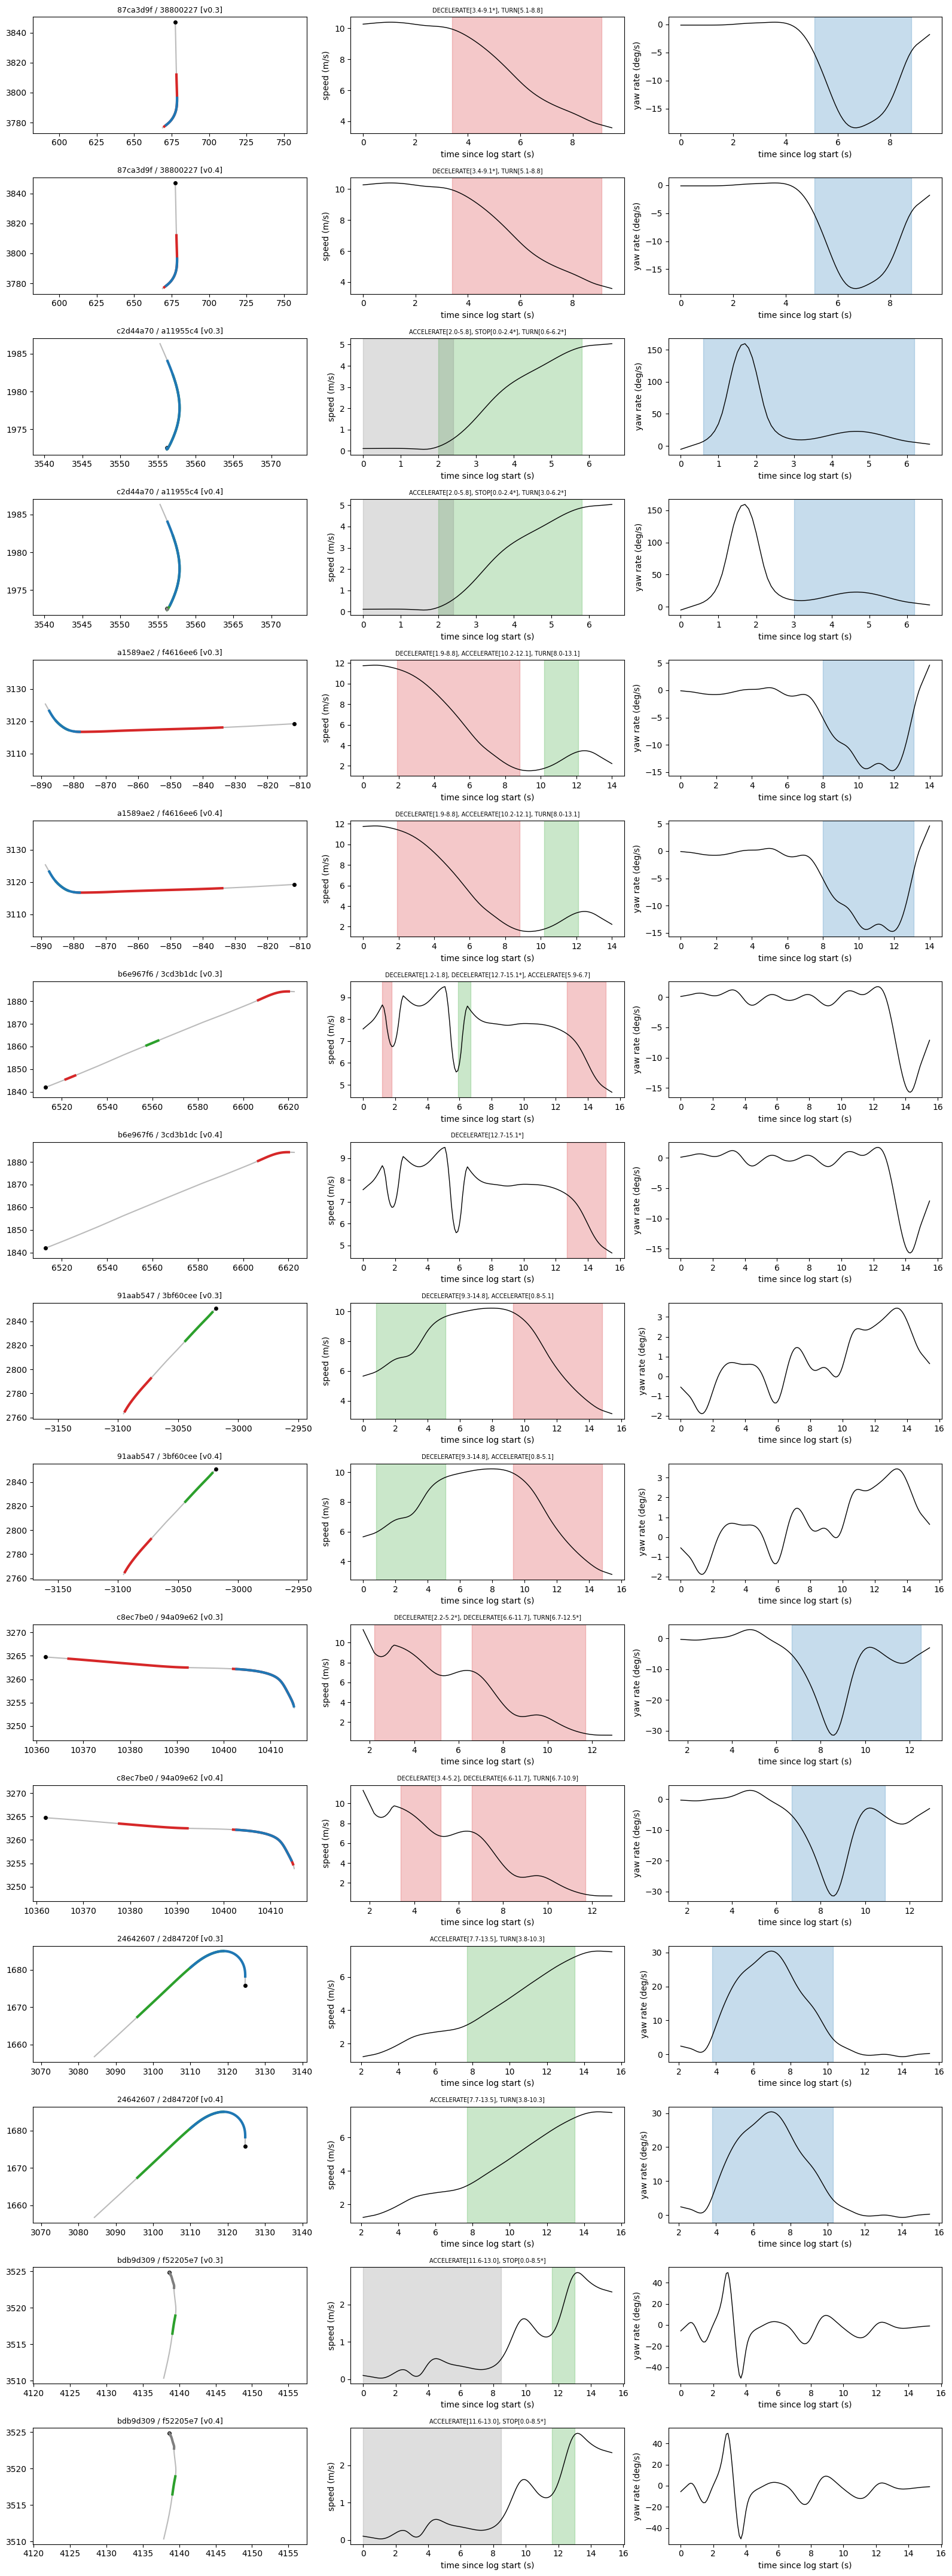

In [ ]:
# [v0.4-3] 같은 트랙의 v0.3(위) / v0.4(아래) 비교 그림
N_CMP = 8
if "chosen" in globals() and chosen:
    cmp_keys = list(chosen)[:N_CMP]
else:
    rng = np.random.default_rng(0)
    pool = sorted({e.track_key for e in events})
    cmp_keys = [pool[i] for i in rng.permutation(len(pool))[:N_CMP]]
te3 = defaultdict(list)
for e in events:
    te3[e.track_key].append(e)

fig, axes = plt.subplots(2 * len(cmp_keys), 3, figsize=(16, 2.7 * 2 * len(cmp_keys)), squeeze=False)
for i, key in enumerate(cmp_keys):
    for row, (tag, tev, sig) in enumerate((("[v0.3]", te3, signals), ("[v0.4]", track_events4, signals4))):
        ax = axes[2 * i + row]
        if key in sig:
            T.plot_track(key, tev.get(key, []), sig[key], ax, tag)
        else:
            for a in ax:
                a.axis("off")
            ax[0].text(0.05, 0.5, f"{tag} not evaluated", transform=ax[0].transAxes)
fig.tight_layout()
fig.savefig(OUT4 / "detector_v03_vs_v04.png", dpi=90)
plt.show()

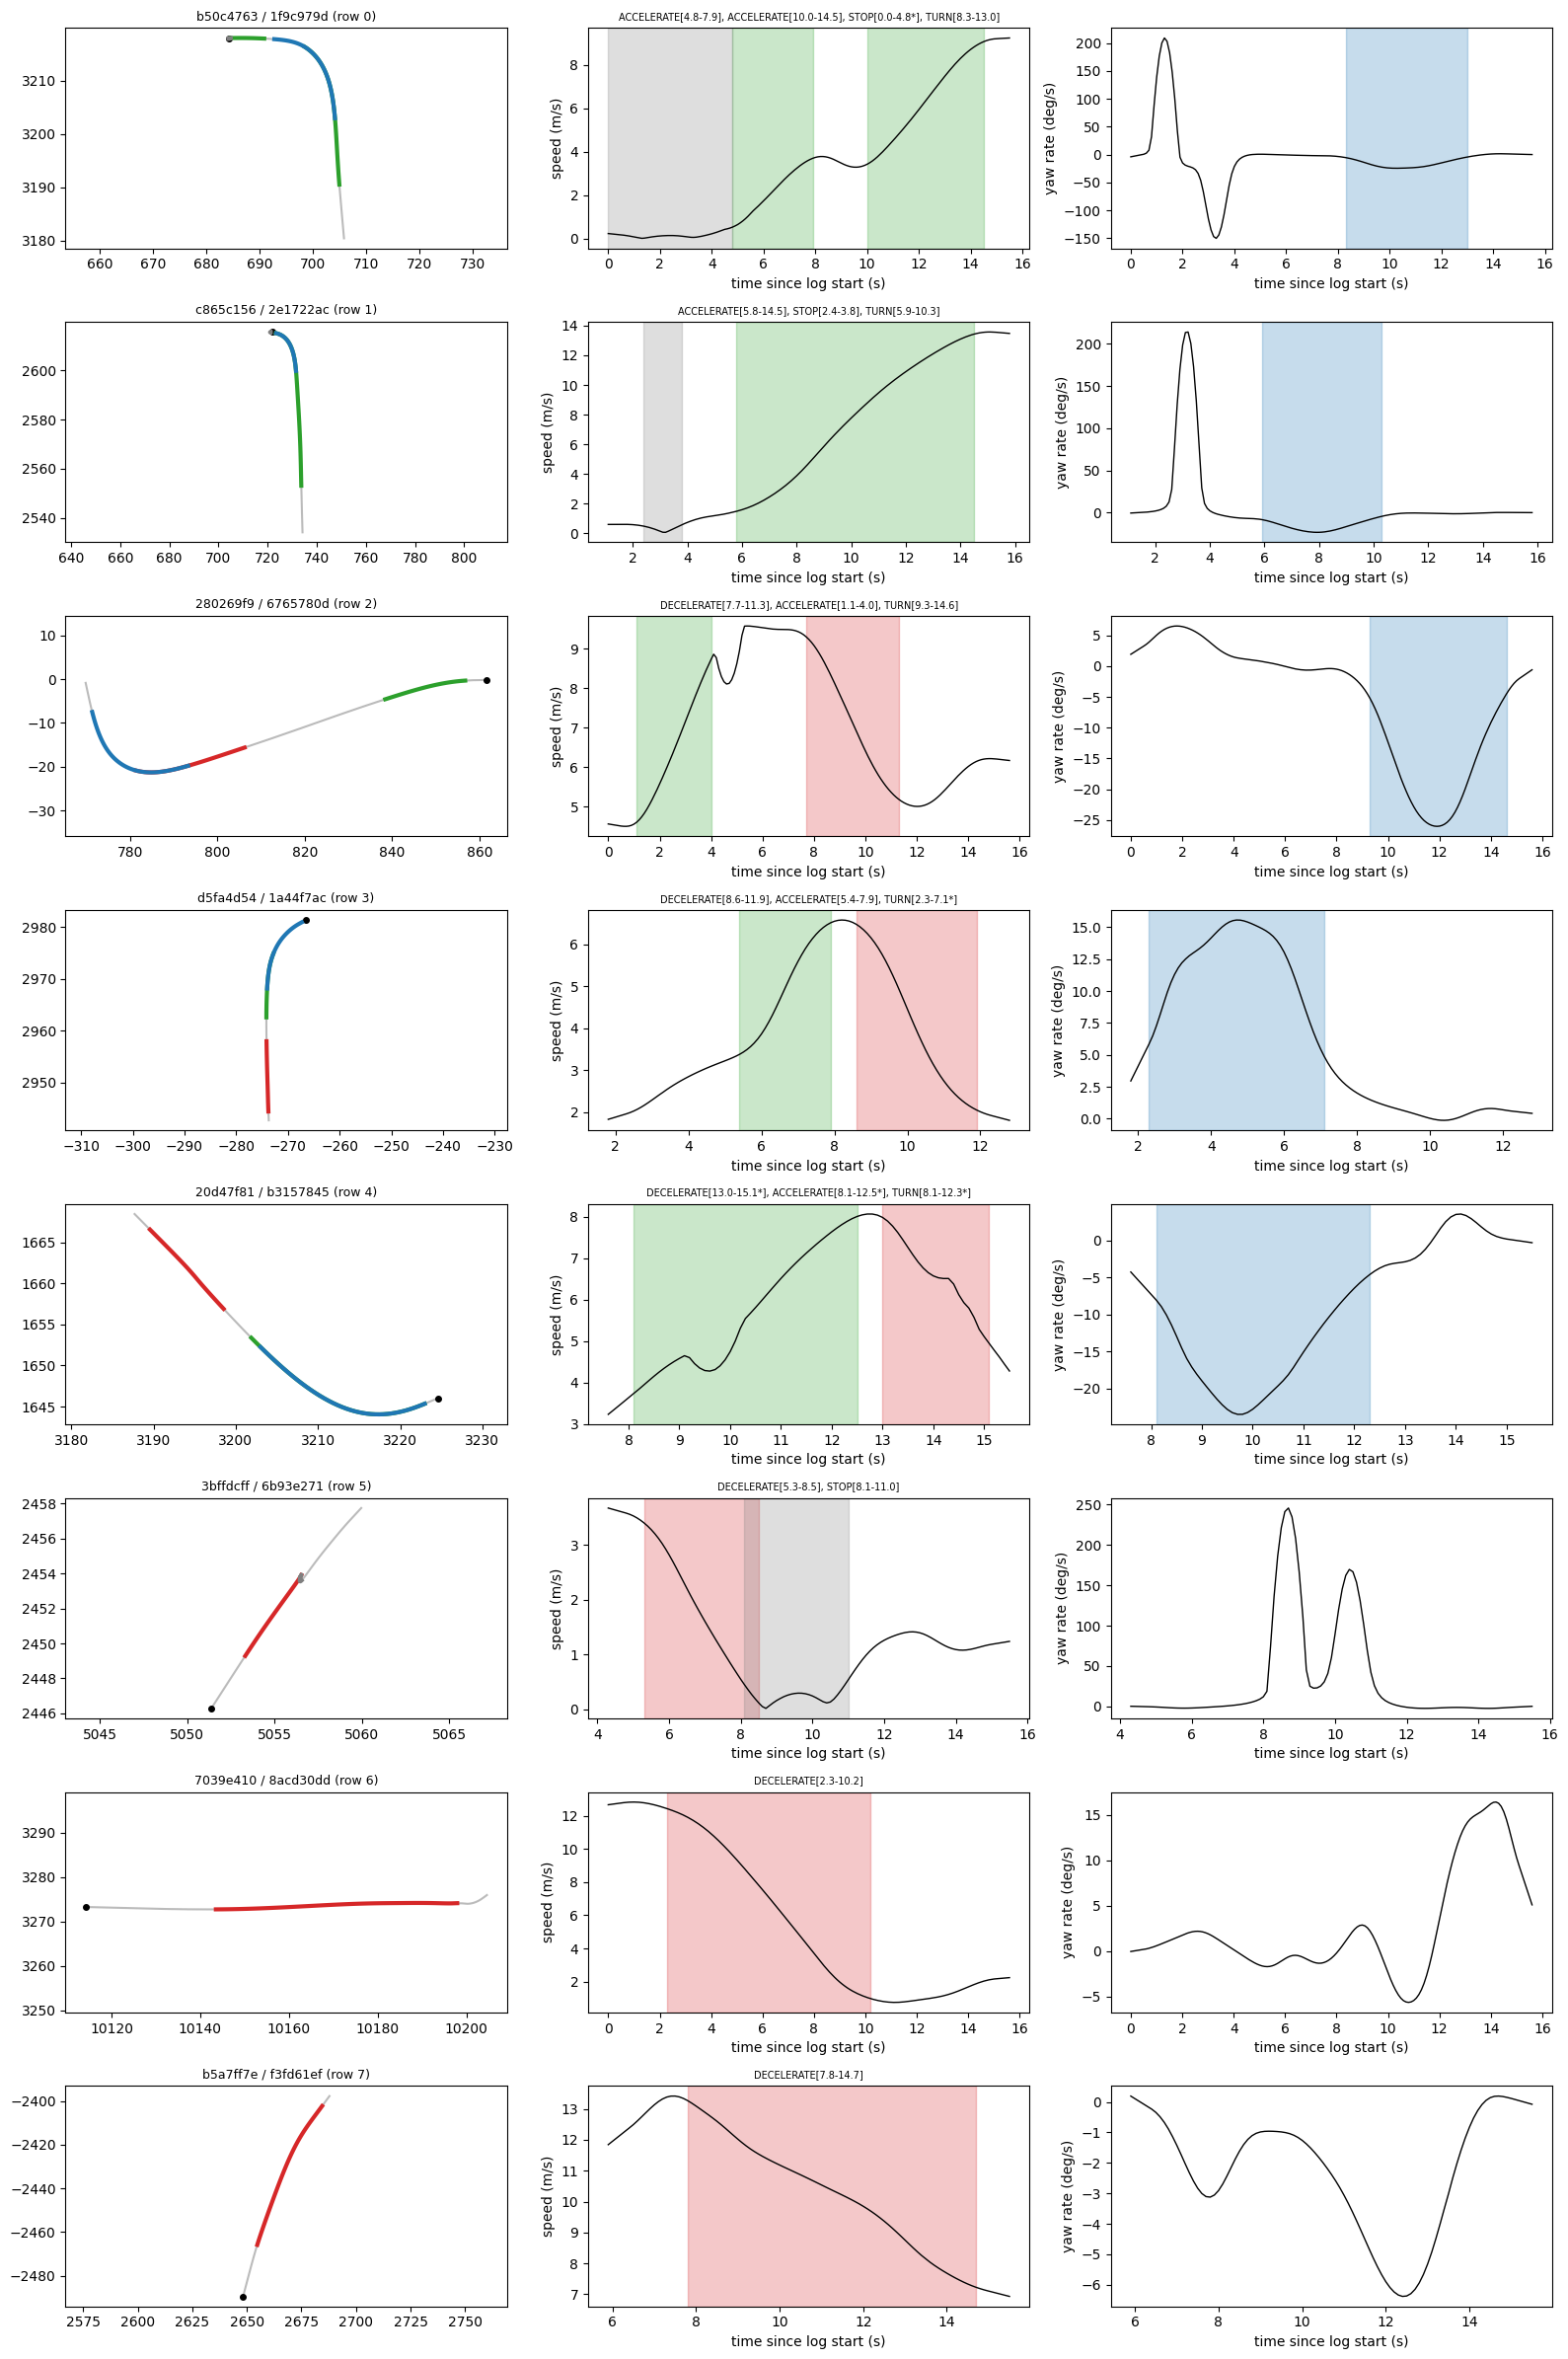

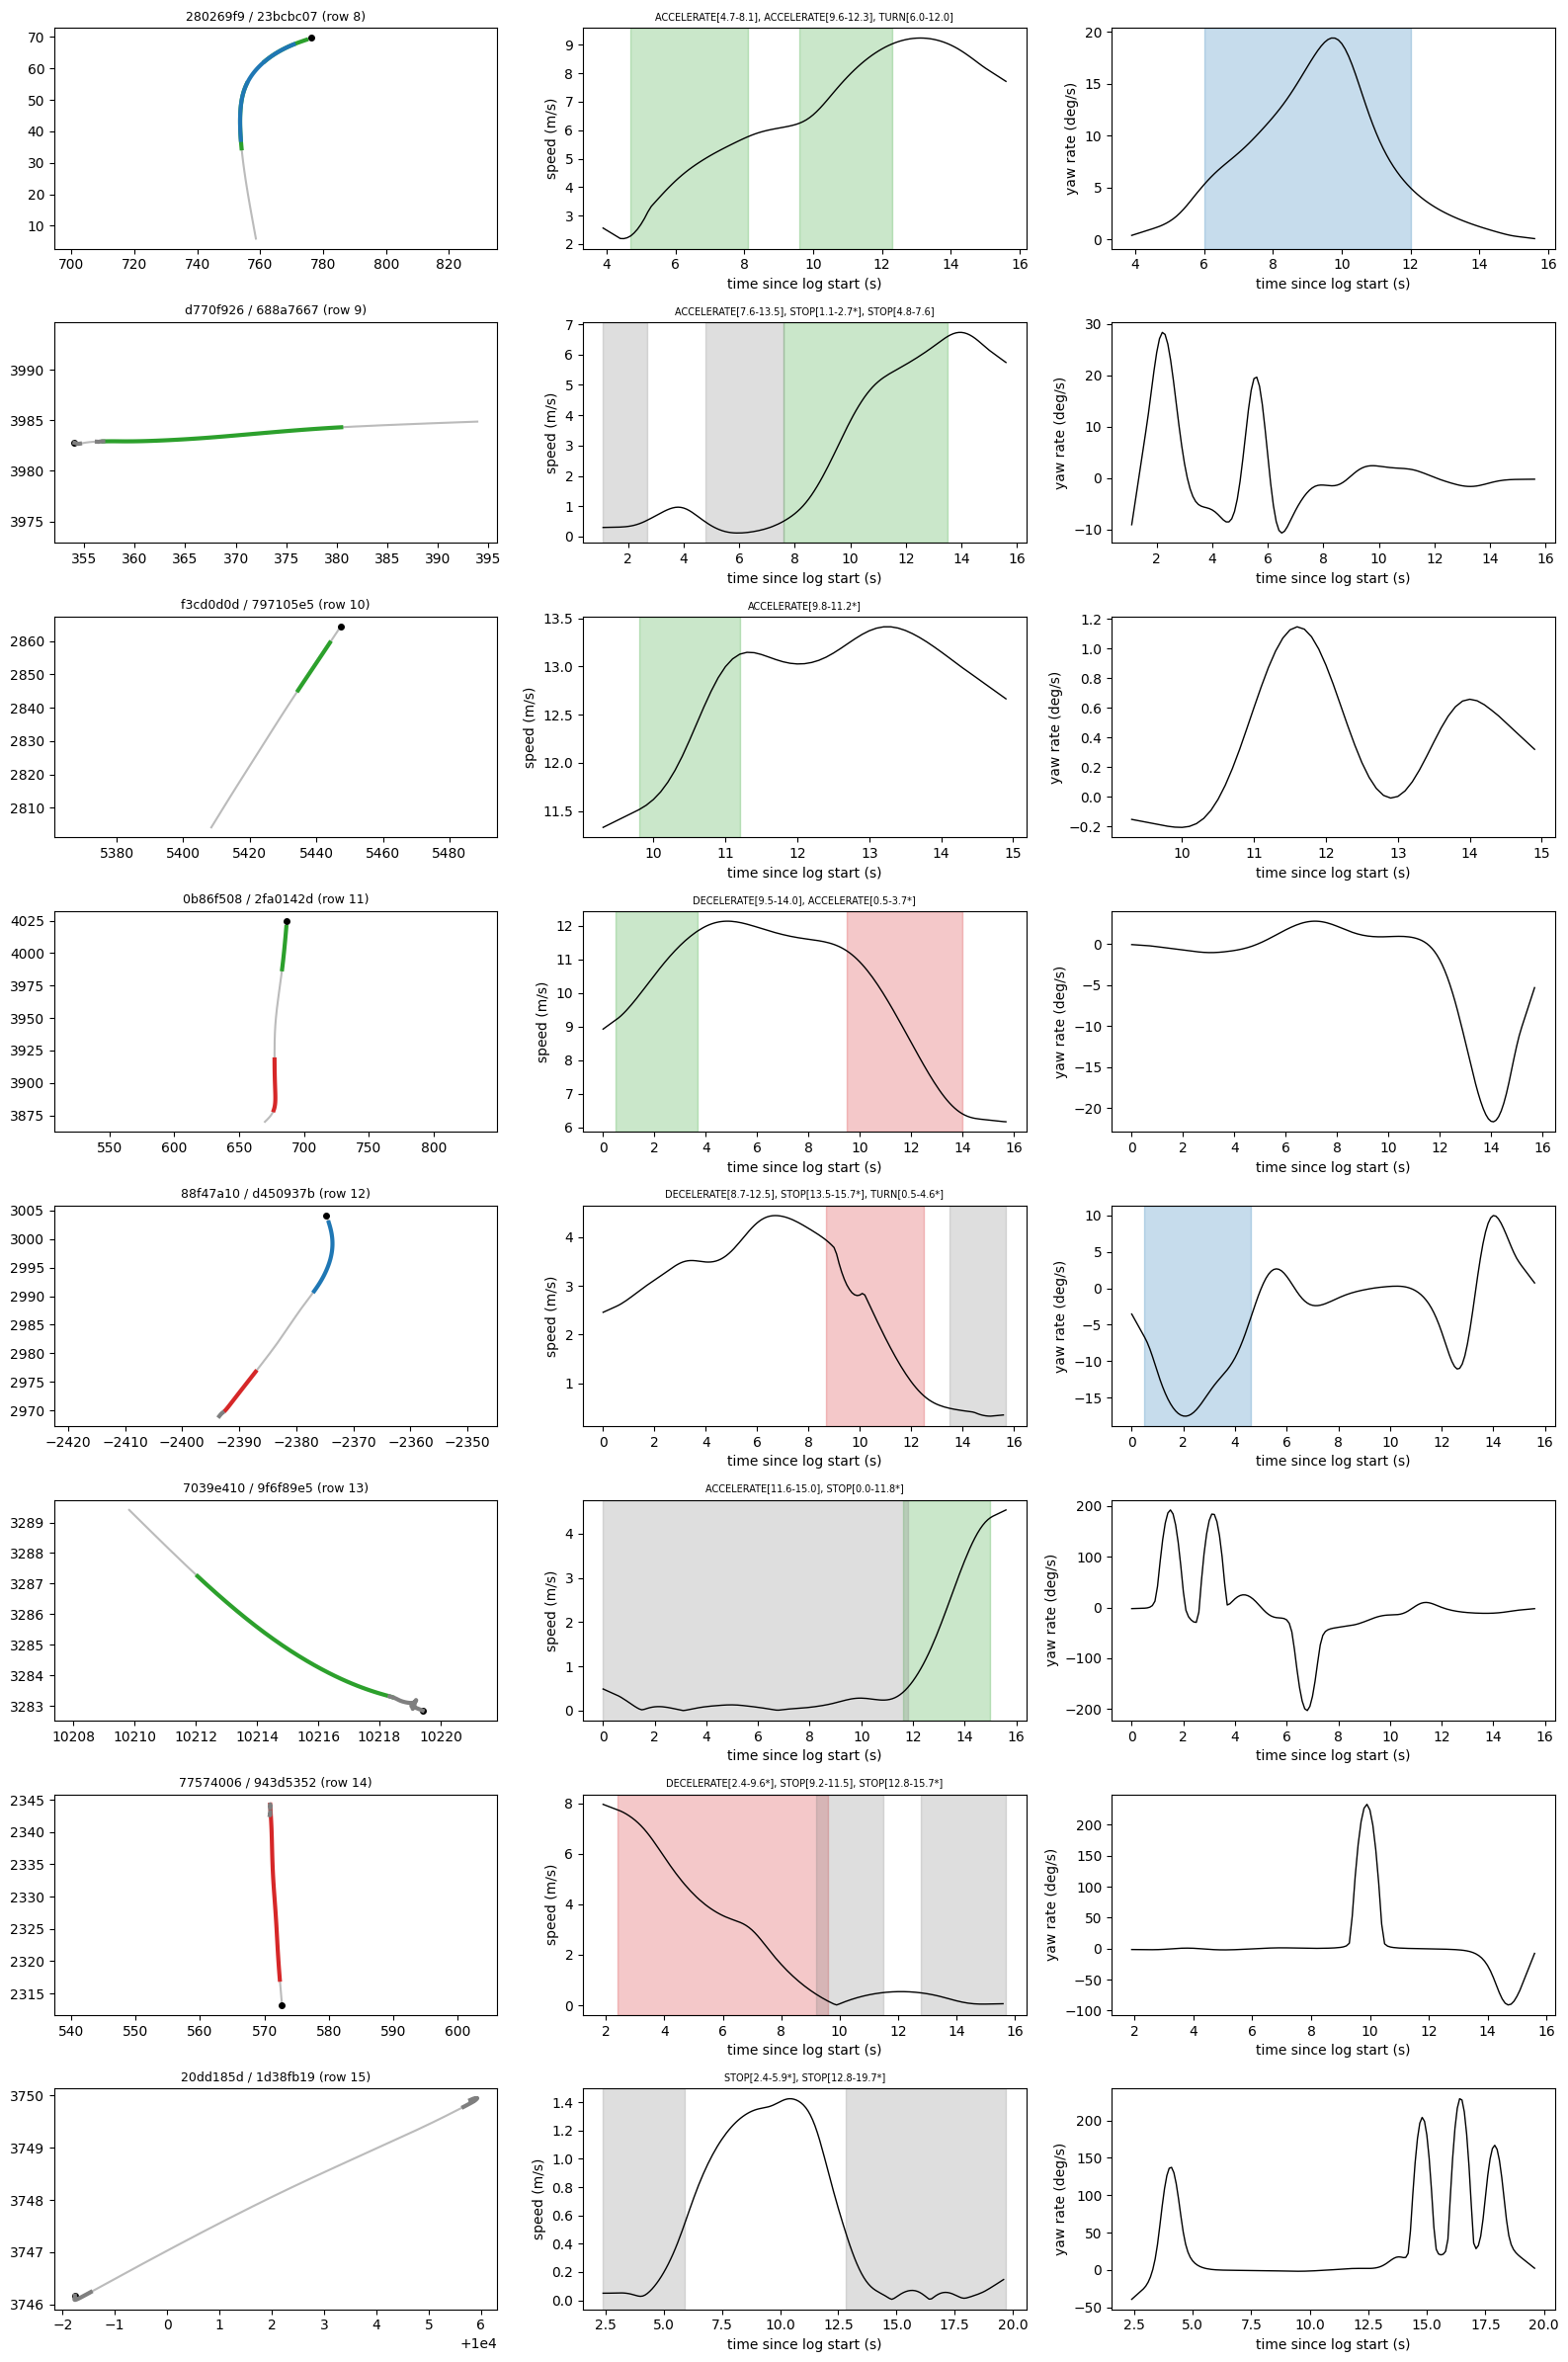

확인할 사건 39개. 아래 번호 순서대로 다음 셀의 VERDICTS에 O/X를 입력하십시오.


,no,figure_row,type,start,end,clipped
0,0,0,STOP,0.0,4.8,True
1,1,0,ACCELERATE,4.8,7.9,False
2,2,0,TURN,8.3,13.0,False
3,3,0,ACCELERATE,10.0,14.5,False
4,4,1,STOP,2.4,3.8,False
5,5,1,ACCELERATE,5.8,14.5,False
6,6,1,TURN,5.9,10.3,False
7,7,2,ACCELERATE,1.1,4.0,False
8,8,2,DECELERATE,7.7,11.3,False
9,9,2,TURN,9.3,14.6,False


In [ ]:
# [v0.4-4] v0.4 수동 확인용 표본 (유형별 4개 트랙) — 그림과 번호 목록 출력
PER_TYPE = 4
rng = np.random.default_rng(42)
manual_keys = []
for typ in T.EVENT_TYPES:
    pool = sorted({e.track_key for e in events4 if e.type == typ} - set(manual_keys))
    manual_keys += [pool[i] for i in rng.permutation(len(pool))[:PER_TYPE]]

for start in range(0, len(manual_keys), 8):
    keys = manual_keys[start:start + 8]
    fig, axes = plt.subplots(len(keys), 3, figsize=(16, 3.0 * len(keys)), squeeze=False)
    for j, key in enumerate(keys):
        T.plot_track(key, track_events4[key], signals4[key], axes[j], f"(row {start + j})")
    fig.tight_layout()
    fig.savefig(OUT4 / f"manual_check_rows_{start:02d}.png", dpi=100)
    plt.show()

manual_rows = []
for r, key in enumerate(manual_keys):
    for e in sorted(track_events4[key], key=lambda e: e.start):
        manual_rows.append({"no": len(manual_rows), "figure_row": r, "type": e.type,
                            "start": round(e.start, 1), "end": round(e.end, 1), "clipped": e.clipped,
                            "log_id": e.log_id, "track_id": e.track_id, "event_id": e.event_id})
manual4 = pd.DataFrame(manual_rows)
manual4.to_csv(OUT4 / "manual_event_check_v04.csv", index=False)
print(f"확인할 사건 {len(manual4)}개. 아래 번호 순서대로 다음 셀의 VERDICTS에 O/X를 입력하십시오.")
display(manual4[["no", "figure_row", "type", "start", "end", "clipped"]])

In [ ]:
# [v0.4-5] 검출 정밀도 계산 — 위 그림을 보고 VERDICTS를 채운 뒤 실행
# 번호(no) 순서대로 O(맞음) / X(틀림) / ?(판단 불가)를 공백 없이 입력. 예: "OOXO?O..."
VERDICTS = ""

v = list(VERDICTS.strip().upper())
if len(v) != len(manual4):
    print(f"입력 길이 {len(v)} ≠ 사건 수 {len(manual4)}. VERDICTS를 채운 뒤 다시 실행하십시오.")
else:
    manual4["verdict"] = v
    manual4.to_csv(OUT4 / "manual_event_check_v04.csv", index=False)
    judged = manual4[manual4.verdict.isin(["O", "X"])]
    prec = []
    for typ, g in list(judged.groupby("type")) + [("ALL", judged)]:
        k, n = int((g.verdict == "O").sum()), len(g)
        lo, hi = N.wilson(k, n)
        prec.append({"type": typ, "correct": k, "judged": n, "precision": round(k / n, 3) if n else None,
                     "95%CI": f"[{lo:.2f}, {hi:.2f}]"})
    precision4 = pd.DataFrame(prec)
    precision4.to_csv(OUT4 / "detector_precision_v04.csv", index=False)
    display(precision4)
    print("판단 불가(?):", int((manual4.verdict == "?").sum()))

입력 길이 0 ≠ 사건 수 39. VERDICTS를 채운 뒤 다시 실행하십시오.


In [ ]:
# [v0.4-6] v0.4 그래프로 Graph Query Execution 재검증 + 임계값 민감도
exec4, _ = T.verify_and_benchmark(events4, universe4, T.all_queries(), repeat=30)
for k in ("all_status_equal", "all_retrieval_equal", "graph_build_ms_median", "graph_retained_memory_kib",
          "retrieval_latency_interval_ms_mean", "retrieval_latency_graph_ms_mean", "break_even_query_count"):
    print(f"{k}: {exec4[k]}")
assert exec4["all_status_equal"] and exec4["all_retrieval_equal"], "두 실행기 불일치"
q4 = pd.DataFrame(exec4["per_query"])[["query", "matches", "positive_tracks", "uncertain_tracks", "partial_tracks"]]
display(q4[q4.matches > 0])

core = [T.Query("DECELERATE", "THEN", "TURN"), T.Query("TURN", "THEN", "DECELERATE"),
        T.Query("DECELERATE", "WHILE", "TURN"), T.Query("DECELERATE", "THEN", "STOP"),
        T.Query("STOP", "THEN", "ACCELERATE"), T.Query("ACCELERATE", "WHILE", "TURN")]
sens = []
for gap in (3.0, 5.0, 7.0):
    for ratio in (0.6, 0.8, 1.0):
        gx = T.GraphQueryExecutor(T.TemporalEventGraph(events4, universe4,
                                                       T.RelationConfig(then_max_gap_s=gap, while_min_ratio=ratio)))
        for q in core:
            st = pd.Series(gx.statuses(q)).value_counts()
            sens.append({"gap": gap, "ratio": ratio, "query": str(q), "positive": int(st.get("POSITIVE", 0))})
sens4 = pd.DataFrame(sens)
sens4.to_csv(OUT4 / "threshold_sensitivity.csv", index=False)
display(sens4.pivot_table(index="query", columns=["gap", "ratio"], values="positive"))

all_status_equal: True
all_retrieval_equal: True
graph_build_ms_median: 500.843
graph_retained_memory_kib: 784.2
retrieval_latency_interval_ms_mean: 31.24117
retrieval_latency_graph_ms_mean: 0.10821
break_even_query_count: 17


,query,matches,positive_tracks,uncertain_tracks,partial_tracks
0,TURN THEN TURN,1,1,0,0
1,TURN THEN DECELERATE,33,33,0,51
2,TURN THEN ACCELERATE,7,7,0,84
3,TURN THEN STOP,4,4,0,0
5,TURN WHILE DECELERATE,23,23,1,53
6,TURN WHILE ACCELERATE,87,87,13,72
8,DECELERATE THEN TURN,21,21,0,54
9,DECELERATE THEN DECELERATE,71,70,0,0
10,DECELERATE THEN ACCELERATE,142,140,0,0
11,DECELERATE THEN STOP,288,266,0,30


gap                      3.0                  5.0                  7.0         \
ratio                    0.6    0.8    1.0    0.6    0.8    1.0    0.6    0.8   
query                                                                           
ACCELERATE WHILE TURN  126.0   87.0   52.0  126.0   87.0   52.0  126.0   87.0   
DECELERATE THEN STOP   254.0  254.0  254.0  266.0  266.0  266.0  268.0  268.0   
DECELERATE THEN TURN    21.0   21.0   21.0   21.0   21.0   21.0   21.0   21.0   
DECELERATE WHILE TURN   36.0   23.0   14.0   36.0   23.0   14.0   36.0   23.0   
STOP THEN ACCELERATE   253.0  253.0  253.0  266.0  266.0  266.0  274.0  274.0   
TURN THEN DECELERATE    23.0   23.0   23.0   33.0   33.0   33.0   39.0   39.0   

gap                           
ratio                    1.0  
query                         
ACCELERATE WHILE TURN   52.0  
DECELERATE THEN STOP   268.0  
DECELERATE THEN TURN    21.0  
DECELERATE WHILE TURN   14.0  
STOP THEN ACCELERATE   274.0  
TURN THEN DECELERATE    39.0

In [ ]:
# [v0.4-7] 확장 진단 문장(288개) + 역균형 예시 + 관대 채점 함수
EVAL_PHRASES = {   # 평가 문장 전용 표현 (예시 문장과 겹치지 않음)
    "DECELERATE": [("slows down", "slowing down"), ("reduces its speed", "reducing its speed")],
    "TURN": [("turns", "turning"), ("takes a turn", "taking a turn")],
    "ACCELERATE": [("speeds up", "speeding up"), ("accelerates", "accelerating")],
    "STOP": [("stops", "stopping"), ("comes to a stop", "coming to a stop")],
}


def build_diag_v04():
    rows = []

    def fill(pattern, a, b, va, vb):
        A, B = EVAL_PHRASES[a][va], EVAL_PHRASES[b][vb]
        return pattern.format(A_fin=A[0], A_ger=A[1], B_fin=B[0], B_ger=B[1])

    def add(tid, cond, sentence, plan, va, vb):
        q = T.parse_tqp(plan)
        rows.append({"template": tid, "connective": N.CONNECTIVE[tid], "condition": cond, "sentence": sentence,
                     "gold_tqp": json.dumps(plan), "first_mentioned": plan["events"]["e1"],
                     "gold_first": q.first, "gold_relation": q.relation, "gold_second": q.second,
                     "verbs": f"{va}{vb}", "pair": "+".join(sorted((q.first, q.second)))})

    for tid, pattern, order, cond in N.THEN_TEMPLATES:
        for a in T.EVENT_TYPES:
            for b in T.EVENT_TYPES:
                if a == b:
                    continue
                for va in (0, 1):
                    for vb in (0, 1):
                        add(tid, cond, fill(pattern, a, b, va, vb), N.gold_tqp(a, b, "THEN", order), va, vb)
    for tid, pattern in N.WHILE_TEMPLATES:
        for a, b in N.WHILE_PAIRS:
            for va in (0, 1):
                for vb in (0, 1):
                    add(tid, "simultaneous", fill(pattern, a, b, va, vb), N.gold_tqp(a, b, "WHILE", ("A", "B")), va, vb)
    return pd.DataFrame(rows)


# 같은 사건 쌍(감속+회전, 가속+회전)이 THEN과 WHILE 양쪽에 등장하도록 구성. 예시 전용 표현만 사용.
FEW_SHOT_CB = [
    ("A vehicle brakes while making a turn.",
     {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "WHILE", "args": ["e1", "e2"]}}),
    ("A vehicle makes a turn after braking.",
     {"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("Before making a turn, a vehicle picks up speed.",
     {"events": {"e1": "TURN", "e2": "ACCELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("A vehicle picks up speed while making a turn.",
     {"events": {"e1": "ACCELERATE", "e2": "TURN"}, "relation": {"op": "WHILE", "args": ["e1", "e2"]}}),
    ("A vehicle comes to a halt and then picks up speed.",
     {"events": {"e1": "STOP", "e2": "ACCELERATE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}),
    ("A vehicle brakes before coming to a halt.",
     {"events": {"e1": "DECELERATE", "e2": "STOP"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}),
]
for _, plan in FEW_SHOT_CB:
    T.parse_tqp(plan)
N.VARIANTS["counterbalanced"] = {"tqp_system": N.TQP_SYSTEM_V2, "examples": FEW_SHOT_CB}

diag4 = build_diag_v04()
_example_words = ["brak", "make a turn", "makes a turn", "making a turn", "picks up speed", "picking up speed", "halt"]
_all_examples = {s for v in N.VARIANTS.values() for s, _ in v["examples"]}
assert not (_all_examples & set(diag4.sentence)), "예시 문장이 평가 문장에 섞였습니다."
assert not any(w in s for s in diag4.sentence for w in _example_words), "예시 전용 표현이 평가 문장에 섞였습니다."
print("진단 문장:", len(diag4), dict(diag4.gold_relation.value_counts()), dict(diag4.condition.value_counts()))
display(diag4.sample(8, random_state=0)[["sentence", "gold_first", "gold_relation", "gold_second"]])

_KEYWORDS = [("DECELERATE", ("slow", "decel", "brak", "reduc")), ("ACCELERATE", ("speed", "accel")),
             ("STOP", ("stop", "halt")), ("TURN", ("turn",))]


def lenient_query(text):
    """엄격 파싱이 실패하면 args에 들어간 사건 이름·단어를 사건 유형으로 대응시켜 해석."""
    q, plan, _ = N.parse_prediction(text)
    if q is not None:
        return q
    if not isinstance(plan, dict):
        return None
    ev, rel = plan.get("events"), plan.get("relation")
    if not isinstance(ev, dict) or not isinstance(rel, dict):
        return None
    args = rel.get("args")
    if not isinstance(args, list) or len(args) != 2 or rel.get("op") not in T.RELATIONS:
        return None

    def to_type(a):
        if a in ev and ev[a] in T.EVENT_TYPES:
            return ev[a]
        if a in T.EVENT_TYPES:
            return a
        s = str(a).lower()
        for typ, kws in _KEYWORDS:
            if any(k in s for k in kws):
                return typ
        return None

    f, s = to_type(args[0]), to_type(args[1])
    if f is None or s is None or f == s:
        return None
    return T.Query(f, rel["op"], s)

진단 문장: 288 {'THEN': np.int64(240), 'WHILE': np.int64(48)} {'congruent': np.int64(144), 'incongruent': np.int64(96), 'simultaneous': np.int64(48)}


,sentence,gold_first,gold_relation,gold_second
55,A vehicle takes a turn after accelerating.,ACCELERATE,THEN,TURN
182,"After coming to a stop, a vehicle turns.",STOP,THEN,TURN
92,A vehicle stops after speeding up.,ACCELERATE,THEN,STOP
208,A vehicle slows down and then speeds up.,DECELERATE,THEN,ACCELERATE
278,A vehicle takes a turn as it slows down.,TURN,WHILE,DECELERATE
45,A vehicle stops before accelerating.,STOP,THEN,ACCELERATE
111,"Before reducing its speed, a vehicle takes a turn.",TURN,THEN,DECELERATE
240,A vehicle slows down while turning.,DECELERATE,WHILE,TURN


In [ ]:
# [v0.4-8] P / B2 생성 (변형 3종 × 288문장). T4 기준 약 15~25분
V4_VARIANTS = ["zero_shot", "balanced", "counterbalanced"]
RUN_B2_V4 = True
B2_TOKENS = globals().get("B2_MAX_NEW_TOKENS", 384)
BATCH = globals().get("LLM_BATCH_SIZE", 16)

if not all(n in globals() for n in ("model", "tok", "device")):
    model, tok, device = N.load_model(globals().get("LLM_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct"))
golds4 = [T.Query(r.gold_first, r.gold_relation, r.gold_second) for r in diag4.itertuples()]
_probe_cache = {}
probes4 = [_probe_cache.setdefault(g, N.build_probes(g)) for g in golds4]


def b2_pred_str(g, inferred):
    return {"THEN_XY": f"{g.first} THEN {g.second}", "THEN_YX": f"{g.second} THEN {g.first}",
            "WHILE": f"{g.first} WHILE {g.second}"}.get(inferred, inferred)


rows4, gen4 = [], []
for variant in V4_VARIANTS:
    outs, sec = N.generate(model, tok, device, [N.tqp_messages(s, variant) for s in diag4.sentence],
                           batch_size=BATCH, max_new_tokens=96)
    gen4.append({"variant": variant, "method": "P (TQP)", "seconds": round(sec, 1)})
    for (_, r), g, pr, text in zip(diag4.iterrows(), golds4, probes4, outs):
        pred, plan, err = N.parse_prediction(text)
        lq = lenient_query(text)
        rows4.append({**r.to_dict(), "variant": variant, "method": "P (TQP)", "raw_output": text,
                      "pred": str(pred) if pred else None, "error": err,
                      "pred_lenient": str(lq) if lq else None, "exact_lenient": N.score_tqp(g, lq)["exact"],
                      **N.score_tqp(g, pred), **N.probe_score(g, N.tqp_probe_accepts(pred, pr), pr)})
    print(f"{variant} / P: {sec:.0f}s")
    if RUN_B2_V4:
        outs, sec = N.generate(model, tok, device, [N.b2_messages(s, variant) for s in diag4.sentence],
                               batch_size=BATCH, max_new_tokens=B2_TOKENS)
        gen4.append({"variant": variant, "method": "B2 (Python)", "seconds": round(sec, 1)})
        for (_, r), g, pr, text in zip(diag4.iterrows(), golds4, probes4, outs):
            accepts, err = N.run_b2(text, pr)
            inferred = N.infer_from_accepts(accepts) if accepts else None
            sc = N.score_b2(g, accepts)
            rows4.append({**r.to_dict(), "variant": variant, "method": "B2 (Python)", "raw_output": text,
                          "pred": b2_pred_str(g, inferred) if inferred else None, "error": err,
                          "pred_lenient": None, "exact_lenient": sc["exact"],
                          **sc, **N.probe_score(g, accepts, pr)})
        print(f"{variant} / B2: {sec:.0f}s")
    pd.DataFrame(rows4).to_csv(OUT4 / "llm_predictions_v04.csv", index=False)   # 변형마다 중간 저장
res4 = pd.DataFrame(rows4)
display(pd.DataFrame(gen4))

zero_shot / P: 44s
zero_shot / B2: 304s
balanced / P: 55s
balanced / B2: 166s
counterbalanced / P: 62s
counterbalanced / B2: 204s


,variant,method,seconds
0,zero_shot,P (TQP),44.4
1,zero_shot,B2 (Python),303.7
2,balanced,P (TQP),54.9
3,balanced,B2 (Python),165.8
4,counterbalanced,P (TQP),61.9
5,counterbalanced,B2 (Python),204.0


In [ ]:
# [v0.4-9] 분석: 전체 / 엄격·관대 / McNemar(Holm) / 지름길 / 접속사×어순 / 표현 변형
pd.set_option("display.max_colwidth", 160)
res4["pred_rel"] = res4.pred.where(res4.pred.notna(), "").str.split().str[1]

print("[1] 전체 정확도 (엄격 채점)")
overall4 = N.summarize(res4, ["variant", "method"])
overall4["exact_lenient"] = res4.groupby(["variant", "method"]).exact_lenient.mean().round(3)
display(overall4)

print("\n[2] P 대 B2 — 정확 McNemar, Holm 보정")
mc4 = []
for variant in V4_VARIANTS:
    p = res4[(res4.variant == variant) & (res4.method == "P (TQP)")].set_index("sentence").exact
    b = res4[(res4.variant == variant) & (res4.method == "B2 (Python)")].set_index("sentence").exact.reindex(p.index)
    if b.notna().all():
        mc4.append({"variant": variant, "P": round(p.mean(), 3), "B2": round(b.mean(), 3),
                    **N.mcnemar_exact(p.tolist(), b.astype(bool).tolist())})
mc4 = pd.DataFrame(mc4)
if len(mc4):
    order_ = mc4.p_value.sort_values().index
    m_ = len(mc4)
    adj, running = {}, 0.0
    for rank, idx in enumerate(order_):
        running = max(running, min(1.0, (m_ - rank) * mc4.loc[idx, "p_value"]))
        adj[idx] = round(running, 4)
    mc4["p_holm"] = pd.Series(adj)
    display(mc4)

print("\n[3] 예시 복사(지름길) 점검: 회전이 포함된 쌍의 관계 정확도 (정답 관계별)")
turn_pairs = res4[res4.pair.isin(["ACCELERATE+TURN", "DECELERATE+TURN"])]
display(turn_pairs.groupby(["variant", "method", "pair", "gold_relation"]).relation_correct
        .agg(lambda s: f"{s.mean():.2f} ({len(s)})").unstack(["pair", "gold_relation"]))

print("\n[4] 접속사 × 어순: exact 정확도 (n)")
display(res4.groupby(["variant", "method", "connective", "condition"]).exact
        .agg(lambda s: f"{s.mean():.2f} ({len(s)})").unstack(["connective", "condition"]))

print("\n[5] 같은 접속사 안에서 어순 효과 (Fisher 정확검정)")
fx = []
for (variant, method), g in res4.groupby(["variant", "method"]):
    for conn in ("before", "after"):
        c = g[(g.connective == conn) & (g.condition == "congruent")].exact
        i = g[(g.connective == conn) & (g.condition == "incongruent")].exact
        if len(c) and len(i):
            _, pv = fisher_exact([[int(c.sum()), len(c) - int(c.sum())], [int(i.sum()), len(i) - int(i.sum())]])
            fx.append({"variant": variant, "method": method, "connective": conn,
                       "congruent": f"{c.mean():.2f} ({len(c)})", "incongruent": f"{i.mean():.2f} ({len(i)})",
                       "p": round(pv, 4)})
display(pd.DataFrame(fx))

print("\n[6] 표현 변형 효과 (verbs: 00 = 기본 동사, 그 외 = 동의어 포함)")
display(res4.assign(base=res4.verbs == "00").groupby(["variant", "method", "base"]).exact.mean()
        .unstack("base").round(3))

print("\n[7] 오답 예시 (counterbalanced, 방법별 최대 10개)")
for method, g in res4[(res4.variant == "counterbalanced") & ~res4.exact].groupby("method"):
    print("---", method, f"(오답 {len(g)}개)")
    display(g[["sentence", "gold_first", "gold_relation", "gold_second", "pred", "error"]].head(10))

[1] 전체 정확도 (엄격 채점)


n  valid  relation_acc  direction_acc(THEN)  \
variant         method                                                       
balanced        B2 (Python)  288  1.000         0.875                0.892   
                P (TQP)      288  1.000         0.993                0.904   
counterbalanced B2 (Python)  288  1.000         0.802                0.871   
                P (TQP)      288  0.997         0.938                0.617   
zero_shot       B2 (Python)  288  0.656         0.122                0.071   
                P (TQP)      288  0.219         0.194                0.158   

                             exact_acc    exact_95CI  probe_exact  \
variant         method                                              
balanced        B2 (Python)      0.854  [0.81, 0.89]        0.854   
                P (TQP)          0.913  [0.88, 0.94]        0.913   
counterbalanced B2 (Python)      0.726  [0.67, 0.77]        0.726   
                P (TQP)          0.681  [0.62, 0.73]        0.681   
zero_shot       B2 (Python)      0.069  [0.04, 0.10]        0.017   
                P (TQP)          0.177  [0.14, 0.23]        0.177   

                             exact_lenient  
variant         method                      
balanced        B2 (Python)          0.854  
                P (TQP)              0.913  
counterbalanced B2 (Python)          0.726  
                P (TQP)              0.681  
zero_shot       B2 (Python)          0.069  
                P (TQP)              0.597


[2] P 대 B2 — 정확 McNemar, Holm 보정


,variant,P,B2,P_only_correct,B2_only_correct,p_value,p_holm
0,zero_shot,0.177,0.069,48,17,0.0002,0.0006
1,balanced,0.913,0.854,33,16,0.0213,0.0426
2,counterbalanced,0.681,0.726,57,70,0.2869,0.2869



[3] 예시 복사(지름길) 점검: 회전이 포함된 쌍의 관계 정확도 (정답 관계별)


pair                        ACCELERATE+TURN            DECELERATE+TURN  \
gold_relation                          THEN      WHILE            THEN   
variant         method                                                   
balanced        B2 (Python)       0.57 (40)  1.00 (24)       1.00 (40)   
                P (TQP)           1.00 (40)  1.00 (24)       1.00 (40)   
counterbalanced B2 (Python)       1.00 (40)  0.00 (24)       0.95 (40)   
                P (TQP)           0.93 (40)  1.00 (24)       0.85 (40)   
zero_shot       B2 (Python)       0.23 (40)  0.04 (24)       0.25 (40)   
                P (TQP)           0.57 (40)  0.33 (24)       0.10 (40)   

pair                                    
gold_relation                    WHILE  
variant         method                  
balanced        B2 (Python)  0.33 (24)  
                P (TQP)      0.92 (24)  
counterbalanced B2 (Python)  0.00 (24)  
                P (TQP)      1.00 (24)  
zero_shot       B2 (Python)  0.08 (24)  
                P (TQP)      0.21 (24)

... (6 outputs left out)


[7] 오답 예시 (counterbalanced, 방법별 최대 10개)
--- B2 (Python) (오답 79개)


,sentence,gold_first,gold_relation,gold_second,pred,error
1500,A vehicle slows down after turning.,TURN,THEN,DECELERATE,DECELERATE THEN TURN,None
1501,A vehicle slows down after taking a turn.,TURN,THEN,DECELERATE,DECELERATE THEN TURN,None
1502,A vehicle reduces its speed after turning.,TURN,THEN,DECELERATE,DECELERATE THEN TURN,None
1503,A vehicle reduces its speed after taking a turn.,TURN,THEN,DECELERATE,DECELERATE THEN TURN,None
1509,A vehicle slows down after coming to a stop.,STOP,THEN,DECELERATE,DECELERATE THEN STOP,None
1512,A vehicle speeds up after turning.,TURN,THEN,ACCELERATE,ACCELERATE THEN TURN,None
1513,A vehicle speeds up after taking a turn.,TURN,THEN,ACCELERATE,ACCELERATE THEN TURN,None
1514,A vehicle accelerates after turning.,TURN,THEN,ACCELERATE,ACCELERATE THEN TURN,None
1515,A vehicle accelerates after taking a turn.,TURN,THEN,ACCELERATE,ACCELERATE THEN TURN,None
1517,A vehicle speeds up after reducing its speed.,DECELERATE,THEN,ACCELERATE,ACCELERATE THEN DECELERATE,None


--- P (TQP) (오답 92개)


,sentence,gold_first,gold_relation,gold_second,pred,error
1167,A vehicle reduces its speed before taking a turn.,DECELERATE,THEN,TURN,ACCELERATE THEN TURN,None
1170,A vehicle reduces its speed before speeding up.,DECELERATE,THEN,ACCELERATE,ACCELERATE THEN DECELERATE,None
1190,A vehicle comes to a stop before turning.,STOP,THEN,TURN,TURN THEN STOP,None
1191,A vehicle comes to a stop before taking a turn.,STOP,THEN,TURN,TURN THEN STOP,None
1196,A vehicle stops before speeding up.,STOP,THEN,ACCELERATE,ACCELERATE THEN STOP,None
1197,A vehicle stops before accelerating.,STOP,THEN,ACCELERATE,ACCELERATE THEN STOP,None
1198,A vehicle comes to a stop before speeding up.,STOP,THEN,ACCELERATE,ACCELERATE THEN STOP,None
1199,A vehicle comes to a stop before accelerating.,STOP,THEN,ACCELERATE,ACCELERATE THEN STOP,None
1200,A vehicle turns after slowing down.,DECELERATE,THEN,TURN,TURN THEN DECELERATE,None
1201,A vehicle turns after reducing its speed.,DECELERATE,THEN,TURN,TURN THEN DECELERATE,None


In [ ]:
# [v0.4-10] End-to-end (v0.4 그래프) + 저장
e2e4 = []
for variant in V4_VARIANTS:
    sub = res4[(res4.variant == variant) & (res4.method == "P (TQP)")]
    for r, g in zip(sub.itertuples(), golds4):
        pred = T.Query(*r.pred.split()) if isinstance(r.pred, str) else None
        gt = {(m.log_id, m.track_id) for m in gexec4.retrieve(g)}
        pt = {(m.log_id, m.track_id) for m in gexec4.retrieve(pred)} if pred else set()
        u = gt | pt
        e2e4.append({"variant": variant, "sentence": r.sentence, "condition": r.condition, "gold_tracks": len(gt),
                     "pred_tracks": len(pt), "same_track_set": gt == pt,
                     "jaccard": len(gt & pt) / len(u) if u else 1.0})
e2e4 = pd.DataFrame(e2e4)
e2e4.to_csv(OUT4 / "end_to_end_v04.csv", index=False)
ne4 = e2e4[e2e4.gold_tracks > 0]
display(ne4.groupby("variant")[["same_track_set", "jaccard"]].mean().round(3).assign(n=ne4.groupby("variant").size()))

report4 = {
    "engine": T.VERSION + "+v0.4-cells", "detector_v04": asdict(DET_V04),
    "detector_quality": pd.DataFrame(quality4)[order].to_dict(),
    "detector_precision": precision4.to_dict("records") if "precision4" in globals() else "VERDICTS 미입력",
    "graph": gsum4, "graph_query_execution": {k: v for k, v in exec4.items() if k != "per_query"},
    "llm_generation": gen4, "llm_overall": overall4.reset_index().to_dict("records"),
    "mcnemar": mc4.to_dict("records"), "end_to_end": ne4.groupby("variant").same_track_set.mean().round(3).to_dict(),
}
(OUT4 / "report_v04.json").write_text(json.dumps(report4, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
archive4 = shutil.make_archive(str(OUT4), "zip", root_dir=OUT4)
if globals().get("DRIVE_MOUNTED"):
    dest = Path(DRIVE_ROOT) / RESULTS_DIR_NAME / OUT4.name
    shutil.copytree(OUT4, dest, dirs_exist_ok=True)
    print("Drive 저장:", dest)
print("결과 ZIP:", archive4)

,same_track_set,jaccard,n
variant,,,
balanced,0.913,0.914,288
counterbalanced,0.681,0.685,288
zero_shot,0.177,0.178,288


Drive 저장: /content/drive/MyDrive/AV2_TQP_TEG_Results/v04_val_20261016_045848
결과 ZIP: /content/tqp_teg_out/v04_val_20261016_045848.zip


In [ ]:
# [v0.4-5b] 검출 정밀도 수동 확인 — 사건을 하나씩 보고 버튼으로 판정 (진행 상황 자동 저장)
import ipywidgets as W
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

assert all(n in globals() for n in ("manual4", "track_events4", "signals4", "OUT4", "T", "N")), \
    "v0.4-1, v0.4-2, v0.4-4 셀을 먼저 실행하십시오."
LABEL_CSV = OUT4 / "manual_event_check_v04.csv"
DRIVE_DIR = (Path(DRIVE_ROOT) / RESULTS_DIR_NAME / OUT4.name) if globals().get("DRIVE_MOUNTED") else None

# 이전에 판정하던 파일이 있으면 이어서 진행
manual4["verdict"] = manual4["verdict"] if "verdict" in manual4 else ""
for src in [p for p in (LABEL_CSV, DRIVE_DIR and DRIVE_DIR / LABEL_CSV.name) if p and Path(p).exists()]:
    saved = pd.read_csv(src)
    if "verdict" in saved and len(saved) == len(manual4) and (saved.event_id.values == manual4.event_id.values).all():
        manual4["verdict"] = saved["verdict"]
manual4["verdict"] = manual4["verdict"].fillna("").astype(str).replace({"nan": ""})

_ev_by_id = {e.event_id: e for evs in track_events4.values() for e in evs}
state = {"i": next((i for i, v in enumerate(manual4.verdict) if v not in ("O", "X", "?")), len(manual4))}

CRITERIA = """
<b>판정 기준</b> (점선 = 판정 대상 사건 구간, 왼쪽 궤적의 굵은 회색 = 같은 구간)<br>
· <b>DECELERATE</b>: 구간 안에서 속력이 뚜렷하게 계속 줄어듦. 1초 안에 꺼졌다 회복하는 뾰족한 변화는 X<br>
· <b>ACCELERATE</b>: 구간 안에서 속력이 뚜렷하게 계속 늘어남. 뾰족한 변화는 X<br>
· <b>STOP</b>: 구간 내내 속력이 거의 0 (0.5 m/s 미만)<br>
· <b>TURN</b>: 왼쪽 궤적이 구간에서 눈에 띄게 휘어짐 (진행 방향 약 45도 이상 변화). 거의 정지 상태의 요 레이트 급변은 X<br>
· 유형이 맞고 시작·끝이 실제 행동과 대략 1초 이내로 맞으면 O. 궤적이 너무 흔들려 알 수 없으면 ?
"""


def save():
    manual4.to_csv(LABEL_CSV, index=False)
    if DRIVE_DIR is not None:
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        manual4.to_csv(DRIVE_DIR / LABEL_CSV.name, index=False)


def precision_table():
    judged = manual4[manual4.verdict.isin(["O", "X"])]
    rows = []
    for typ, g in list(judged.groupby("type")) + [("ALL", judged)]:
        k, n = int((g.verdict == "O").sum()), len(g)
        lo, hi = N.wilson(k, n)
        rows.append({"type": typ, "correct": k, "judged": n,
                     "precision": round(k / n, 3) if n else None, "95%CI": f"[{lo:.2f}, {hi:.2f}]"})
    df = pd.DataFrame(rows)
    df.to_csv(OUT4 / "detector_precision_v04.csv", index=False)
    if DRIVE_DIR is not None:
        df.to_csv(DRIVE_DIR / "detector_precision_v04.csv", index=False)
    globals()["precision4"] = df          # v0.4-10 보고서에 반영됨
    return df


out, progress = W.Output(), W.HTML()


def render():
    i = state["i"]
    done = int(manual4.verdict.isin(["O", "X", "?"]).sum())
    progress.value = f"<b>{min(i + 1, len(manual4))} / {len(manual4)}</b> &nbsp;·&nbsp; 판정 완료 {done}개"
    with out:
        clear_output(wait=True)
        if i >= len(manual4):
            print("모든 사건을 판정했습니다. 수정하려면 '← 이전'을 누르십시오.")
            display(precision_table())
            print("판단 불가(?):", int((manual4.verdict == "?").sum()))
            return
        row = manual4.iloc[i]
        e = _ev_by_id[row.event_id]
        key = e.track_key
        fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), squeeze=False)
        ax_xy, ax_v, ax_w = axes[0]
        T.plot_track(key, track_events4[key], signals4[key], axes[0], f"#{row.no}")
        for ax in (ax_v, ax_w):
            ax.axvline(e.start, color="black", lw=1.6, ls="--")
            ax.axvline(e.end, color="black", lw=1.6, ls="--")
        for seg in signals4[key]:
            m = (seg["t"] >= e.start) & (seg["t"] < e.end)
            if m.any():
                ax_xy.plot(seg["x"][m], seg["y"][m], color="black", lw=7, alpha=0.3, zorder=0)
        fig.suptitle(f"JUDGE #{row.no}: {e.type}  {e.start:.1f}-{e.end:.1f} s"
                     + ("  (clipped at observation edge)" if e.clipped else ""), fontsize=13, fontweight="bold")
        fig.tight_layout()
        plt.show()
        print(f"현재 판정: {row.verdict or '없음'}")


def mark(v):
    def handler(_):
        i = state["i"]
        if i < len(manual4):
            manual4.at[manual4.index[i], "verdict"] = v
            save()
            state["i"] = i + 1
            render()
    return handler


def move(step):
    def handler(_):
        state["i"] = min(max(0, state["i"] + step), len(manual4))
        render()
    return handler


buttons = []
for v, label, style in (("O", "O 맞음", "success"), ("X", "X 틀림", "danger"), ("?", "? 판단 불가", "warning")):
    b = W.Button(description=label, button_style=style, layout=W.Layout(width="130px"))
    b.on_click(mark(v))
    buttons.append(b)
b_prev = W.Button(description="← 이전", layout=W.Layout(width="100px"))
b_prev.on_click(move(-1))
b_skip = W.Button(description="건너뛰기 →", layout=W.Layout(width="110px"))
b_skip.on_click(move(+1))
b_result = W.Button(description="현재까지 정밀도 보기", layout=W.Layout(width="170px"))


def show_result(_):
    with out:
        clear_output(wait=True)
        display(precision_table())
        print("계속 판정하려면 '건너뛰기 →' 또는 '← 이전'을 누르십시오.")


b_result.on_click(show_result)

display(W.VBox([W.HTML(CRITERIA), progress, W.HBox([b_prev, *buttons, b_skip, b_result]), out]))
render()